# Motif-Scaffolding Benchmark — model comparison

**Run:** `lib_interface_pad5` · 5 generators × 314 interface motifs (base+filled) × AF3 monomer refold.

A **design is designable** if any of its refolded sequences hits **motifRMSD ≤ 1 Å AND scRMSD ≤ 2 Å AND ranking score af3 >= 0.75**
(backbone methods: best of 8 MPNN seqs; La-Proteina: its 1 co-designed seq). All plots compare methods
under the identical motif set and scaffold-length, so differences are the *method*.


In [8]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='white')

RUN  = '/cluster/work/wicky/bekessel/motif_library/runs/lib_interface_pad5'
RUN_UIDX = '/cluster/work/wicky/bekessel/motif_library/runs/lib_interface_pad5_uidx'   # La-Proteina UNINDEXED
POOL = '/cluster/home/bekessel/work_wicky_slink/bekessel/motif_library/motif_pool_interface_j0.7_pad5.csv'
MOTIF_RMSD_MAX, SC_RMSD_MAX, RANK_MIN = 1.0, 2.0, 0.75   # a SEQUENCE must clear all three gates

# core 5-generator comparison (indexed La-Proteina represents La-Proteina in the main cross-method plots)
METHODS = ['rfdiff','proteina','genie3','pp1c_bb','laproteina','laproteina_mpnn', 'laproteina_unindexed', 'laproteina_unindexed_mpnn']
# LOAD maps notebook-method -> (run_dir, method_subdir). The UNINDEXED La-Proteina variants live in the uidx
# run (dir 'laproteina'/'laproteina_mpnn' there); relabelled here so idx & uidx coexist in one frame. They are
# loaded but kept OUT of METHODS, so the main cross-method figures stay the clean 6-method comparison; the
# idx-vs-uidx contrast lives in section 14.
LOAD = {m: (RUN, m) for m in METHODS}
LOAD['laproteina_unindexed']      = (RUN_UIDX, 'laproteina')       # uidx co-design (native sequence)
LOAD['laproteina_unindexed_mpnn'] = (RUN_UIDX, 'laproteina_mpnn')  # uidx scaffolds + MPNN redesign

RUN_LAP  = RUN
LAPROTEINA = ['laproteina','laproteina_mpnn']

LABELS  = {'rfdiff':'RFdiffusion','proteina':'Proteina','genie3':'Genie3','pp1c_bb':'Protpardelle',
           'laproteina':'La-Proteina idx (native)','laproteina_mpnn':'La-Proteina idx +MPNN',
           'laproteina_unindexed':'La-Proteina uidx (native)','laproteina_unindexed_mpnn':'La-Proteina uidx +MPNN'}
PALETTE = {'rfdiff':'#2ec4b6','proteina':'#3b82f6','genie3':'#9b5de5','pp1c_bb':'#ff9f1c',
           'laproteina':'#e71d36','laproteina_mpnn':'#f15bb5',
           'laproteina_unindexed':'#3a86ff','laproteina_unindexed_mpnn':'#4361ee'}

def prettify(ax):
    ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_edgecolor('black'); sp.set_linewidth(1.0)


## Load af3 scores + pool metadata

In [9]:
# --- per-method AF3 refold scores (core methods from RUN; unindexed La-Proteina from the uidx run) ---
# Every method loads the PLAIN af3_refold_scores.csv. For the UNINDEXED La-Proteina variants that plain file
# IS the greedy-relocalized score (renamed from *_greedy.csv), so a single uniform filename loads them all.
frames = []
for m,(run_m,sub) in LOAD.items():
    f = f'{run_m}/{sub}/af3_refold_scores.csv'
    if not os.path.exists(f):
        print(f'  MISSING {m:24s} -> {f}   (score it first)'); continue
    d = pd.read_csv(f); 
    d.columns = [c.strip() for c in d.columns]; 
    d['method'] = m
    frames.append(d); 
    print(f'  {m:24s} {len(d):6d} predictions')
    print(f'  {m:24s} {d.design_name.nunique()} scaffolds')
scores = pd.concat(frames, ignore_index=True)

# --- pool = single source of motif metadata; rebuild task_name exactly as the drivers did ---
pool = pd.read_csv(POOL); 
pool['motif_num'] = pool['motif_num'].astype(int)
pool['task_name'] = pool.pdb_name + '_m' + pool.motif_num.astype(str) + '_' + pool.variant
task_set = set(pool['task_name'])

def to_task(dn):
    parts = str(dn).split('_')
    for k in range(len(parts), 0, -1):
        c = '_'.join(parts[:k])
        if c in task_set: return c
    return '_'.join(parts[:-1])
scores['task_name'] = scores.design_name.map(to_task)

meta = pool[['task_name','pdb_name','variant','dominant_sse','disjointed_parts','motif_length']]
scores = scores.merge(meta, on='task_name', how='left')
unmatched = scores.dominant_sse.isna().mean()
print(f'\nmerged {len(scores)} predictions | {scores.method.nunique()} methods | '
      f'{scores.task_name.nunique()} motifs | {scores.design_name.nunique()} scaffolds | unmatched meta: {100*unmatched:.1f}%')


  rfdiff                   195208 predictions
  rfdiff                   24401 scaffolds
  proteina                 251199 predictions
  proteina                 31400 scaffolds
  genie3                   247232 predictions
  genie3                   30906 scaffolds
  pp1c_bb                  250104 predictions
  pp1c_bb                  31263 scaffolds
  laproteina                31400 predictions
  laproteina               31400 scaffolds
  laproteina_mpnn          242700 predictions
  laproteina_mpnn          30346 scaffolds
  laproteina_unindexed      31288 predictions
  laproteina_unindexed     31288 scaffolds
  laproteina_unindexed_mpnn 249804 predictions
  laproteina_unindexed_mpnn 31226 scaffolds

merged 1498935 predictions | 8 methods | 314 motifs | 117410 scaffolds | unmatched meta: 0.0%


## Per-design designability (a design is designable if ANY of its seqs passes)

In [10]:
# --- POST-GENERATION denominator = EVERY generated scaffold (pass+fail), per method. This is the TRUE
#     end-to-end designability denominator: a scaffold the generator produced but that never reached refold
#     (e.g. it failed to place the motif) still counts as a non-success, so low-yield / poorly-placing
#     methods are not inflated.
#       * backbone methods (RFdiff/Proteina/Genie3/Protpardelle-bb, +MPNN tracks): 1_filter/motif_rmsd.csv
#         has ONE row per generated scaffold (its scaffold-motifRMSD + `pass` flag) -> use ALL rows.
#       * co-design methods (La-Proteina idx & uidx): NO 1_filter (they co-design seq+structure, no MPNN),
#         so every co-designed scaffold IS post-generation -> positions.jsonl keys enumerate them exactly.
import json as _json
_pf, failed_motifs = [], []          # failed_motifs: motifs with 0 passing scaffolds (never reached MPNN)
for m,(run_m,sub) in LOAD.items():
    f = f'{run_m}/{sub}/1_filter/motif_rmsd.csv'
    if os.path.exists(f):
        dd = pd.read_csv(f, usecols=['design','task','motifRMSD','pass'])
        dd['method'] = m
        _pf.append(dd)

        # per-MOTIF survival: did ANY scaffold of this task pass 1_filter -> reach MPNN?
        motif_pass = dd.groupby('task')['pass'].max()          # 1 if >=1 scaffold passed, else 0
        reached = motif_pass[motif_pass == 1].index            # motif produced >=1 usable scaffold
        never   = motif_pass[motif_pass == 0].index            # motif lost EVERY scaffold -> never to MPNN
        failed_motifs.append(pd.DataFrame({'task': list(never), 'method': m}))

        print(f'  {m:24s} {len(dd):6d} scaffolds | {int((dd["pass"]==1).sum()):6d} pass->MPNN | '
              f'{dd.task.nunique():3d} motifs | {len(reached):3d} reached MPNN | '
              f'{len(never):3d} NEVER reached MPNN ')
        continue
        
    pj = f'{run_m}/{sub}/positions.jsonl'          # co-design: every generated scaffold is a candidate
    if os.path.exists(pj):
        txt = open(pj).read().strip()
        keys = (list(_json.loads(txt).keys()) if txt.startswith('{')
                else [k for l in txt.splitlines() if l.strip() for k in _json.loads(l)])
        dd = pd.DataFrame({'design': keys}); dd['task'] = dd.design.map(to_task)
        dd['motifRMSD'] = np.nan; dd['pass'] = 1; dd['method'] = m   # no 1_filter drop -> no fully-failed motifs
        _pf.append(dd)
        print(f'  {m:24s} <- positions.jsonl {len(dd):6d} scaffolds | all pass->refold | '
              f'{dd.task.nunique():3d} motifs')
        continue
    print(f'  no post-generation denominator for {m}')

postdiff = pd.concat(_pf, ignore_index=True).merge(
    pool[['task_name','pdb_name','variant','dominant_sse','disjointed_parts','motif_length']],
    left_on='task', right_on='task_name', how='left')

postdiff = postdiff[postdiff['pass'] == 1]
postdiff['disj'] = np.where(postdiff.disjointed_parts.fillna(1) > 1, 'disjoint (>1)', 'contiguous (1)')
postdiff['len_bin'] = pd.cut(postdiff.motif_length, [0,5,10,15,20,999], labels=['<=5','6-10','11-15','16-20','>20'])

# a SEQUENCE passes iff it clears ALL gates; a SCAFFOLD is designable iff >=1 of its seqs passes.
scores['seq_pass'] = ((scores.motifRMSD <= MOTIF_RMSD_MAX) &
                      (scores.scRMSD    <= SC_RMSD_MAX) &
                      (scores.ranking_score >= RANK_MIN)).astype(int)

per_design = (scores.groupby(['method','task_name','design_name'])
              .agg(designable=('seq_pass','max'),
                   n_seq=('seq_pass','size'),
                   n_seq_pass=('seq_pass','sum'),
                   motifRMSD=('motifRMSD','min'),
                   scRMSD=('scRMSD','min'))
              .reset_index().merge(meta, on='task_name', how='left'))
per_design['disj'] = np.where(per_design.disjointed_parts.fillna(1) > 1, 'disjoint (>1)', 'contiguous (1)')
per_design['len_bin'] = pd.cut(per_design.motif_length, [0,5,10,15,20,999], labels=['<=5','6-10','11-15','16-20','>20'])

def srate(cols, pds=None, pfs=None):
    """normalized success rate (%) = designable scaffolds / POST-generation scaffolds, grouped by `cols`."""
    p = per_design if pds is None else pds
    q = postdiff   if pfs is None else pfs
    num = p.groupby(cols).designable.sum()
    den = q.groupby(cols).size()
    return (100 * num / den)

present = [m for m in METHODS if m in per_design.method.unique()]
summary = pd.DataFrame({'designable_pct': srate(['method'])})
summary['n_designable'] = per_design.groupby('method').designable.sum()
summary['n_postdiff']   = postdiff.groupby('method').size()
summary['seq_pass_pct'] = (100*scores.groupby('method').seq_pass.sum()/scores.groupby('method').seq_pass.size())
summary = summary.reindex(present).round(2)
summary

  rfdiff                    31400 scaffolds |  24401 pass->MPNN | 314 motifs | 304 reached MPNN |  10 NEVER reached MPNN 
  proteina                  31400 scaffolds |  31400 pass->MPNN | 314 motifs | 314 reached MPNN |   0 NEVER reached MPNN 
  genie3                    31400 scaffolds |  31154 pass->MPNN | 314 motifs | 314 reached MPNN |   0 NEVER reached MPNN 
  pp1c_bb                   31400 scaffolds |  31263 pass->MPNN | 314 motifs | 314 reached MPNN |   0 NEVER reached MPNN 
  laproteina                31400 scaffolds |  31400 pass->MPNN | 314 motifs | 314 reached MPNN |   0 NEVER reached MPNN 
  laproteina_mpnn           31400 scaffolds |  31400 pass->MPNN | 314 motifs | 314 reached MPNN |   0 NEVER reached MPNN 
  laproteina_unindexed     <- positions.jsonl  31288 scaffolds | all pass->refold | 314 motifs
  laproteina_unindexed_mpnn  31288 scaffolds |  31288 pass->MPNN | 314 motifs | 314 reached MPNN |   0 NEVER reached MPNN 


,designable_pct,n_designable,n_postdiff,seq_pass_pct
method,,,,
rfdiff,21.07,5141,24401,8.81
proteina,10.92,3428,31400,4.11
genie3,21.84,6805,31154,10.56
pp1c_bb,16.19,5060,31263,6.04
laproteina,10.95,3439,31400,10.95
laproteina_mpnn,19.98,6273,31400,10.77
laproteina_unindexed,23.64,7398,31288,23.64
laproteina_unindexed_mpnn,40.51,12674,31288,23.64


In [11]:
# --- motifs that produced NO passing scaffold (never reached MPNN), + their properties, per method ---
fm = (pd.concat(failed_motifs, ignore_index=True) if failed_motifs
      else pd.DataFrame(columns=['task','method']))
fm = fm.merge(meta, left_on='task', right_on='task_name', how='left')
fm['nseg'] = fm.disjointed_parts.fillna(1).astype(int).clip(upper=5)

print("motifs NEVER reaching MPNN (0 passing scaffolds), per method:")
print(fm.groupby('method').task.nunique().to_string())
print("\nproperties of the fully-failed motifs:")
print(fm[['method','task','pdb_name','nseg','motif_length','dominant_sse']]
        .sort_values(['method','nseg']).to_string(index=False))

motifs NEVER reaching MPNN (0 passing scaffolds), per method:
method
rfdiff    10

properties of the fully-failed motifs:
method            task pdb_name  nseg  motif_length dominant_sse
rfdiff il1b_m20_filled     il1b     2            10            E
rfdiff    il2_m42_base      il2     2            10            H
rfdiff   il1b_m20_base     il1b     3             8            E
rfdiff   il1b_m25_base     il1b     3            10            E
rfdiff  pdl1_m123_base     pdl1     3             8            E
rfdiff  pdl1_m124_base     pdl1     3             8            E
rfdiff   pdl1_m54_base     pdl1     3             9            E
rfdiff   tnfa_m66_base     tnfa     3             8            E
rfdiff    il2_m65_base      il2     4             9            C
rfdiff  her2_m128_base     her2     5            10            C


In [ ]:
rf = scores[scores.method == "rfdiff"]
des = rf[rf.designable == 1] #.design_name.nunique()
set(rf.task_name) - set(des.task_name) 
#des[des.ranking_score >= 0.75].design_name.nunique()

In [49]:
scores.task_name

,prediction,design_name,motifRMSD,scRMSD,plddt_mean,ptm,iptm,ranking_score,has_clash,fraction_disordered,...,designable,status,method,task_name,pdb_name,variant,dominant_sse,disjointed_parts,motif_length,seq_pass
0,her2_m239_base_design_13_seq001,her2_m239_base_design_13,0.301697,0.826678,92.639367,0.79,NaN,0.79,0.0,0.00,...,1,success,rfdiff,her2_m239_base,her2,base,E,1,5,1
1,her2_m239_base_design_13_seq002,her2_m239_base_design_13,0.228836,0.821026,92.536962,0.77,NaN,0.77,0.0,0.00,...,1,success,rfdiff,her2_m239_base,her2,base,E,1,5,1
2,her2_m239_base_design_13_seq003,her2_m239_base_design_13,0.215420,1.052629,94.921266,0.80,NaN,0.80,0.0,0.00,...,1,success,rfdiff,her2_m239_base,her2,base,E,1,5,1
3,her2_m239_base_design_13_seq004,her2_m239_base_design_13,0.294428,0.835352,94.774177,0.81,NaN,0.81,0.0,0.00,...,1,success,rfdiff,her2_m239_base,her2,base,E,1,5,1
4,her2_m239_base_design_13_seq005,her2_m239_base_design_13,0.341334,1.708769,94.166709,0.78,NaN,0.78,0.0,0.00,...,1,success,rfdiff,her2_m239_base,her2,base,E,1,5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1249126,pdl1_m109_base_3_seq001,pdl1_m109_base_3,1.287943,1.160218,88.417692,0.64,NaN,0.64,0.0,0.00,...,0,success,laproteina_unindexed,pdl1_m109_base,pdl1,base,E,2,8,0
1249127,pdl1_m109_base_44_seq001,pdl1_m109_base_44,0.495164,1.830046,87.059565,0.72,NaN,0.72,0.0,0.00,...,1,success,laproteina_unindexed,pdl1_m109_base,pdl1,base,E,2,8,0
1249128,pdl1_m109_base_59_seq001,pdl1_m109_base_59,1.761163,10.254457,57.479200,0.44,NaN,0.45,0.0,0.01,...,0,success,laproteina_unindexed,pdl1_m109_base,pdl1,base,E,2,8,0
1249129,pdl1_m109_base_73_seq001,pdl1_m109_base_73,1.766659,2.307167,77.905244,0.65,NaN,0.65,0.0,0.00,...,0,success,laproteina_unindexed,pdl1_m109_base,pdl1,base,E,2,8,0


## 1 · Overall designability by model

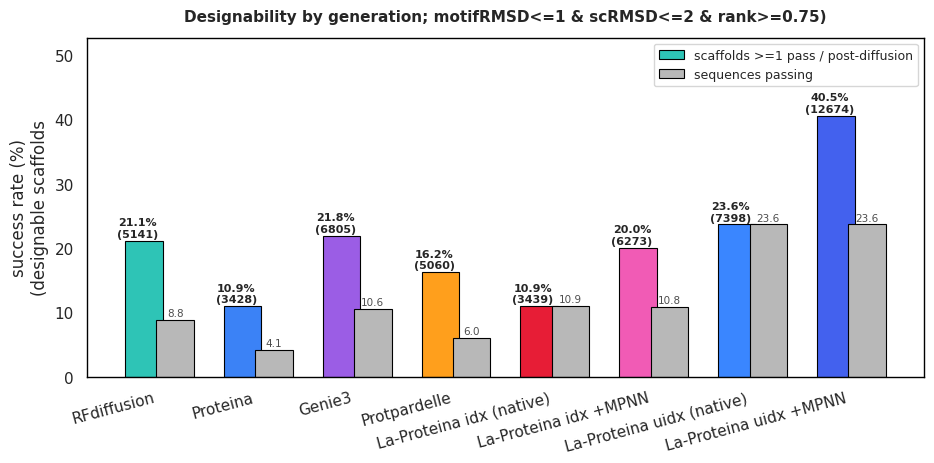

In [12]:
# HEADLINE: normalized success rate = unique scaffolds with >=1 passing seq / POST-DIFFUSION scaffolds.
# Shown next to the per-sequence pass rate (8-seq backbone/MPNN vs 1-seq La-Proteina native).
s = summary.dropna(subset=['designable_pct'])
x = np.arange(len(s)); w = 0.38
fig, ax = plt.subplots(figsize=(9.5,4.8))
ax.bar(x-w/3, s.designable_pct, w, color=[PALETTE[m] for m in s.index], edgecolor='black', linewidth=0.8,
       label='scaffolds >=1 pass / post-diffusion')
ax.bar(x+w/2, s.seq_pass_pct, w, color='0.72', edgecolor='black', linewidth=0.8, label='sequences passing ')
for xi, v, n in zip(x-w/2, s.designable_pct, s.n_designable):
    ax.text(xi, v+0.3, f'{v:.1f}%\n({int(n)})', ha='center', va='bottom', fontsize=8, fontweight='bold')
for xi, v in zip(x+w/2, s.seq_pass_pct):
    ax.text(xi, v+0.3, f'{v:.1f}', ha='center', va='bottom', fontsize=7.5, color='0.3')
ax.set_xticks(x); ax.set_xticklabels([LABELS[m] for m in s.index], rotation=15, ha='right')
ax.set_ylabel('success rate (%)\n(designable scaffolds')
ax.set_ylim(0, max(1, s.designable_pct.max())*1.3)
ax.set_title('Designability by generation; motifRMSD<=1 & scRMSD<=2 & rank>=0.75)',
             fontsize=11, fontweight='bold', pad=12)
ax.legend(frameon=True, fontsize=9, loc='upper right')
prettify(ax); plt.tight_layout(); plt.show()


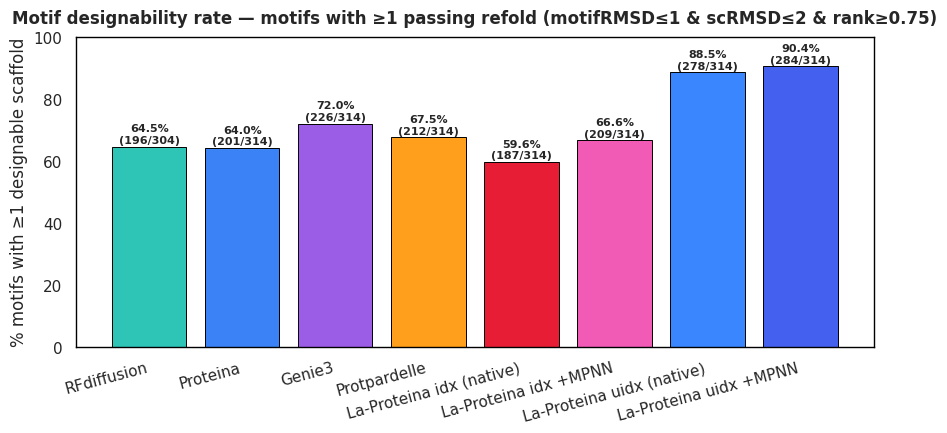

In [14]:
# --- Motif designability rate: % of motifs with >=1 DESIGNABLE scaffold (3-gate AF3 refold), per method ---
num = (per_design[per_design.designable == 1]
       .groupby('method').task_name.nunique())                 # motifs with >=1 passing refold
den = postdiff.groupby('method').task.nunique()                # all motifs the method attempted (incl. fully-failed)
rate = pd.DataFrame({'solved': num, 'total': den})
rate['pct'] = 100 * rate.solved / rate.total
rate = rate.reindex([m for m in METHODS if m in rate.index])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(range(len(rate)), rate.pct, color=[PALETTE.get(m, '#333') for m in rate.index],
       edgecolor='black', linewidth=0.7)
for i, (m, r) in enumerate(rate.iterrows()):
    ax.text(i, r.pct + 0.6, f'{r.pct:.1f}%\n({int(r.solved)}/{int(r.total)})',
            ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_xticks(range(len(rate))); ax.set_xticklabels([LABELS.get(m, m) for m in rate.index], rotation=15, ha='right')
ax.set_ylabel('% motifs with ≥1 designable scaffold'); ax.set_ylim(0, 100)
ax.set_title('Motif designability rate — motifs with ≥1 passing refold (motifRMSD≤1 & scRMSD≤2 & rank≥0.75)',
             fontweight='bold', pad=10)
try: prettify(ax)
except Exception: pass
plt.tight_layout(); plt.show()

## 2 · Designability vs motif disjointedness — the headline benchmark axis

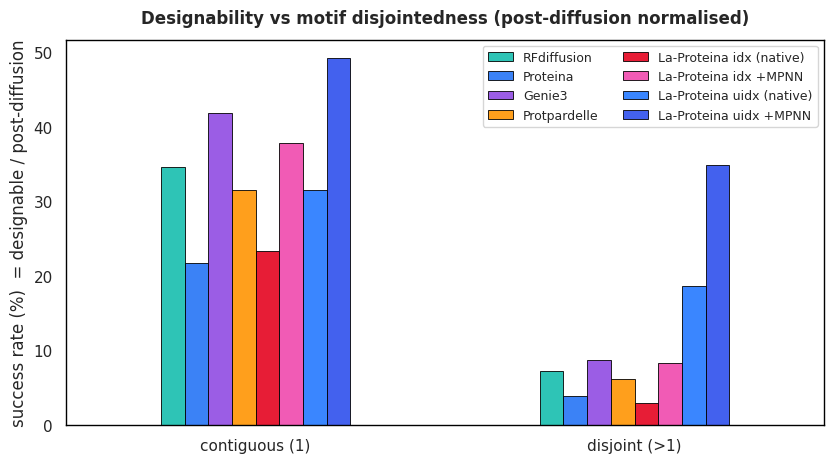

In [15]:
g = srate(['disj','method']).unstack()[present].reindex(['contiguous (1)','disjoint (>1)'])
ax = g.plot(kind='bar', figsize=(8.5,4.8), edgecolor='black', linewidth=0.6, color=[PALETTE[m] for m in g.columns])
ax.set_xticklabels(g.index, rotation=0); ax.set_xlabel('')
ax.set_ylabel('success rate (%)  = designable / post-diffusion')
ax.set_title('Designability vs motif disjointedness (post-diffusion normalised)', fontsize=12, fontweight='bold', pad=12)
ax.legend([LABELS[m] for m in g.columns], title='', frameon=True, ncol=2, fontsize=9)
prettify(ax); plt.tight_layout(); plt.show()

## 3 · Designability by dominant secondary structure

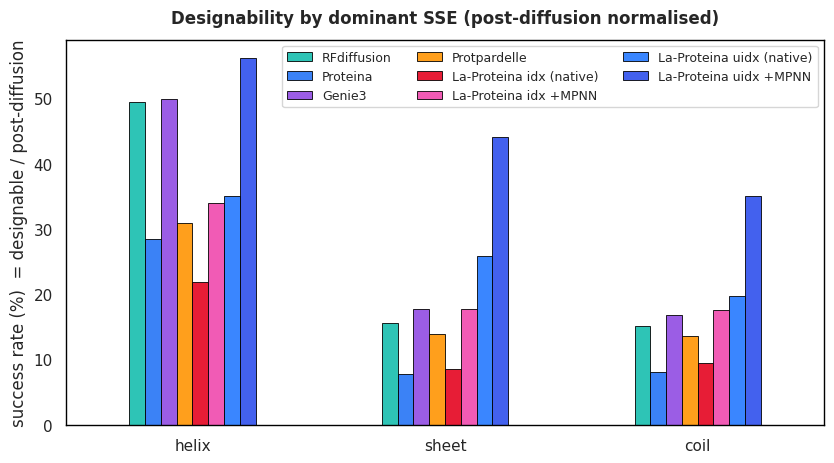

In [16]:
order = [s for s in ['H','E','C'] if s in postdiff.dominant_sse.dropna().unique()]
g = srate(['dominant_sse','method']).unstack()[present].reindex(order)
ax = g.plot(kind='bar', figsize=(8.5,4.8), edgecolor='black', linewidth=0.6, color=[PALETTE[m] for m in g.columns])
ax.set_xticklabels([{'H':'helix','E':'sheet','C':'coil'}[s] for s in g.index], rotation=0); ax.set_xlabel('')
ax.set_ylabel('success rate (%)  = designable / post-diffusion')
ax.set_title('Designability by dominant SSE (post-diffusion normalised)', fontsize=12, fontweight='bold', pad=12)
ax.legend([LABELS[m] for m in g.columns], title='', frameon=True, ncol=3, fontsize=9)
prettify(ax); plt.tight_layout(); plt.show()


## 4 · Designability vs motif length

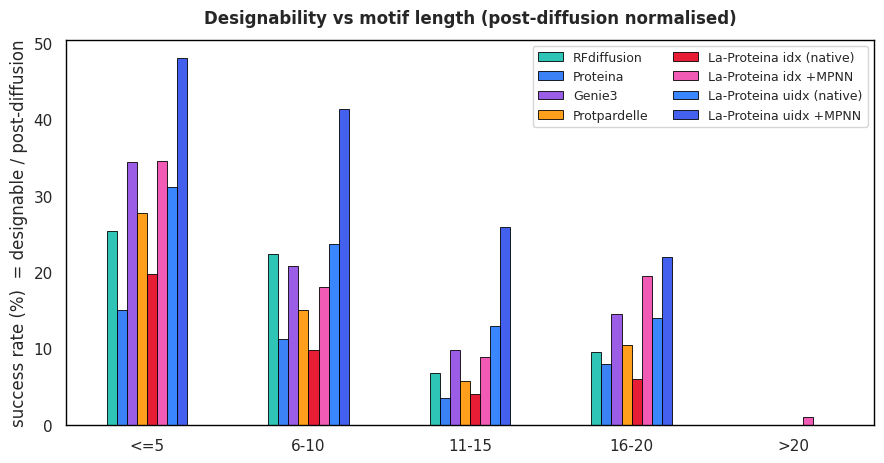

In [19]:
g = srate(['len_bin','method']).unstack()[present]
ax = g.plot(kind='bar', figsize=(9,4.8), edgecolor='black', linewidth=0.6, color=[PALETTE[m] for m in g.columns])
ax.set_xticklabels(g.index, rotation=0); ax.set_xlabel('')
ax.set_ylabel('success rate (%)  = designable / post-diffusion')
ax.set_title('Designability vs motif length (post-diffusion normalised)', fontsize=12, fontweight='bold', pad=12)
ax.legend([LABELS[m] for m in g.columns], title='', frameon=True, ncol=2, fontsize=9)
prettify(ax); plt.tight_layout(); plt.show()


## 5 · Designability by source protein

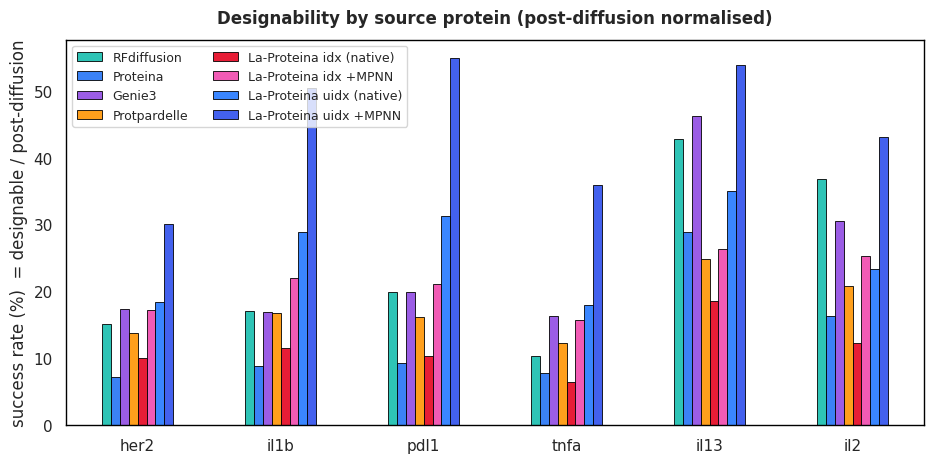

In [20]:
porder = postdiff.pdb_name.value_counts().index.tolist()
g = srate(['pdb_name','method']).unstack()[present].reindex(porder)
ax = g.plot(kind='bar', figsize=(9.5,4.8), edgecolor='black', linewidth=0.6, color=[PALETTE[m] for m in g.columns])
ax.set_xticklabels(g.index, rotation=0); ax.set_xlabel('')
ax.set_ylabel('success rate (%)  = designable / post-diffusion')
ax.set_title('Designability by source protein (post-diffusion normalised)', fontsize=12, fontweight='bold', pad=12)
ax.legend([LABELS[m] for m in g.columns], title='', frameon=True, ncol=2, fontsize=9)
prettify(ax); plt.tight_layout(); plt.show()


## 6 · Metric quality — motifRMSD & scRMSD distributions (per best-seq design)

/scratch/tmp.12004195.bekessel/ipykernel_1165790/3931856031.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=d, x='method', y=col, order=mo, palette=pal, cut=0, ax=ax, inner='quartile')
/scratch/tmp.12004195.bekessel/ipykernel_1165790/3931856031.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([LABELS[m] for m in mo], rotation=20, ha='right')
/scratch/tmp.12004195.bekessel/ipykernel_1165790/3931856031.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=d, x='method', y=col, order=mo, palette=pal, cut=0, ax=ax, inner='quartile')
/scratch/tmp.12004195.bekessel/ipykerne

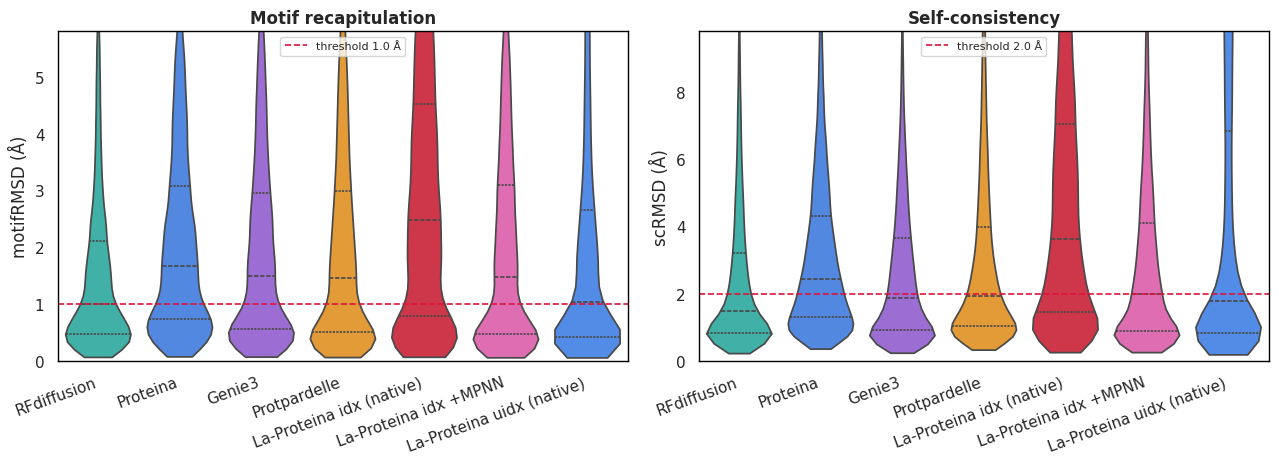

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13,4.8))
mo = [m for m in METHODS if m in per_design.method.unique()]
pal = [PALETTE[m] for m in mo]
for ax, col, thr, ttl in [(axes[0],'motifRMSD',MOTIF_RMSD_MAX,'motifRMSD (Å)'),
                          (axes[1],'scRMSD',SC_RMSD_MAX,'scRMSD (Å)')]:
    d = per_design[np.isfinite(per_design[col])]
    sns.violinplot(data=d, x='method', y=col, order=mo, palette=pal, cut=0, ax=ax, inner='quartile')
    ax.axhline(thr, color='crimson', ls='--', lw=1.2, label=f'threshold {thr} Å')
    ax.set_xticklabels([LABELS[m] for m in mo], rotation=20, ha='right')
    ax.set_xlabel(''); ax.set_ylabel(ttl); ax.set_ylim(0, np.nanpercentile(d[col],95))
    ax.legend(fontsize=8); prettify(ax)
axes[0].set_title('Motif recapitulation', fontweight='bold'); axes[1].set_title('Self-consistency', fontweight='bold')
plt.tight_layout(); plt.show()


## 6B · All-atom motif recapitulation — `bb3` (N,Cα,C) vs `bb4` (+O) vs `heavy` (all heavy atoms)

Cross-check (`motif_atom_crosscheck.py`) recomputes the motif RMSD under three atom sets, on the **passing predictions only** (motifRMSD ≤ 1 & scRMSD ≤ 2), for the baseline run:
- **bb3** = N, Cα, C — identical to our pipeline metric (`esp/score.py`), so it is ≤ 1 by construction — a *sanity check* that the recompute reproduces the scorer.
- **bb4** = N, Cα, C, O — Genie3's *backbone* motif RMSD.
- **heavy** = all heavy (non-H) atoms — Genie3 / MotifBench *all-atom* motif RMSD, whose designable gate is **< 2 Å**.

**How it was computed (why it ran fast):** for each passing prediction it opens *only* that design's AF3 refold `.cif`, reads the fixed motif positions from `positions.jsonl` (`con_hal_idx`), pairs each motif residue's atoms to the native motif PDB **by atom name**, then runs a **single Kabsch superposition** over the pooled atoms. That is one small SVD on the motif's atoms (4–21 residues per motif here, median 7 → never under-determined) — no MSA, no re-folding, no all-vs-all placement search — and `--only passing_predictions.txt` restricts it to the few % of designs that already pass, so the all-atom pass touches only a small subset. bb3/bb4/heavy differ *only* in which atoms enter that one Kabsch.


method                          n  bb3<=1  bb4<=1 heavy<=2 heavy_med
RFdiffusion                 50270  100.0%   88.9%    85.0%      1.52
Proteina                    33696  100.0%   84.6%    77.0%      1.65
Genie3                      54763  100.0%   88.0%    87.4%      1.44
Protpardelle                47937  100.0%   89.0%    84.4%      1.47
La-Proteina idx (native)     7271  100.0%   90.6%    91.0%      1.34
La-Proteina idx +MPNN       55620  100.0%   89.8%    89.1%      1.38


/scratch/tmp.12135578.bekessel/ipykernel_2135117/3523342917.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=dh, x='method', y='motifRMSD_heavy', order=ccm, palette=pal, cut=0, inner='quartile', ax=ax)
/scratch/tmp.12135578.bekessel/ipykernel_2135117/3523342917.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([LABELS[m] for m in ccm], rotation=20, ha='right')


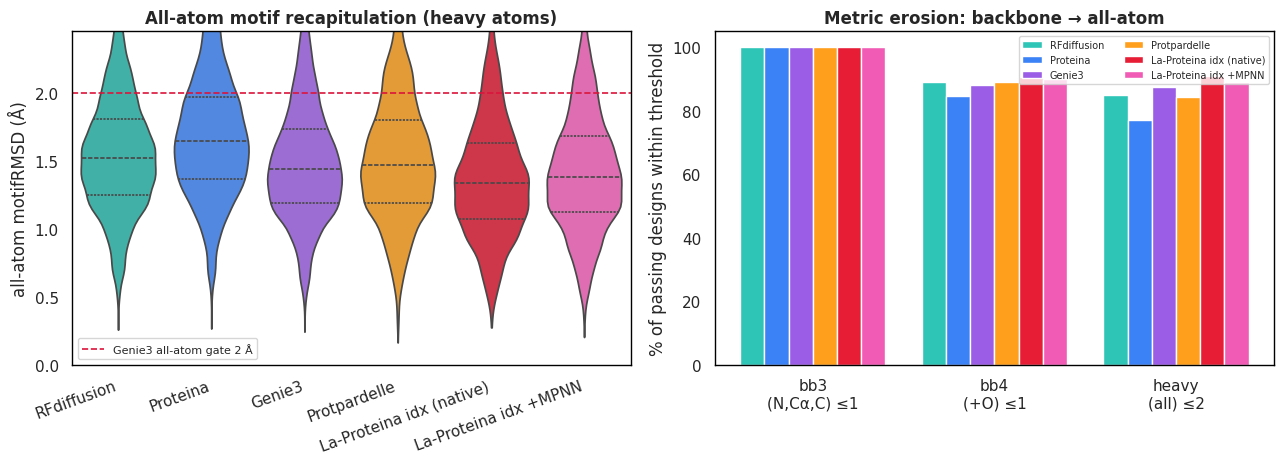

In [12]:
# ── §6B · All-atom motif recapitulation: bb3(N,CA,C) vs bb4(+O) vs heavy(all heavy atoms) ────────────
# motif_atom_crosscheck.csv = one row per PASSING prediction (baseline run), recomputed motif RMSD under 3
# atom sets. bb3 == our score.py metric (so ~100% <=1 by construction); bb4 = Genie3 backbone; heavy = Genie3
# all-atom (gate < 2 A). If a method comes back all-NaN its positions file was unresolved -> re-run its
# crosscheck with the method-level positions.jsonl.
CC_METHODS = ['rfdiff','proteina','genie3','pp1c_bb','laproteina','laproteina_mpnn']
_cc = []
for m in CC_METHODS:
    f = f'{RUN}/{m}/motif_atom_crosscheck.csv'
    if not os.path.exists(f):
        print(f'  MISSING {m:16s} -> {f}'); continue
    d = pd.read_csv(f); d['method'] = m
    if d['motifRMSD_heavy'].notna().sum() == 0:
        print(f'  SKIP    {m:16s} all-NaN heavy (positions unresolved — re-run with method-level positions.jsonl)')
        continue
    _cc.append(d)
cc = pd.concat(_cc, ignore_index=True)
ccm = [m for m in CC_METHODS if m in cc.method.unique()]

print(f'\n{"method":26s} {"n":>6s} {"bb3<=1":>7s} {"bb4<=1":>7s} {"heavy<=2":>8s} {"heavy_med":>9s}')
for m in ccm:
    g = cc[cc.method == m]
    print(f'{LABELS[m]:26s} {len(g):6d} {(g.motifRMSD_bb3<=1).mean()*100:6.1f}% '
          f'{(g.motifRMSD_bb4<=1).mean()*100:6.1f}% {(g.motifRMSD_heavy<=2).mean()*100:7.1f}% '
          f'{g.motifRMSD_heavy.median():9.2f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
pal = [PALETTE[m] for m in ccm]

# LEFT: all-atom (heavy) motif RMSD distribution + Genie3 2 A gate
ax = axes[0]
dh = cc[np.isfinite(cc.motifRMSD_heavy)]
sns.violinplot(data=dh, x='method', y='motifRMSD_heavy', order=ccm, palette=pal, cut=0, inner='quartile', ax=ax)
ax.axhline(2.0, color='crimson', ls='--', lw=1.2, label='Genie3 all-atom gate 2 Å')
ax.set_xticklabels([LABELS[m] for m in ccm], rotation=20, ha='right')
ax.set_xlabel(''); ax.set_ylabel('all-atom motifRMSD (Å)')
ax.set_ylim(0, np.nanpercentile(dh.motifRMSD_heavy, 97)); ax.legend(fontsize=8)
ax.set_title('All-atom motif recapitulation (heavy atoms)', fontweight='bold'); prettify(ax)

# RIGHT: fraction of passers within threshold as atoms are added (bb3<=1 -> bb4<=1 -> heavy<=2)
ax = axes[1]
sets = [('bb3\n(N,Cα,C) ≤1', 'motifRMSD_bb3', 1.0),
        ('bb4\n(+O) ≤1',      'motifRMSD_bb4', 1.0),
        ('heavy\n(all) ≤2',   'motifRMSD_heavy', 2.0)]
x = np.arange(len(sets)); w = 0.8/len(ccm)
for j, m in enumerate(ccm):
    g = cc[cc.method == m]
    vals = [(g[col] <= thr).mean()*100 for _, col, thr in sets]
    ax.bar(x + (j-(len(ccm)-1)/2)*w, vals, w, color=PALETTE[m], label=LABELS[m])
ax.set_xticks(x); ax.set_xticklabels([s for s, _, _ in sets])
ax.set_ylabel('% of passing designs within threshold'); ax.set_ylim(0, 105)
ax.legend(fontsize=7, ncol=2); ax.set_title('Metric erosion: backbone → all-atom', fontweight='bold'); prettify(ax)
plt.tight_layout(); plt.show()

## 7 · Model × SSE designability heatmap

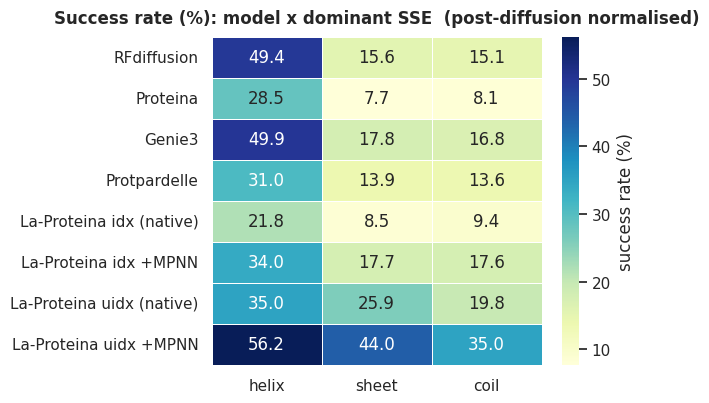

In [21]:
h = srate(['method','dominant_sse']).unstack().reindex(present)[order]
h.index = [LABELS[m] for m in h.index]; h.columns = [{'H':'helix','E':'sheet','C':'coil'}[s] for s in h.columns]
fig, ax = plt.subplots(figsize=(6.5,4.2))
sns.heatmap(h, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label':'success rate (%)'},
            linewidths=0.5, linecolor='white', ax=ax)
ax.set_title('Success rate (%): model x dominant SSE  (post-diffusion normalised)', fontweight='bold', pad=10)
ax.set_ylabel(''); ax.set_xlabel(''); plt.tight_layout(); plt.show()


## 8 · Compute cost vs quality

Export `compute_costs.csv` once with the `sacct` runbook one-liner (writes
`<run>/compute_costs.csv`, columns `method,stage,n_tasks,gpu_hours,maxrss_g`), then run the cells below.


In [31]:
cost_uidx = pd.read_csv('/cluster/work/wicky/bekessel/motif_library/runs/lib_interface_pad5_uidx/compute_costs.csv')
cost_uidx["method"] = "laproteina_uidx"
row = cost_uidx.loc[[0]]
row


,method,stage,n_tasks,gpu_hours,maxrss_g
0,laproteina_uidx,generation,312,62.95,13.6


In [37]:
COST = f'{RUN}/compute_costs.csv'

cost = None
if os.path.exists(COST):
    cost = pd.read_csv(COST);
    cost_uidx = pd.read_csv('/cluster/work/wicky/bekessel/motif_library/runs/lib_interface_pad5_uidx/compute_costs.csv')
    cost_uidx["method"] = "laproteina_unindexed"
    row = cost_uidx.loc[[0]]
    cost = pd.concat([cost, row], ignore_index = True)
    cost.columns=[c.strip() for c in cost.columns]
    mo  = [m for m in METHODS if m in set(cost.method)]
    gen = cost[cost.stage=='generation'].set_index('method').gpu_hours
    ref = cost[cost.stage=='refold'].set_index('method').gpu_hours
    ct  = pd.DataFrame({'generation':gen,'refold':ref}).reindex(mo).fillna(0)
    ct['total'] = ct.generation #+ ct.refold
    # attach quality (from summary in cell 4) + efficiency
    ct['designable_pct']      = summary['designable_pct']
    ct['n_designable']        = summary['n_designable']
    ct['designable_per_gpuh'] = (ct['n_designable']/ct['total']).round(2)
    display(ct.round(1))
else:
    print(f'MISSING {COST}  ->  export it first (sacct runbook), then re-run this + the two cells below.')


,generation,refold,total,designable_pct,n_designable,designable_per_gpuh
method,,,,,,
rfdiff,193.3,0.0,193.3,21.1,5141.0,26.6
proteina,33.0,0.0,33.0,10.9,3428.0,103.8
genie3,51.1,0.0,51.1,21.8,6805.0,133.1
pp1c_bb,15.0,0.0,15.0,16.2,5060.0,337.8
laproteina,31.6,178.1,31.6,11.0,3439.0,108.7
laproteina_unindexed,63.0,0.0,63.0,23.6,7398.0,117.5


### GPU-hours per model (generation + AF3 refold)

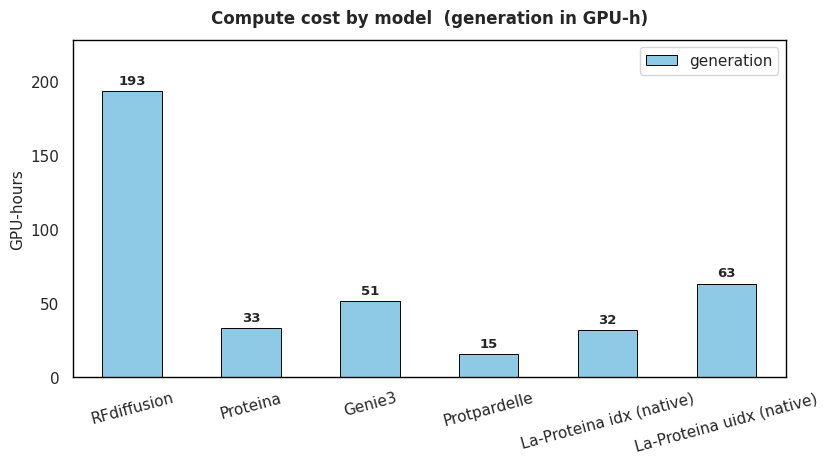

In [41]:
if cost is not None:
    fig, ax = plt.subplots(figsize=(8.5,4.8))
    ct[['generation']].plot(kind='bar', stacked=True, ax=ax,
        color=['#8ecae6','#fb8500'], edgecolor='black', linewidth=0.7)
    for i,(_,r) in enumerate(ct.iterrows()):
        ax.text(i, r.total + ct.total.max()*0.015, f'{r.total:.0f}',
                ha='center', va='bottom', fontsize=9.5, fontweight='bold')
    ax.set_xticklabels([LABELS[m] for m in ct.index], rotation=15)
    ax.set_ylabel('GPU-hours', fontsize=11); ax.set_xlabel('')
    ax.set_ylim(0, ct.total.max()*1.18)
    ax.set_title('Compute cost by model  (generation in GPU-h)', fontsize=12, fontweight='bold', pad=12)
    ax.legend(title='', frameon=True, fontsize=9)
    prettify(ax); plt.tight_layout(); plt.show()


### Cost vs quality — designability (%) against total GPU-hours  *(upper-left = cheap & good)*

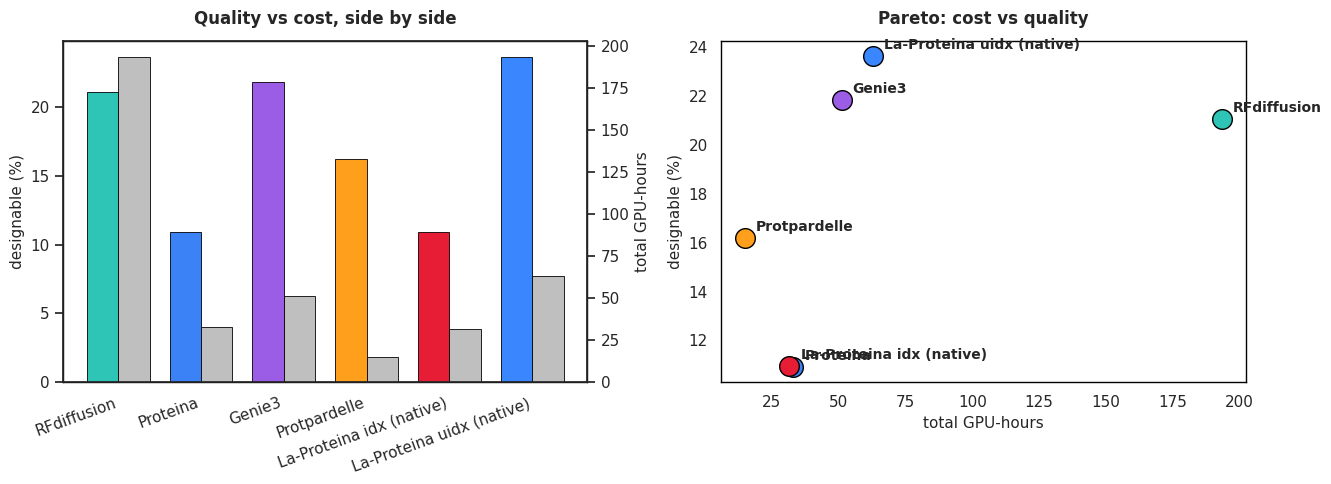

In [42]:
if cost is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13.5,5.0))
    # left: side-by-side designability vs cost, twin axis
    ax = axes[0]; x = np.arange(len(ct)); w = 0.38
    ax.bar(x-w/2, ct.designable_pct, w, color=[PALETTE[m] for m in ct.index],
           edgecolor='black', linewidth=0.6, label='designable %')
    ax.set_ylabel('designable (%)', fontsize=11); ax.set_xticks(x)
    ax.set_xticklabels([LABELS[m] for m in ct.index], rotation=20, ha='right')
    ax2 = ax.twinx()
    ax2.bar(x+w/2, ct.total, w, color='0.75', edgecolor='black', linewidth=0.6, label='GPU-h')
    ax2.set_ylabel('total GPU-hours', fontsize=11)
    ax.set_title('Quality vs cost, side by side', fontsize=12, fontweight='bold', pad=12); prettify(ax)
    # right: scatter cost vs quality (Pareto view)
    ax = axes[1]
    for m in ct.index:
        ax.scatter(ct.loc[m,'total'], ct.loc[m,'designable_pct'], s=200,
                   color=PALETTE[m], edgecolor='black', zorder=3)
        ax.annotate(LABELS[m], (ct.loc[m,'total'], ct.loc[m,'designable_pct']),
                    xytext=(8,5), textcoords='offset points', fontsize=10, fontweight='bold')
    ax.set_xlabel('total GPU-hours', fontsize=11); ax.set_ylabel('designable (%)', fontsize=11)
    ax.set_title('Pareto: cost vs quality', fontsize=12, fontweight='bold', pad=12); prettify(ax)
    plt.tight_layout(); plt.show()


## 9 · Failure-mode distributions — motifRMSD, scRMSD, pLDDT, ranking_score

Per-prediction (every sequence, not best-of-8), so you can see *where* designs die: high scRMSD = backbone
not self-consistent; high motifRMSD = motif misplaced; low pLDDT / ranking_score = AF3 unconfident.


/scratch/tmp.11804183.bekessel/ipykernel_898589/2434959713.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=d, x='method', y=col, order=mo, palette=pal, cut=0, inner='quartile', ax=ax)
/scratch/tmp.11804183.bekessel/ipykernel_898589/2434959713.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([LABELS[m] for m in mo], rotation=20, ha='right')
/scratch/tmp.11804183.bekessel/ipykernel_898589/2434959713.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=d, x='method', y=col, order=mo, palette=pal, cut=0, inner='quartile', ax=ax)
/scratch/tmp.11804183.bekessel/ipykerne

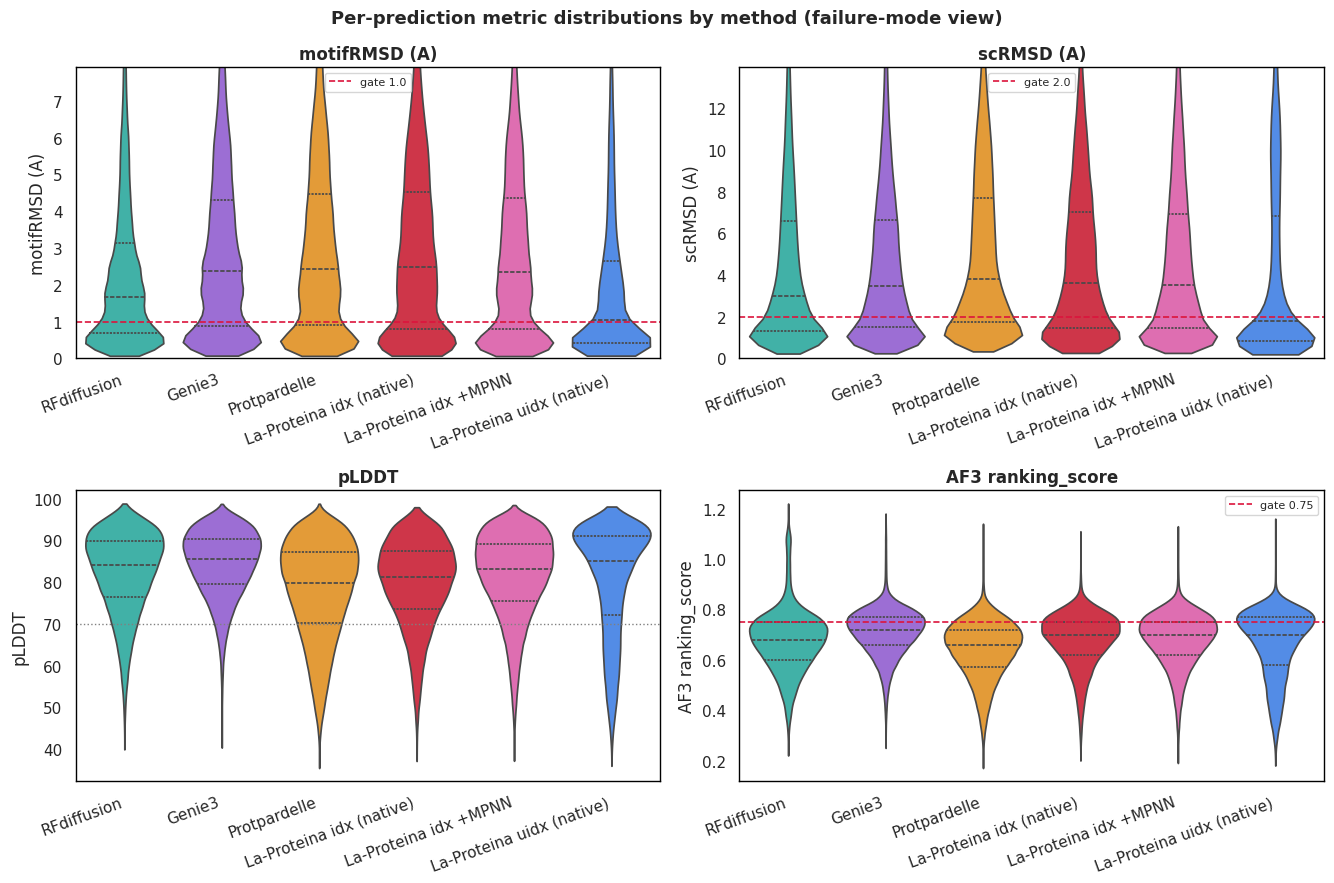

In [24]:
mo  = [m for m in METHODS if m in scores.method.unique()]
pal = [PALETTE[m] for m in mo]
specs = [('motifRMSD','motifRMSD (A)', MOTIF_RMSD_MAX, True),
         ('scRMSD','scRMSD (A)', SC_RMSD_MAX, True),
         ('plddt_mean','pLDDT', None, False),
         ('ranking_score','AF3 ranking_score', RANK_MIN, False)]
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9))
for ax,(col,ttl,thr,clip) in zip(axes.ravel(), specs):
    if col not in scores.columns:
        ax.set_visible(False); continue
    d = scores[np.isfinite(scores[col])]
    if d.empty:
        ax.set_visible(False); continue
    sns.violinplot(data=d, x='method', y=col, order=mo, palette=pal, cut=0, inner='quartile', ax=ax)
    if thr is not None:
        ax.axhline(thr, color='crimson', ls='--', lw=1.2, label=f'gate {thr}'); ax.legend(fontsize=8, loc='best')
    if col == 'plddt_mean':
        ax.axhline(70 if d[col].max() > 1.5 else 0.7, color='gray', ls=':', lw=1)
    if clip:
        ax.set_ylim(0, np.nanpercentile(d[col], 97))
    ax.set_xticklabels([LABELS[m] for m in mo], rotation=20, ha='right')
    ax.set_xlabel(''); ax.set_ylabel(ttl); ax.set_title(ttl, fontweight='bold'); prettify(ax)
fig.suptitle('Per-prediction metric distributions by method (failure-mode view)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()


## 10 · Base (more disjoint) vs Filled (gaps bridged) — does reducing disjointedness help?

Every motif exists as **base** (native fragments, more disjoint) and **filled** (short sequence gaps bridged,
less disjoint). Same underlying motifs, so comparing per-method success rates isolates the effect of
disjointedness. Success = unique scaffolds with >=1 passing sequence.


49 motifs have BOTH base+filled -> 98 tasks in the paired comparison


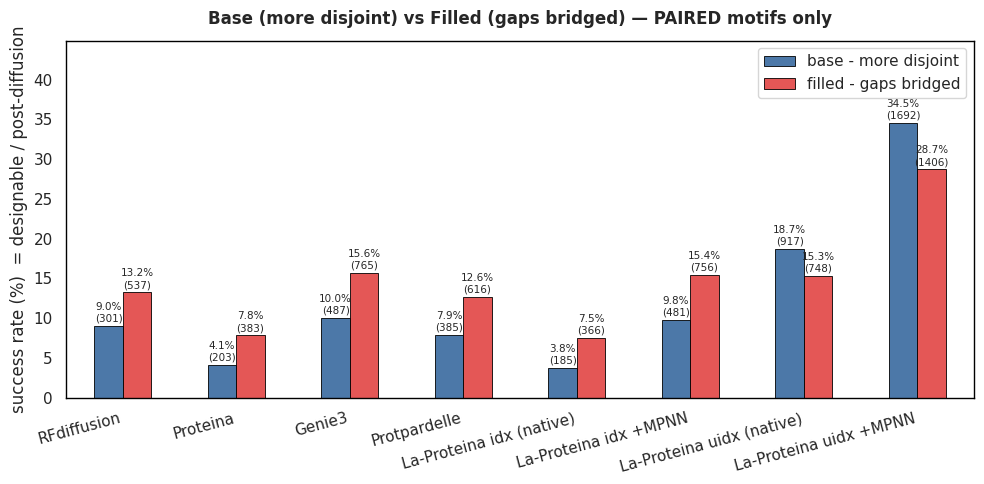

variant,base,filled,filled-base
method,,,
rfdiff,9.00,13.22,4.22
proteina,4.14,7.82,3.67
genie3,10.03,15.62,5.60
pp1c_bb,7.90,12.60,4.71
laproteina,3.78,7.47,3.69
laproteina_mpnn,9.82,15.43,5.61
laproteina_unindexed,18.71,15.27,-3.45
laproteina_unindexed_mpnn,34.53,28.69,-5.84


In [22]:
# PAIRED base-vs-filled: only motifs present as BOTH variants (the pool has more base-only motifs, which
# would inflate base's aggregate). Restrict numerator AND post-diffusion denominator to those.
pool['motif_id'] = pool.pdb_name + '_m' + pool.motif_num.astype(str)
paired_ids = set(pool.groupby('motif_id').variant.nunique().loc[lambda s: s>=2].index)
paired_tasks = set(pool[pool.motif_id.isin(paired_ids)].task_name)
print(f'{len(paired_ids)} motifs have BOTH base+filled -> {len(paired_tasks)} tasks in the paired comparison')
pdp = per_design[per_design.task_name.isin(paired_tasks)]
pfp = postdiff[postdiff.task.isin(paired_tasks)]
pres = [m for m in METHODS if m in pdp.method.unique()]
num = pdp.groupby(['method','variant']).designable.sum()
den = pfp.groupby(['method','variant']).size()
pct = (100*num/den).unstack().reindex(pres)
nok = num.unstack().reindex(pres)
vars_ = [v for v in ['base','filled'] if v in pct.columns]

fig, ax = plt.subplots(figsize=(10,5))
pct[vars_].plot(kind='bar', ax=ax, color=['#4C78A8','#E45756'][:len(vars_)], edgecolor='black', linewidth=0.6)
for i, m in enumerate(pct.index):
    for j, v in enumerate(vars_):
        val = pct.loc[m, v]
        if pd.notna(val):
            ax.text(i+(j-(len(vars_)-1)/2)*0.25, val+0.3, f'{val:.1f}%\n({int(nok.loc[m,v])})',
                    ha='center', va='bottom', fontsize=7.5)
ax.set_xticklabels([LABELS[m] for m in pct.index], rotation=15, ha='right')
ax.set_ylabel('success rate (%)  = designable / post-diffusion'); ax.set_xlabel('')
ax.set_ylim(0, max(1, np.nanmax(pct[vars_].values))*1.3)
ax.set_title('Base (more disjoint) vs Filled (gaps bridged) — PAIRED motifs only', fontsize=12, fontweight='bold', pad=12)
ax.legend([{'base':'base - more disjoint','filled':'filled - gaps bridged'}[v] for v in vars_], frameon=True)
prettify(ax); plt.tight_layout(); plt.show()
if set(['base','filled']).issubset(pct.columns):
    out = pct.copy(); out['filled-base'] = (pct['filled']-pct['base']).round(2); display(out.round(2))


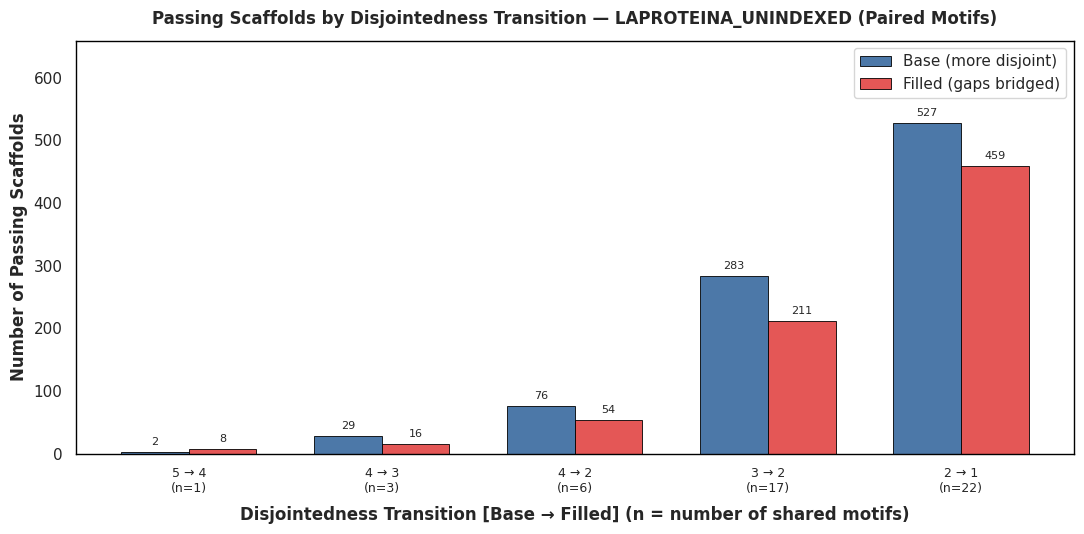

,n_motifs,base_passing,filled_passing,count_delta
5 → 4,1,2,8,6
4 → 3,3,29,16,-13
4 → 2,6,76,54,-22
3 → 2,17,283,211,-72
2 → 1,22,527,459,-68


In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TARGET_METHOD = "laproteina_unindexed"

# 1. Identify paired motifs and construct transition mapping
pool["motif_id"] = pool.pdb_name + "_m" + pool.motif_num.astype(str)

base_pool = (
    pool[pool.variant == "base"]
    .drop_duplicates("motif_id")
    .set_index("motif_id")
)
filled_pool = (
    pool[pool.variant.str.startswith("filled", na=False)]
    .drop_duplicates("motif_id")
    .set_index("motif_id")
)

paired_ids = base_pool.index.intersection(filled_pool.index)

paired_df = pd.DataFrame(
    {
        "disj_base": base_pool.loc[paired_ids, "disjointed_parts"],
        "disj_filled": filled_pool.loc[paired_ids, "disjointed_parts"],
        "task_base": base_pool.loc[paired_ids, "task_name"],
        "task_filled": filled_pool.loc[paired_ids, "task_name"],
    },
    index=paired_ids,
).reset_index()

paired_df["transition"] = (
    paired_df["disj_base"].astype(str)
    + " → "
    + paired_df["disj_filled"].astype(str)
)

# Sort transitions from most disjoint base down to least disjoint base
transition_order = (
    paired_df.groupby("transition")
    .agg(
        disj_base=("disj_base", "max"),
        disj_filled=("disj_filled", "max"),
        n_motifs=("motif_id", "count"),
    )
    .sort_values(by=["disj_base", "disj_filled"], ascending=[False, False])
    .reset_index()
)

# Create lookup dictionaries mapping task_name -> transition & variant
task_map = {}
for _, r in paired_df.iterrows():
    task_map[r.task_base] = (r.transition, "base")
    task_map[r.task_filled] = (r.transition, "filled")

# 2. Filter per_design & postdiff for target method and paired tasks
paired_tasks = set(task_map.keys())

pdp = per_design[
    (per_design.method == TARGET_METHOD)
    & (per_design.task_name.isin(paired_tasks))
].copy()
pfp = postdiff[
    (postdiff.method == TARGET_METHOD) & (postdiff.task.isin(paired_tasks))
].copy()

pdp["transition"] = pdp.task_name.map(lambda t: task_map[t][0])
pdp["variant_type"] = pdp.task_name.map(lambda t: task_map[t][1])

pfp["transition"] = pfp.task.map(lambda t: task_map[t][0])
pfp["variant_type"] = pfp.task.map(lambda t: task_map[t][1])

# 3. Aggregate passing counts and pass rates per transition & variant
num = pdp.groupby(["transition", "variant_type"]).designable.sum().unstack()
den = pfp.groupby(["transition", "variant_type"]).size().unstack()

# Reindex according to the sorted transition order
t_order = [
    t
    for t in transition_order["transition"].tolist()
    if t in num.index or t in den.index
]
num = num.reindex(t_order).fillna(0)
den = den.reindex(t_order).fillna(0)
pct = (100 * num / den.replace(0, np.nan)).fillna(0)

# Add motif count annotation to tick labels (e.g., "3 → 2 (n=12)")
n_counts = (
    transition_order.set_index("transition")["n_motifs"]
    .reindex(t_order)
    .to_dict()
)
xtick_labels = [f"{t}\n(n={n_counts.get(t,0)})" for t in t_order]

# 4. Plot Passing Scaffolds per Transition
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(t_order))
width = 0.35

rects1 = ax.bar(
    x - width / 2,
    num["base"],
    width,
    label="Base (more disjoint)",
    color="#4C78A8",
    edgecolor="black",
    linewidth=0.6,
)
rects2 = ax.bar(
    x + width / 2,
    num["filled"],
    width,
    label="Filled (gaps bridged)",
    color="#E45756",
    edgecolor="black",
    linewidth=0.6,
)

# Annotate bars with exact passing count and pass rate (%)
for rects, var in [(rects1, "base"), (rects2, "filled")]:
    for i, rect in enumerate(rects):
        h = rect.get_height()
        t = t_order[i]
        ax.text(
            rect.get_x() + rect.get_width() / 2.0,
            h + max(num.max().max() * 0.015, 0.5),
            f"{int(h)}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

ax.set_xticks(x)
ax.set_xticklabels(xtick_labels, fontsize=9)
ax.set_xlabel(
    "Disjointedness Transition [Base → Filled] (n = number of shared motifs)",
    fontweight="bold",
    labelpad=8,
)
ax.set_ylabel("Number of Passing Scaffolds", fontweight="bold")
ax.set_ylim(0, num.max().max() * 1.25)
ax.set_title(
    f"Passing Scaffolds by Disjointedness Transition — {TARGET_METHOD.upper()} (Paired Motifs)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax.legend(frameon=True)

try:
    prettify(ax)
except Exception:
    pass

plt.tight_layout()
plt.show()

# Display summary table
summary_df = pd.DataFrame(
    {
        "n_motifs": [n_counts[t] for t in t_order],
        "base_passing": num["base"].astype(int),
        "filled_passing": num["filled"].astype(int),
        "count_delta": (num["filled"] - num["base"]).astype(int),
    },
    index=t_order,
)

display(summary_df)

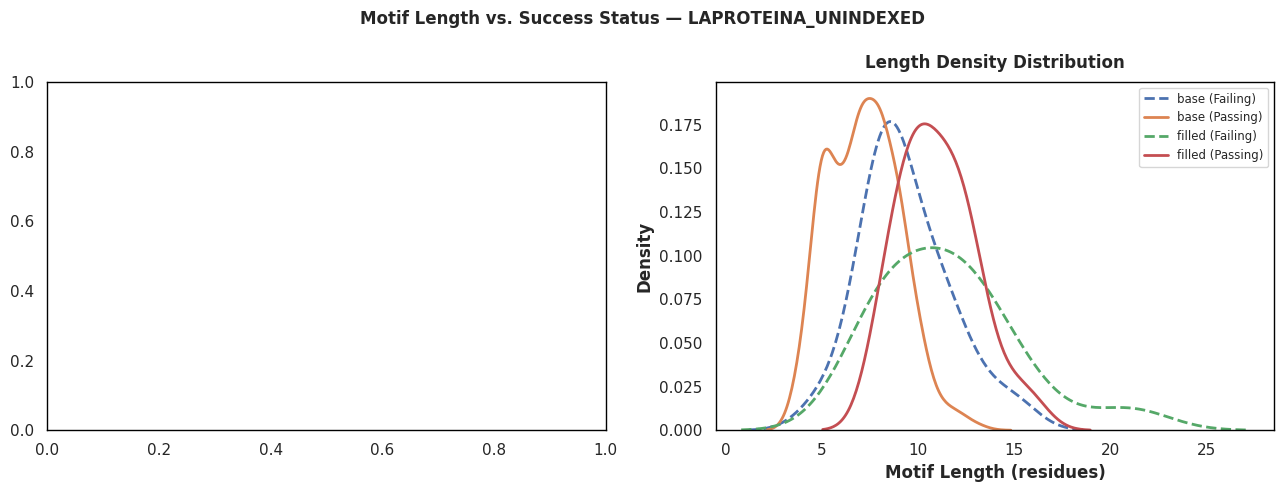

,variant_type,status,n_motifs,median_len,mean_len,std_len,min_len,max_len
0,base,Failing,20,9.0,9.4,2.3,5,15
1,base,Passing,245,7.0,7.2,1.8,4,13
2,filled,Failing,16,11.5,11.6,3.6,7,21
3,filled,Passing,33,11.0,11.0,2.0,8,16


In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

TARGET_METHOD = "laproteina_unindexed"

# 1. Determine per-motif pass status for the target method
pdp = per_design[per_design.method == TARGET_METHOD]
motif_status = (
    pdp.groupby("task_name").designable.max().rename("is_passing").reset_index()
)

# 2. Merge status with pool metadata (motif_length & variant)
pool_df = pool[
    pool.variant.str.startswith(("base", "filled"), na=False)
].copy()
pool_df["variant_type"] = np.where(pool_df.variant == "base", "base", "filled")

motif_df = pool_df.merge(motif_status, on="task_name", how="inner")
motif_df["status"] = np.where(
    motif_df["is_passing"] == 1, "Passing", "Failing"
)

# 3. Plot Distributions
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

# Palette for status
status_colors = {"Passing": "#2ec4b6", "Failing": "#e71d36"}
"""
# Panel 1: Boxplot with overlaid stripplot (for sample density)
sns.boxplot(
    data=motif_df,
    x="variant_type",
    y="motif_length",
    hue="status",
    hue_order=["Passing", "Failing"],
    palette=status_colors,
    ax=axs[0],
    linewidth=0.9,
    fliersize=0,
)
sns.stripplot(
    data=motif_df,
    x="variant_type",
    y="motif_length",
    hue="status",
    hue_order=["Passing", "Failing"],
    dodge=True,
    alpha=0.35,
    size=4,
    color="black",
    ax=axs[0],
)

axs[0].set_title(
    "Motif Length by Variant & Status", fontweight="bold", pad=10
)
axs[0].set_xlabel("Motif Variant", fontweight="bold")
axs[0].set_ylabel("Motif Length (residues)", fontweight="bold")

# Fix duplicate legend entries caused by stripplot
handles, labels = axs[0].get_legend_handles_labels()
axs[0].legend(
    handles[:2], labels[:2], title="Status", frameon=True, loc="upper right"
)
"""
# Panel 2: KDE Density Curves
for (v_type, stat), group in motif_df.groupby(["variant_type", "status"]):
    ls = "-" if stat == "Passing" else "--"
    color = "#3a86ff" if v_type == "base" else "#e71d36"
    if stat == "Failing":
        color = "#8d99ae" if v_type == "base" else "#f77f00"

    sns.kdeplot(
        data=group,
        x="motif_length",
        ax=axs[1],
        label=f"{v_type} ({stat})",
        linestyle=ls,
        linewidth=2,
        common_norm=False,
    )

axs[1].set_title("Length Density Distribution", fontweight="bold", pad=10)
axs[1].set_xlabel("Motif Length (residues)", fontweight="bold")
axs[1].set_ylabel("Density", fontweight="bold")
axs[1].legend(frameon=True, fontsize=8.5)

for ax in axs:
    try:
        prettify(ax)
    except Exception:
        pass

plt.suptitle(
    f"Motif Length vs. Success Status — {TARGET_METHOD.upper()}",
    fontweight="bold",
    fontsize=12,
)
plt.tight_layout()
plt.show()

# ── Summary Statistics Table ─────────────────────────────────────────────────
summary_length = (
    motif_df.groupby(["variant_type", "status"])
    .agg(
        n_motifs=("motif_length", "count"),
        median_len=("motif_length", "median"),
        mean_len=("motif_length", "mean"),
        std_len=("motif_length", "std"),
        min_len=("motif_length", "min"),
        max_len=("motif_length", "max"),
    )
    .reset_index()
)

display(summary_length.round(1))

In [29]:
import pandas as pd
import numpy as np

TARGET_METHOD = "laproteina_unindexed"

# 1. Isolate contiguous motifs (disjointed_parts == 1)
contig_pool = pool[pool.disjointed_parts == 1].copy()

# 2. Get motif pass status across ALL methods
# (1 if at least one design passed, 0 otherwise)
method_status = (
    per_design.groupby(["task_name", "method"])
    .designable.max()
    .unstack(fill_value=0)
)

# 3. Merge metadata with method success matrix
contig_merged = contig_pool.merge(
    method_status, left_on="task_name", right_index=True, how="inner"
)

# 4. Filter for motifs that FAILED in the target method
failed_contig = contig_merged[contig_merged[TARGET_METHOD] == 0].copy()

if failed_contig.empty:
    print(f"No contiguous motifs failed in {TARGET_METHOD}.")
else:
    # Calculate how many OTHER methods succeeded on these specific motifs
    other_methods = [m for m in method_status.columns if m != TARGET_METHOD]
    failed_contig["other_methods_passed"] = failed_contig[other_methods].sum(axis=1)

    # Format the summary table
    cols_to_show = [
        "pdb_name",
        "motif_num",
        "variant",
        "motif_length",
        "dominant_sse",
        "dssp",
        "motif_residues",
        "other_methods_passed",
    ] + other_methods

    # Sort so motifs solved by the most alternative methods appear at the top
    res_df = failed_contig[cols_to_show].sort_values(
        by=["other_methods_passed", "motif_length"], ascending=[False, True]
    )

    print(
        f"=== Contiguous Motifs FAILED by {TARGET_METHOD.upper()} (N={len(res_df)}) ==="
    )
    
    # ── Quick summary of failing secondary structures
    print("\nFailing motifs broken down by Dominant SSE:")
    display(
        res_df.groupby("dominant_sse")
        .agg(n_failed=("pdb_name", "count"), avg_length=("motif_length", "mean"))
        .round(1)
    )

    print("\nDetailed list of failing motifs & rescue by other methods:")
    display(res_df)

=== Contiguous Motifs FAILED by LAPROTEINA_UNINDEXED (N=11) ===

Failing motifs broken down by Dominant SSE:


,n_failed,avg_length
dominant_sse,,
C,10,8.4
E,1,11.0



Detailed list of failing motifs & rescue by other methods:


,pdb_name,motif_num,variant,motif_length,dominant_sse,dssp,motif_residues,other_methods_passed,genie3,laproteina,laproteina_mpnn,pp1c_bb,proteina,rfdiff
142,il13,25,base,5,C,CCCCH,23 24 25 26 27,6,1,1,1,1,1,1
237,il2,100,filled,8,C,CCCCHHHH,98 99 100 101 102 103 104 105,6,1,1,1,1,1,1
312,tnfa,110,filled,7,C,CCCCCCC,106 107 108 109 110 111 112,5,0,1,1,1,1,1
138,il13,21,base,8,C,HHHHCCCC,17 18 19 20 21 22 23 24,5,1,0,1,1,1,1
100,her2,243,filled,11,E,CEEECCEEECC,235 236 237 238 239 240 241 242 243 244 245,3,1,0,0,1,1,0
141,il13,24,base,8,C,HHCCCCCC,19 20 21 22 23 24 25 26,2,0,0,0,0,1,1
77,her2,584,base,7,C,CCCCCCC,582 583 584 585 586 587 588,0,0,0,0,0,0,0
121,her2,583,filled,8,C,CCCCCCCC,581 582 583 584 585 586 587 588,0,0,0,0,0,0,0
122,her2,588,filled,9,C,CCCCCCCCC,582 583 584 585 586 587 588 589 590,0,0,0,0,0,0,0
120,her2,582,filled,12,C,CCCCCCCCCCCC,580 581 582 583 584 585 586 587 588 589 590 591,0,0,0,0,0,0,0


## 11 · Per-motif quadrant map (base motifs only)

One dot = one **base** motif, placed by its **median motifRMSD (x)** and **median scRMSD (y)** across all its
predictions. Dashed lines = the gates (1 A / 2 A); the shaded bottom-left corner is the designable quadrant.
**Dot size = number of passing scaffolds** for that motif. Swap the colouring to read failure structure:
pLDDT, dominant SSE, source protein, disjointedness.


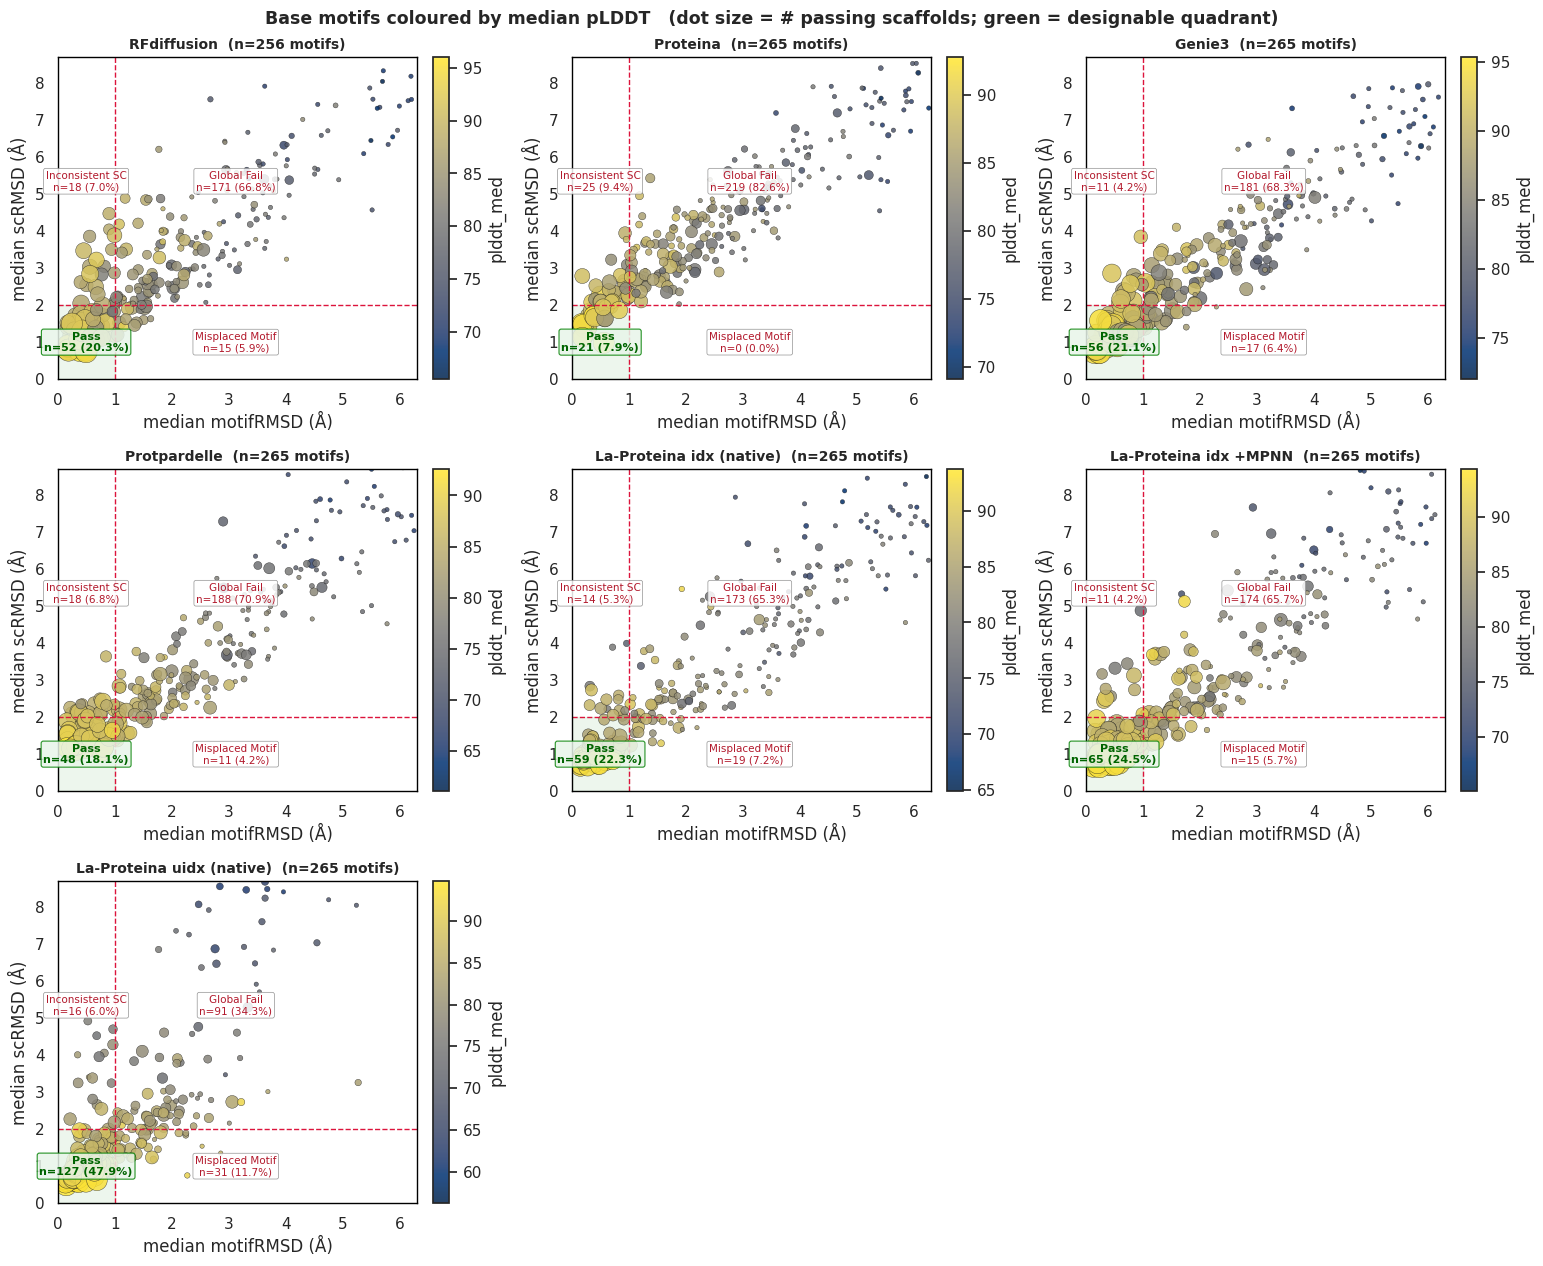

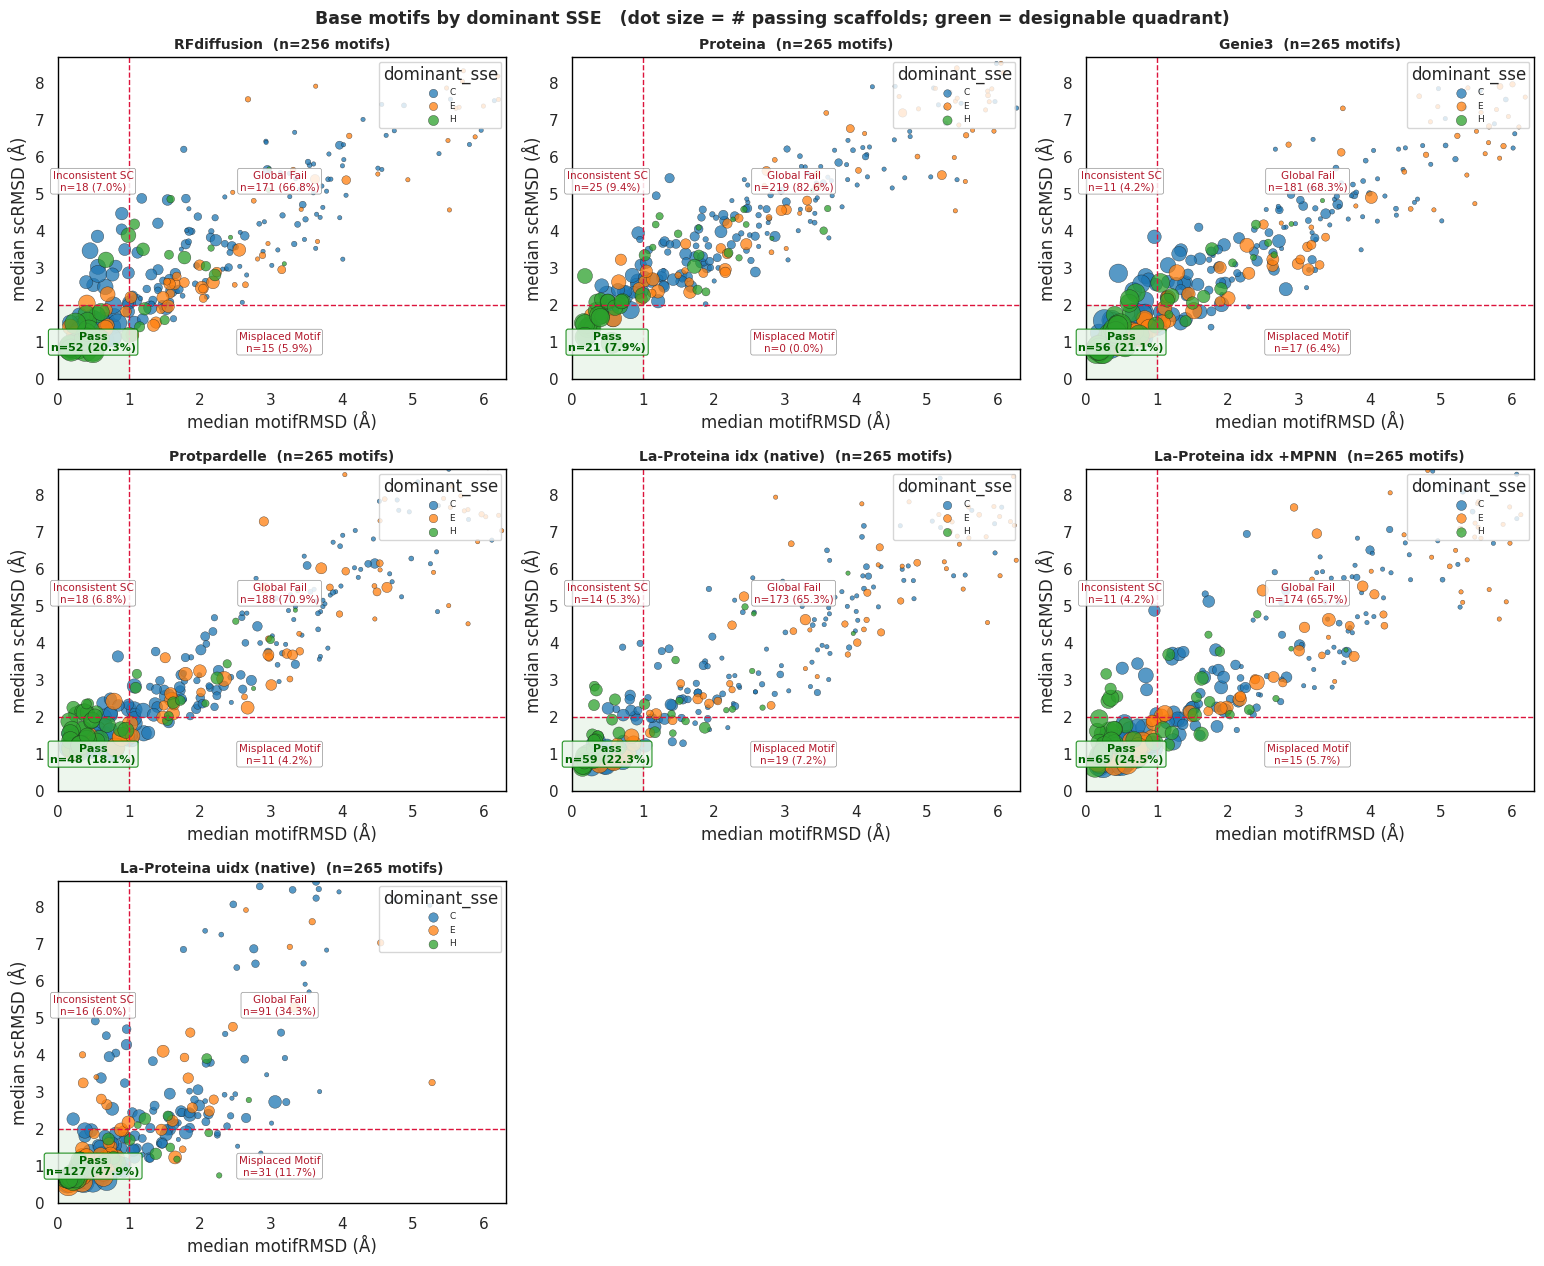

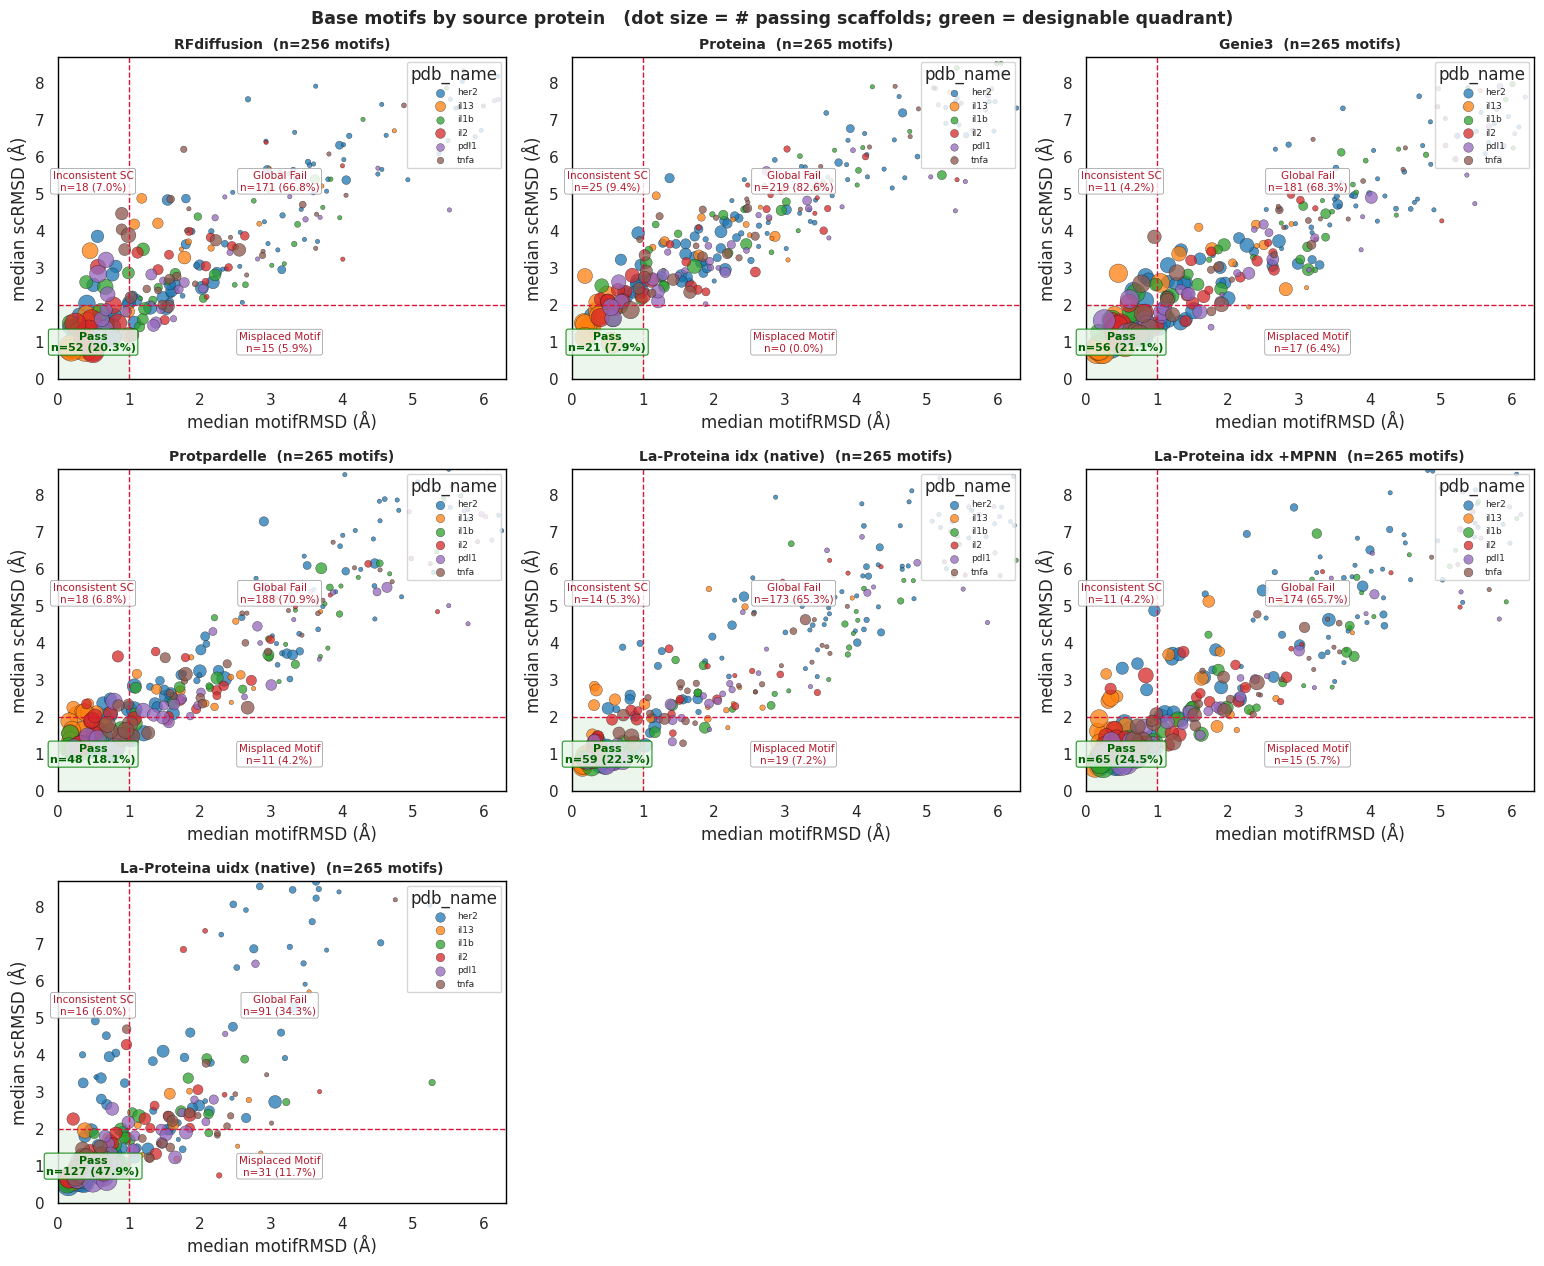

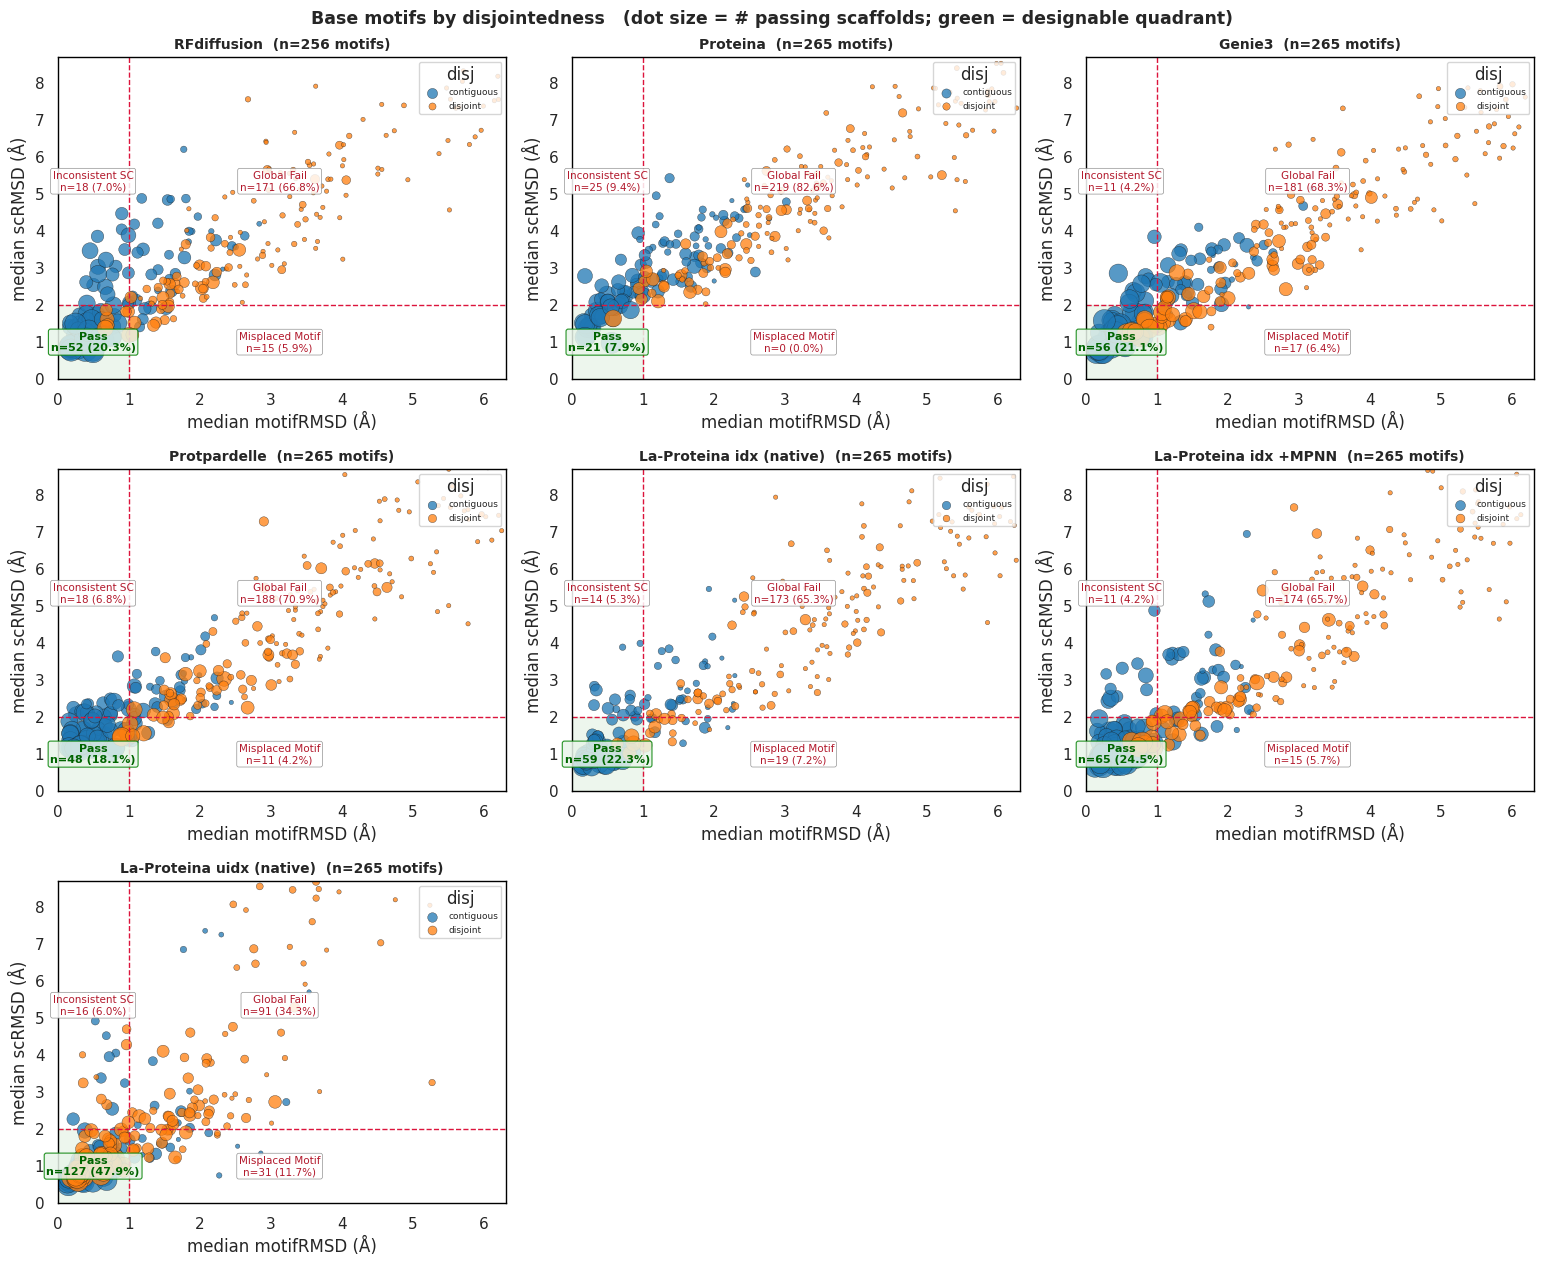

In [12]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# ── 1. Prepare Dataframe ───────────────────────────────────────────────────────
base_s = scores[scores.variant == "base"]
base_pd = per_design[per_design.variant == "base"]

mag = (
    base_s.groupby(["method", "task_name"])
    .agg(
        motifRMSD_med=("motifRMSD", "median"),
        scRMSD_med=("scRMSD", "median"),
        plddt_med=("plddt_mean", "median"),
    )
    .reset_index()
)

mag = mag.merge(
    base_pd.groupby(["method", "task_name"])
    .designable.sum()
    .rename("n_pass")
    .reset_index(),
    on=["method", "task_name"],
    how="left",
)

mag = mag.merge(
    pool[["task_name", "pdb_name", "dominant_sse", "disjointed_parts"]].drop_duplicates(
        "task_name"
    ),
    on="task_name",
    how="left",
)

mag["disj"] = np.where(
    mag.disjointed_parts.fillna(1) > 1, "disjoint", "contiguous"
)
mag["n_pass"] = mag.n_pass.fillna(0)

XMAX = min(8.0, np.nanpercentile(mag.motifRMSD_med, 98))
YMAX = min(14.0, np.nanpercentile(mag.scRMSD_med, 98))


# ── 2. Plotting Function with Quadrant Annotations ───────────────────────────
def motif_quadrant(color_by, title, cmap="viridis", categorical=False):
    methods = [m for m in METHODS if m in mag.method.unique()]
    nc = 3
    nr = int(np.ceil(len(methods) / nc))
    fig, axes = plt.subplots(
        nr, nc, figsize=(5.2 * nc, 4.3 * nr), squeeze=False
    )

    for ax, m in zip(axes.ravel(), methods):
        d = mag[mag.method == m]
        sz = 10 + d.n_pass * 3

        # Designable green quadrant patch
        ax.add_patch(
            mpatches.Rectangle(
                (0, 0),
                MOTIF_RMSD_MAX,
                SC_RMSD_MAX,
                color="green",
                alpha=0.07,
                zorder=0,
            )
        )

        # Plot scatter points
        if categorical:
            cats = sorted(d[color_by].dropna().unique())
            pal = dict(zip(cats, sns.color_palette("tab10", len(cats))))
            for c in cats:
                dd = d[d[color_by] == c]
                ax.scatter(
                    dd.motifRMSD_med,
                    dd.scRMSD_med,
                    s=10 + dd.n_pass * 3,
                    color=pal[c],
                    alpha=0.75,
                    edgecolor="k",
                    linewidth=0.3,
                    label=str(c),
                )
            ax.legend(
                fontsize=6.5,
                title=color_by,
                markerscale=0.6,
                loc="upper right",
            )
        else:
            sc = ax.scatter(
                d.motifRMSD_med,
                d.scRMSD_med,
                s=sz,
                c=d[color_by],
                cmap=cmap,
                alpha=0.85,
                edgecolor="k",
                linewidth=0.3,
            )
            fig.colorbar(sc, ax=ax, label=color_by, fraction=0.046, pad=0.04)

        # Draw cutoff lines
        ax.axvline(MOTIF_RMSD_MAX, color="crimson", ls="--", lw=1)
        ax.axhline(SC_RMSD_MAX, color="crimson", ls="--", lw=1)

        # ── Calculate Quadrant Counts ─────────────────────────────────────────
        total = len(d) if len(d) > 0 else 1

        q_pass = (
            (d.motifRMSD_med <= MOTIF_RMSD_MAX) & (d.scRMSD_med <= SC_RMSD_MAX)
        ).sum()
        q_high_m = (
            (d.motifRMSD_med > MOTIF_RMSD_MAX) & (d.scRMSD_med <= SC_RMSD_MAX)
        ).sum()
        q_high_s = (
            (d.motifRMSD_med <= MOTIF_RMSD_MAX) & (d.scRMSD_med > SC_RMSD_MAX)
        ).sum()
        q_both = (
            (d.motifRMSD_med > MOTIF_RMSD_MAX) & (d.scRMSD_med > SC_RMSD_MAX)
        ).sum()

        # ── Overlay Text in Quadrants ─────────────────────────────────────────
        bbox_pass = dict(
            boxstyle="round,pad=0.2",
            facecolor="#e8f5e9",
            edgecolor="green",
            lw=0.8,
            alpha=0.85,
        )
        bbox_fail = dict(
            boxstyle="round,pad=0.2",
            facecolor="white",
            edgecolor="grey",
            lw=0.5,
            alpha=0.85,
        )

        # Q1: Pass (Bottom-Left)
        ax.text(
            MOTIF_RMSD_MAX * 0.5,
            SC_RMSD_MAX * 0.5,
            f"Pass\nn={q_pass} ({q_pass/total*100:.1f}%)",
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold",
            color="darkgreen",
            bbox=bbox_pass,
        )

        # Q2: High Motif RMSD (Bottom-Right)
        ax.text(
            MOTIF_RMSD_MAX + (XMAX - MOTIF_RMSD_MAX) * 0.4,
            SC_RMSD_MAX * 0.5,
            f"Misplaced Motif\nn={q_high_m} ({q_high_m/total*100:.1f}%)",
            ha="center",
            va="center",
            fontsize=7.5,
            color="#b2182b",
            bbox=bbox_fail,
        )

        # Q3: High SC RMSD (Top-Left)
        ax.text(
            MOTIF_RMSD_MAX * 0.5,
            SC_RMSD_MAX + (YMAX - SC_RMSD_MAX) * 0.5,
            f"Inconsistent SC\nn={q_high_s} ({q_high_s/total*100:.1f}%)",
            ha="center",
            va="center",
            fontsize=7.5,
            color="#b2182b",
            bbox=bbox_fail,
        )

        # Q4: Both High (Top-Right)
        ax.text(
            MOTIF_RMSD_MAX + (XMAX - MOTIF_RMSD_MAX) * 0.4,
            SC_RMSD_MAX + (YMAX - SC_RMSD_MAX) * 0.5,
            f"Global Fail\nn={q_both} ({q_both/total*100:.1f}%)",
            ha="center",
            va="center",
            fontsize=7.5,
            color="#b2182b",
            bbox=bbox_fail,
        )

        # Axis styling
        ax.set_xlim(0, XMAX)
        ax.set_ylim(0, YMAX)
        ax.set_xlabel("median motifRMSD (Å)")
        ax.set_ylabel("median scRMSD (Å)")
        ax.set_title(
            f"{LABELS.get(m,m)}  (n={len(d)} motifs)",
            fontweight="bold",
            fontsize=10,
        )
        prettify(ax)

    # Hide unused grid subplots
    for ax in axes.ravel()[len(methods) :]:
        ax.set_visible(False)

    fig.suptitle(
        title + "   (dot size = # passing scaffolds; green = designable quadrant)",
        fontsize=12.5,
        fontweight="bold",
    )
    plt.tight_layout()
    plt.show()


# ── 3. Run Figures ────────────────────────────────────────────────────────────
motif_quadrant("plddt_med", "Base motifs coloured by median pLDDT", cmap="cividis")
motif_quadrant("dominant_sse", "Base motifs by dominant SSE", categorical=True)
motif_quadrant("pdb_name", "Base motifs by source protein", categorical=True)
motif_quadrant("disj", "Base motifs by disjointedness", categorical=True)

## 12 - Motif-level scaffoldability: how many distinct motifs can each method scaffold?

Per method, each motif gets a count of **successful scaffolds** (designable designs, 0-100). Motifs are
banded none / hard / moderate / easy; the stacked bar shows the whole library split, and the annotation
gives distinct scaffoldable motifs (>=1 success). Motifs with 0 refolded designs are included as 0.


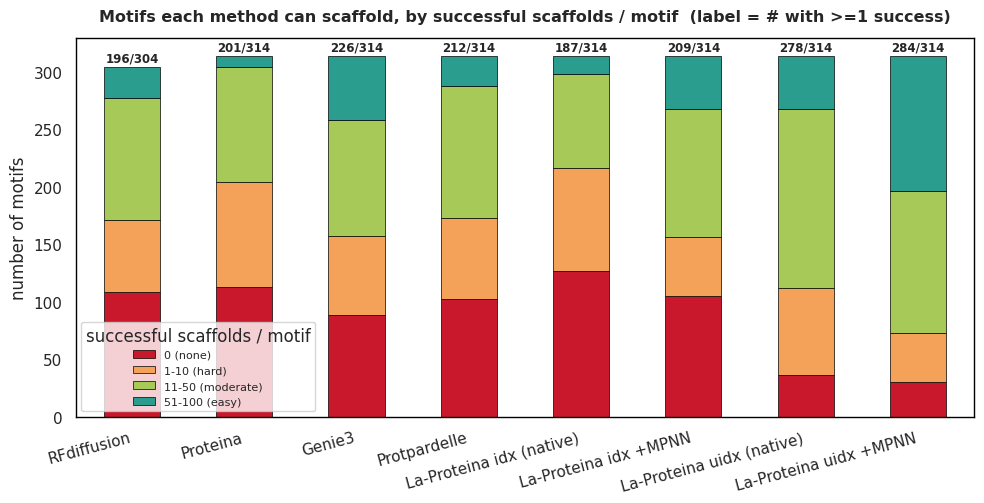

band,0 (none),1-10 (hard),11-50 (moderate),51-100 (easy),distinct_scaffoldable
method,,,,,
rfdiff,108,63,106,27,196
proteina,113,91,100,10,201
genie3,88,69,101,56,226
pp1c_bb,102,71,115,26,212
laproteina,127,89,82,16,187
laproteina_mpnn,105,51,112,46,209
laproteina_unindexed,36,76,156,46,278
laproteina_unindexed_mpnn,30,43,123,118,284


In [24]:
allm = postdiff[['method','task']].drop_duplicates().rename(columns={'task':'task_name'})
msucc = allm.merge(per_design.groupby(['method','task_name']).designable.sum().rename('n_pass').reset_index(),
                   on=['method','task_name'], how='left')
msucc['n_pass'] = msucc.n_pass.fillna(0).astype(int)
BANDS=[-1,0,10,50,100]; BL=['0 (none)','1-10 (hard)','11-50 (moderate)','51-100 (easy)']
msucc['band'] = pd.cut(msucc.n_pass, BANDS, labels=BL)
pres = [m for m in METHODS if m in msucc.method.unique()]
tab = msucc.groupby(['method','band'], observed=True).size().unstack().reindex(pres)[BL].fillna(0)

fig, ax = plt.subplots(figsize=(10,5.2))
tab.plot(kind='bar', stacked=True, ax=ax, edgecolor='black', linewidth=0.5,
         color=['#c9182b','#f4a259','#a7c957','#2a9d8f'])
ax.set_xticklabels([LABELS[m] for m in tab.index], rotation=15, ha='right')
ax.set_ylabel('number of motifs'); ax.set_xlabel('')
for i,m in enumerate(tab.index):
    scaf=int((msucc[(msucc.method==m)&(msucc.n_pass>0)]).shape[0]); tot=int((msucc[msucc.method==m]).shape[0])
    ax.text(i, tab.loc[m].sum()+2, f'{scaf}/{tot}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax.set_title('Motifs each method can scaffold, by successful scaffolds / motif  (label = # with >=1 success)',
             fontsize=11.5, fontweight='bold', pad=12)
ax.legend(title='successful scaffolds / motif', frameon=True, fontsize=8)
prettify(ax); plt.tight_layout(); plt.show()
tab['distinct_scaffoldable'] = [int((msucc[(msucc.method==m)&(msucc.n_pass>0)]).shape[0]) for m in tab.index]
display(tab.astype(int))


## 13 - Per-residue coverage by successful scaffolds

For each motif residue: total successful scaffolds across all motifs that include it, **normalised by the
number of library motifs that residue was originally in**. High = an epitope residue that lands in many
successful designs; low/zero = a residue the method struggles to place. (mirrors the designability_notebook.)


,method,pdb_name,residue,pass_scaffolds,n_motifs_in,coverage
0,genie3,her2,81,0,2,0.0
1,genie3,her2,82,0,2,0.0
2,genie3,her2,91,0,2,0.0
3,genie3,her2,126,0,2,0.0
4,genie3,her2,127,0,2,0.0
5,genie3,her2,128,0,2,0.0
6,genie3,her2,129,0,2,0.0
7,genie3,her2,130,0,2,0.0
8,genie3,her2,155,0,2,0.0
9,genie3,her2,156,0,1,0.0


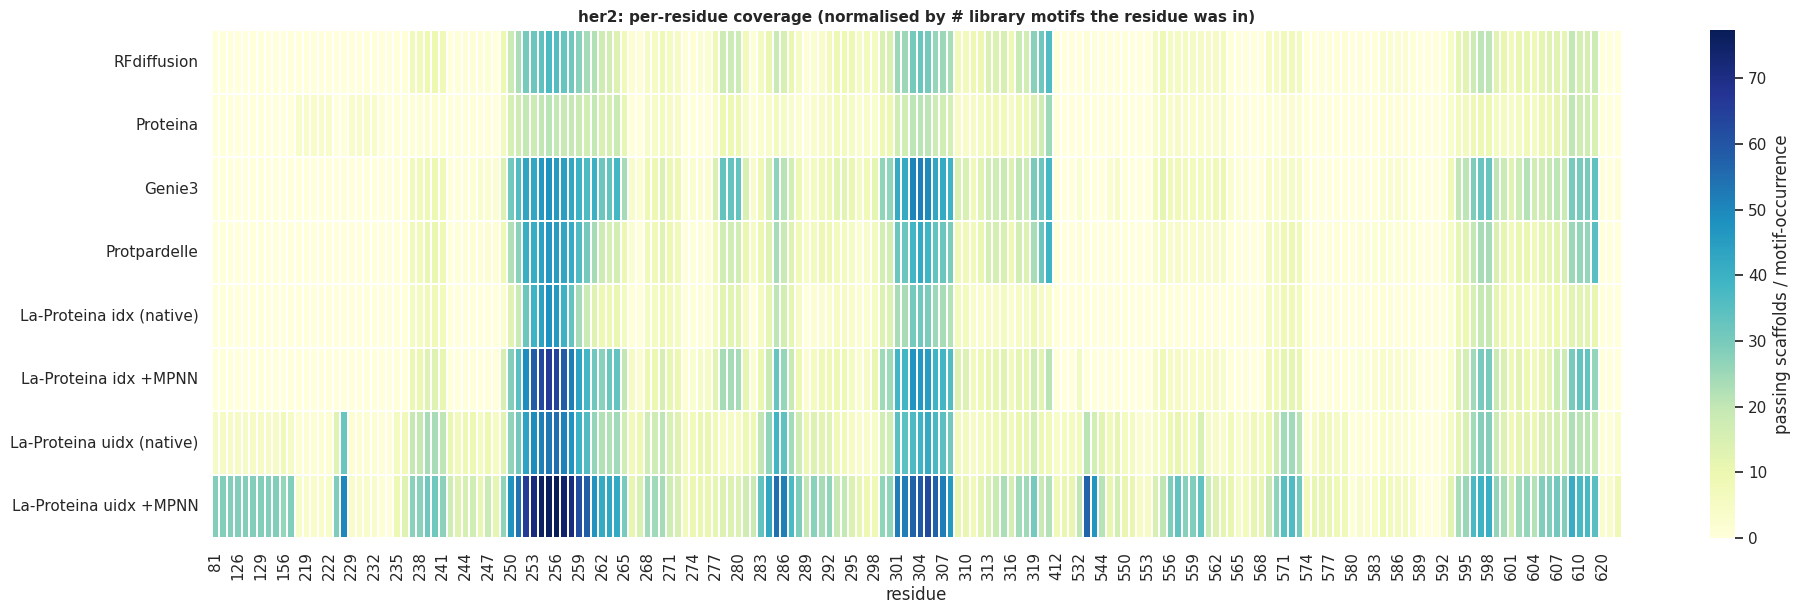

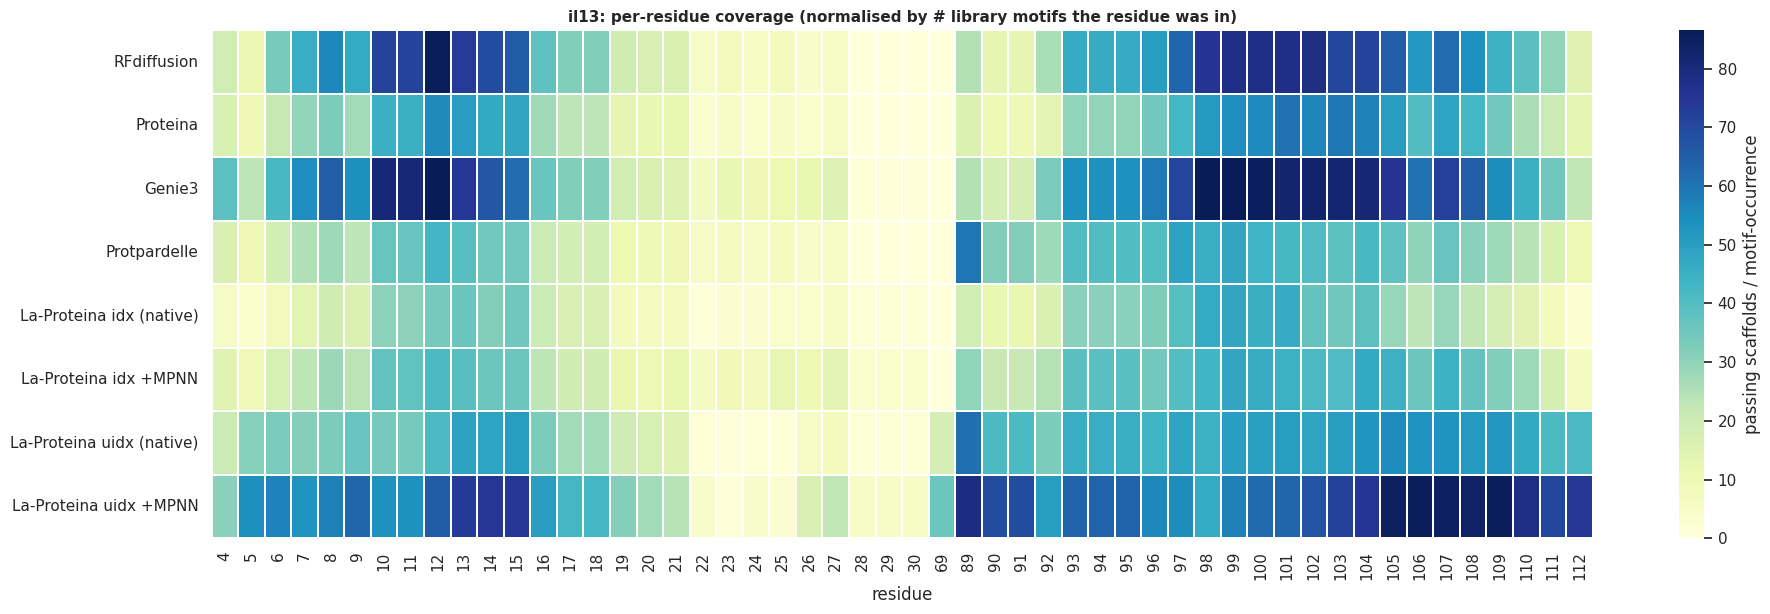

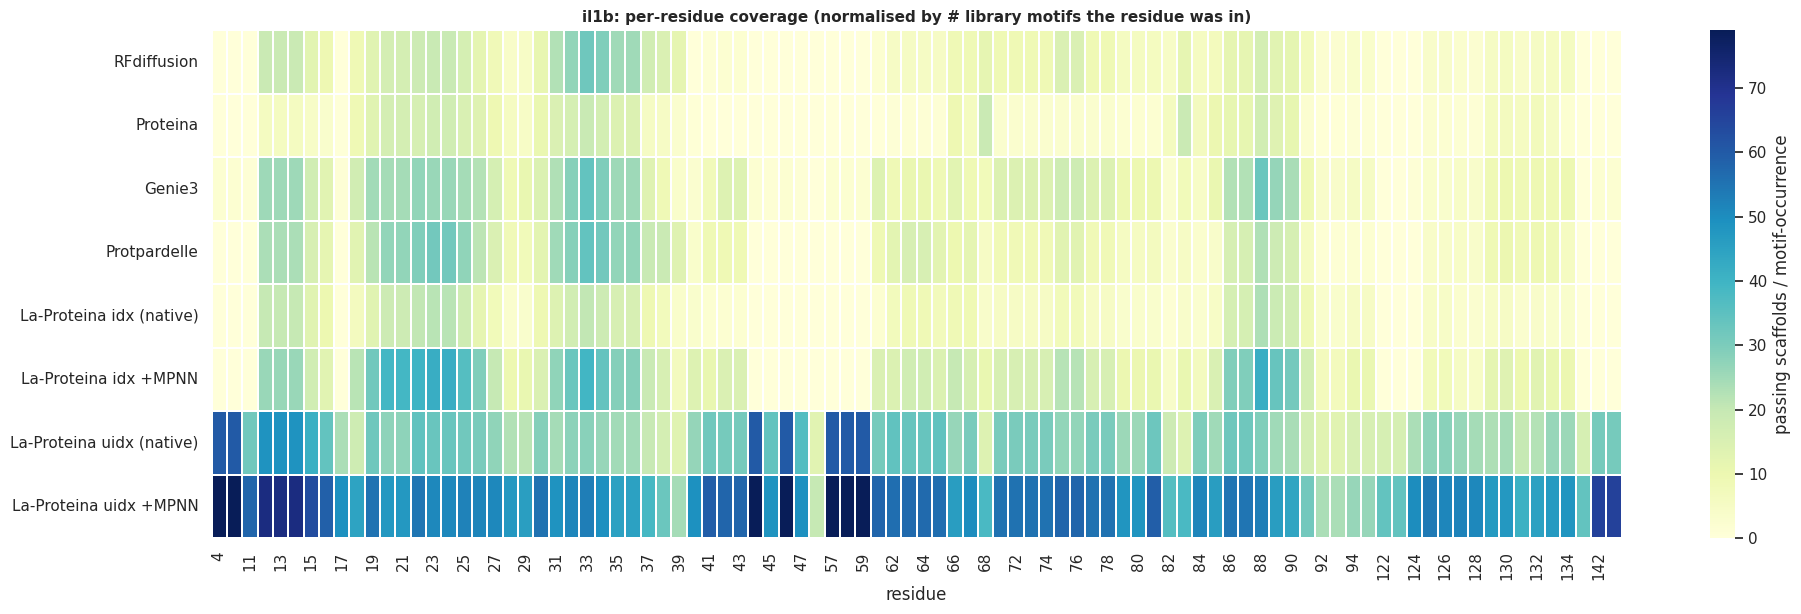

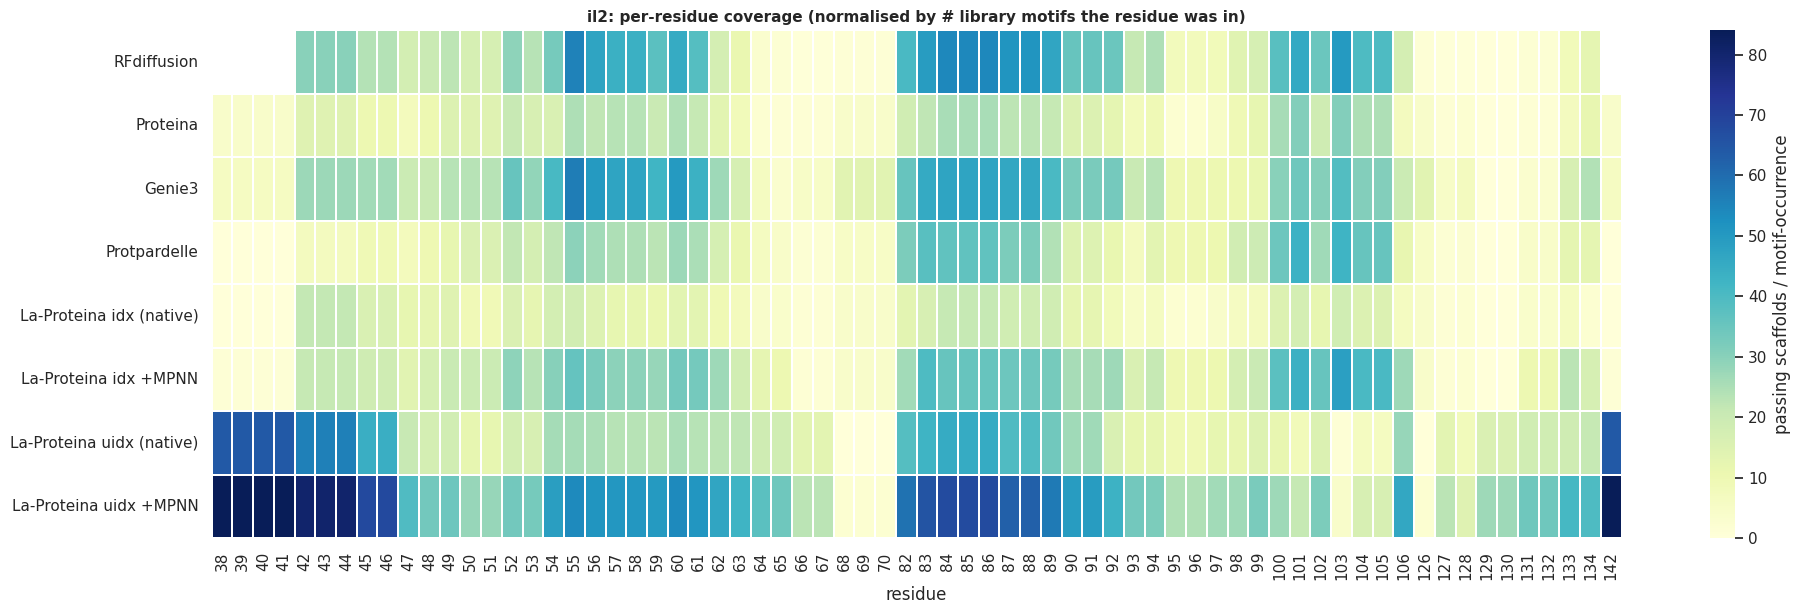

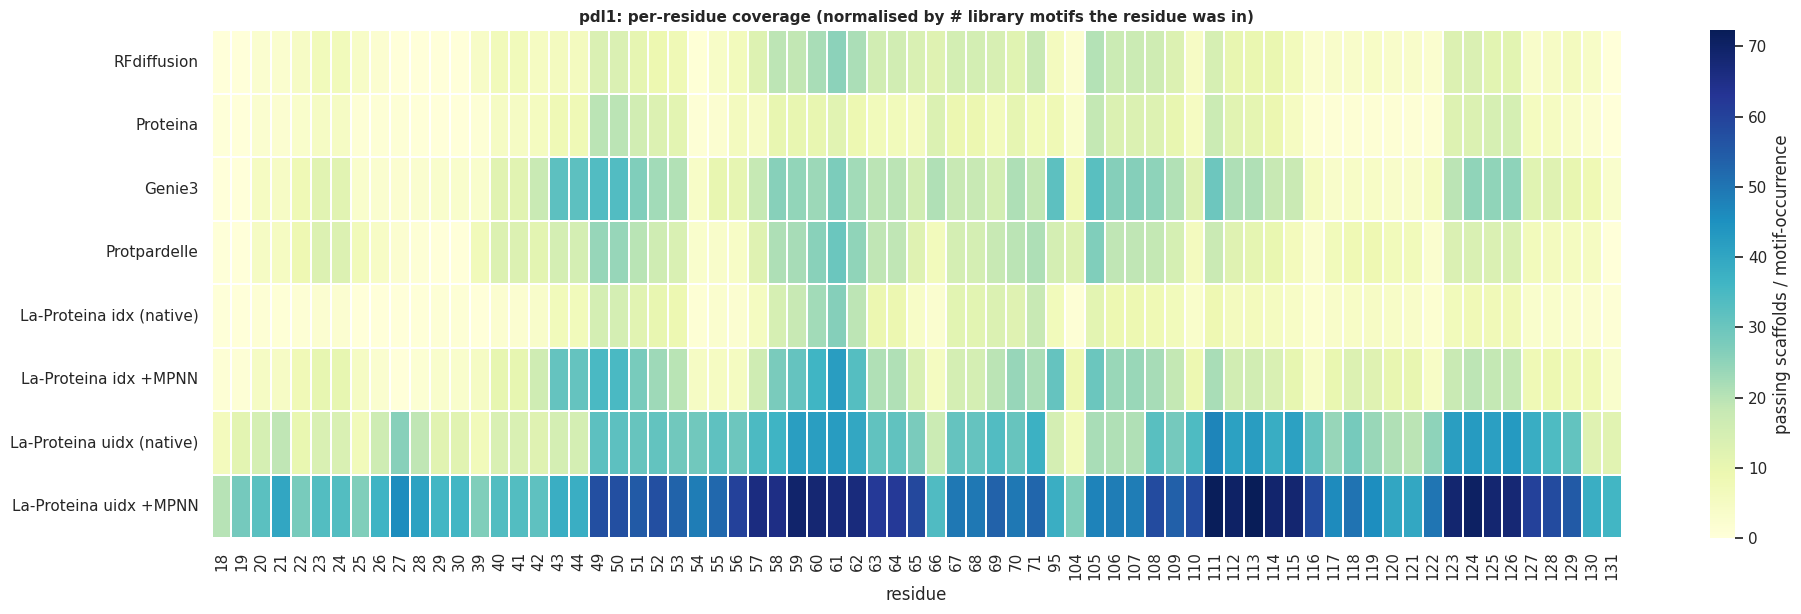

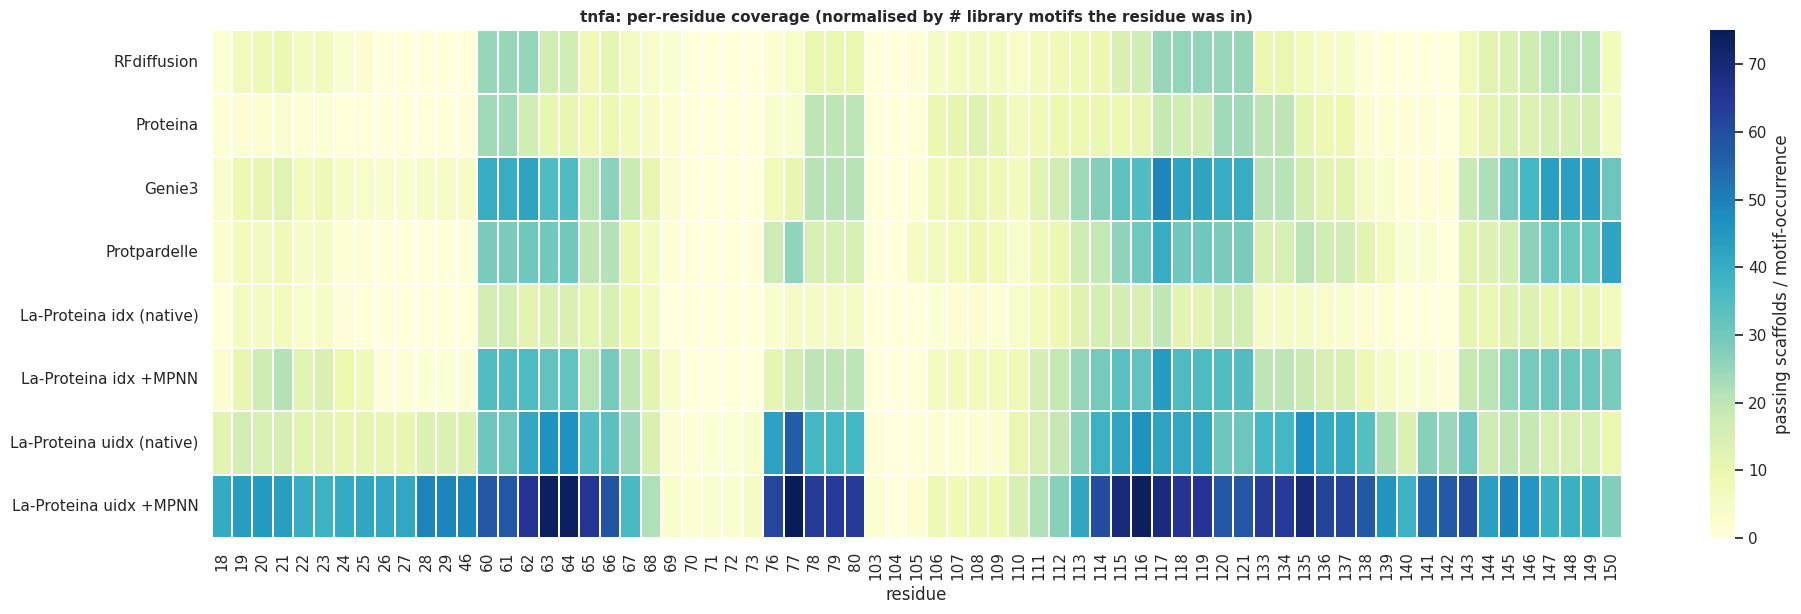

In [25]:
pr = pool[['task_name','pdb_name','motif_residues']].copy()
pr['residue'] = pr.motif_residues.astype(str).str.replace(',',' ').str.split()
pr = pr.explode('residue'); pr['residue'] = pd.to_numeric(pr.residue, errors='coerce')
pr = pr.dropna(subset=['residue']); pr['residue'] = pr.residue.astype(int)
res_denom = pr.groupby(['pdb_name','residue']).task_name.nunique().rename('n_motifs_in').reset_index()

msp = msucc.merge(pool[['task_name','pdb_name']], on='task_name', how='left')
mr  = msp.merge(pr[['task_name','residue']], on='task_name', how='left').dropna(subset=['residue'])
res_cov = (mr.groupby(['method','pdb_name','residue']).n_pass.sum().rename('pass_scaffolds').reset_index()
           .merge(res_denom, on=['pdb_name','residue'], how='left'))
res_cov['coverage'] = (res_cov.pass_scaffolds / res_cov.n_motifs_in).round(2)
display(res_cov.sort_values(['method','pdb_name','residue']).head(25))

def residue_coverage_heatmap(protein):
    d = res_cov[res_cov.pdb_name == protein]
    if d.empty: print('no data for', protein); return
    h = d.pivot_table(index='method', columns='residue', values='coverage').reindex(pres).dropna(how='all')
    fig, ax = plt.subplots(figsize=(min(20, 0.32*h.shape[1]+3), 0.6*len(h)+1.5))
    sns.heatmap(h, cmap='YlGnBu', cbar_kws={'label':'passing scaffolds / motif-occurrence'},
                linewidths=0.3, linecolor='white', ax=ax)
    ax.set_yticklabels([LABELS.get(m,m) for m in h.index], rotation=0)
    ax.set_xlabel('residue'); ax.set_ylabel('')
    ax.set_title(f'{protein}: per-residue coverage (normalised by # library motifs the residue was in)',
                 fontsize=11, fontweight='bold'); plt.tight_layout(); plt.show()

for p in sorted(res_cov.pdb_name.dropna().unique()):
    residue_coverage_heatmap(p)


## 14 - La-Proteina variants vs motif disjointedness

Native co-design vs MPNN-redesign vs (when ready) unindexed, by motif disjointedness (# fragments).
Tests whether unindexed's geometric flexibility helps the multi-segment (3+) motifs specifically.


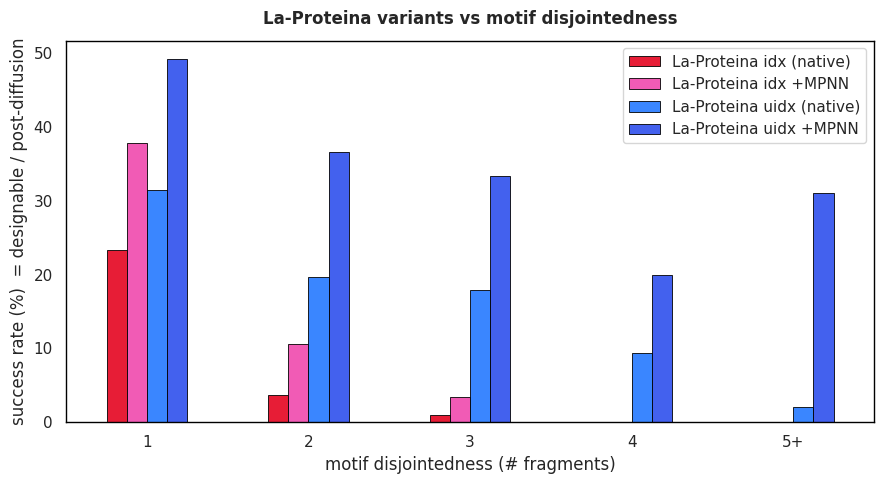

In [26]:
# all four La-Proteina variants: idx-native, idx+MPNN, uidx-native, uidx+MPNN (loaded via LOAD, section 14)
LAP = [m for m in ['laproteina','laproteina_mpnn','laproteina_unindexed','laproteina_unindexed_mpnn']
       if m in per_design.method.unique()]
LAPPAL = {'laproteina':'#e71d36','laproteina_mpnn':'#f15bb5',
          'laproteina_unindexed':'#3a86ff','laproteina_unindexed_mpnn':'#4361ee'}
per_design['ndisj'] = per_design.disjointed_parts.fillna(1).astype(int).clip(upper=5)
postdiff['ndisj']   = postdiff.disjointed_parts.fillna(1).astype(int).clip(upper=5)
g = srate(['ndisj','method']).unstack()
g = g[[m for m in LAP if m in g.columns]]
fig, ax = plt.subplots(figsize=(9,5))
g.plot(kind='bar', ax=ax, color=[LAPPAL[m] for m in g.columns], edgecolor='black', linewidth=0.6)
ax.set_xticklabels([f'{int(x)}+' if int(x)>=5 else str(int(x)) for x in g.index], rotation=0)
ax.set_xlabel('motif disjointedness (# fragments)')
ax.set_ylabel('success rate (%)  = designable / post-diffusion')
ax.set_title('La-Proteina variants vs motif disjointedness', fontsize=12, fontweight='bold', pad=12)
ax.legend([LABELS.get(m,m) for m in g.columns], frameon=True)
prettify(ax); plt.tight_layout(); plt.show()


## 15 · Method-wise motif pass rate
Passing scaffolds per motif, by method — mean and full per-motif distribution.

/scratch/tmp.12169595.bekessel/ipykernel_2254037/2100921476.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=_mp,x='method',y='n_pass',order=_ord,palette=PALETTE,ax=axR,fliersize=0,width=.6)
/scratch/tmp.12169595.bekessel/ipykernel_2254037/2100921476.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axR.set_xticklabels([LABELS.get(m,m) for m in _ord],rotation=30,ha='right')


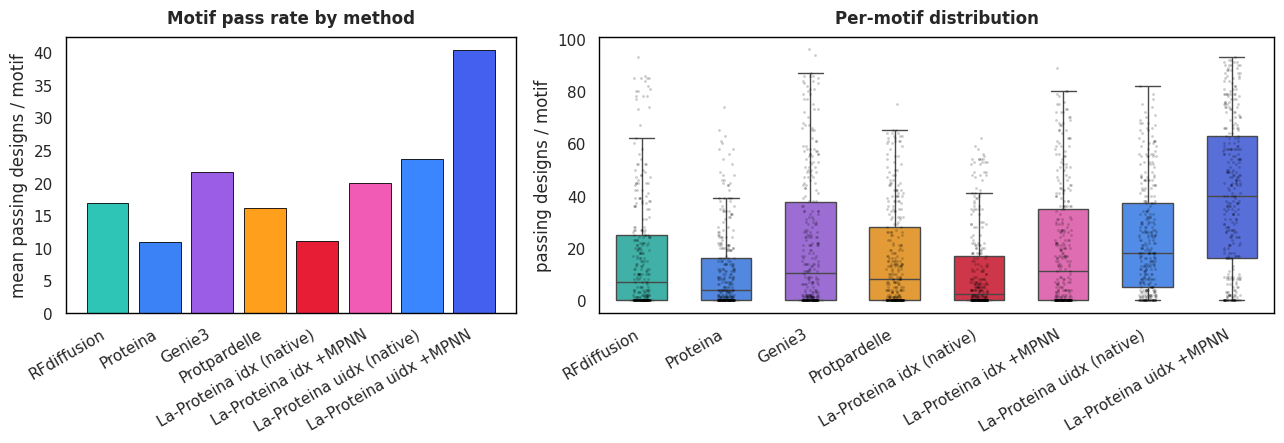

,mean,50%,max
method,,,
rfdiff,16.9,7.0,93.0
proteina,10.9,4.0,74.0
genie3,21.7,10.5,96.0
pp1c_bb,16.1,8.0,75.0
laproteina,11.0,2.5,62.0
laproteina_mpnn,20.0,11.0,89.0
laproteina_unindexed,23.6,18.0,82.0
laproteina_unindexed_mpnn,40.4,40.0,93.0


In [27]:
# ── §15 · Method-wise MOTIF pass rate ──────────────────────────────────────────────────────────
# Per motif, how many of its designs are designable, PER method: mean (bar) + full per-motif distribution.
_mp = (per_design[per_design.method.isin(METHODS)]
       .groupby(['method','task_name']).designable.sum().rename('n_pass').reset_index())
_ord = [m for m in METHODS if m in _mp.method.unique()]
fig,(axL,axR) = plt.subplots(1,2,figsize=(13,4.6),gridspec_kw={'width_ratios':[1,1.5]})
_mean = _mp.groupby('method').n_pass.mean().reindex(_ord)
axL.bar(range(len(_ord)),_mean.values,color=[PALETTE.get(m,'#888') for m in _ord],edgecolor='black',lw=.6)
axL.set_xticks(range(len(_ord))); axL.set_xticklabels([LABELS.get(m,m) for m in _ord],rotation=30,ha='right')
axL.set_ylabel('mean passing designs / motif'); axL.set_title('Motif pass rate by method',fontweight='bold',pad=10)
sns.boxplot(data=_mp,x='method',y='n_pass',order=_ord,palette=PALETTE,ax=axR,fliersize=0,width=.6)
sns.stripplot(data=_mp,x='method',y='n_pass',order=_ord,color='black',size=2,alpha=.2,ax=axR)
axR.set_xticklabels([LABELS.get(m,m) for m in _ord],rotation=30,ha='right')
axR.set_xlabel(''); axR.set_ylabel('passing designs / motif'); axR.set_title('Per-motif distribution',fontweight='bold',pad=10)
for ax in (axL,axR):
    try: prettify(ax)
    except Exception: pass
plt.tight_layout(); plt.show()
display(_mp.groupby('method').n_pass.describe()[['mean','50%','max']].reindex(_ord).round(1))


## 16 · La-Proteina idx vs uidx — feature correlation & rescues
Designability vs disjointedness / length / SSE, plus the motifs unindexed rescues (qualitative assets).

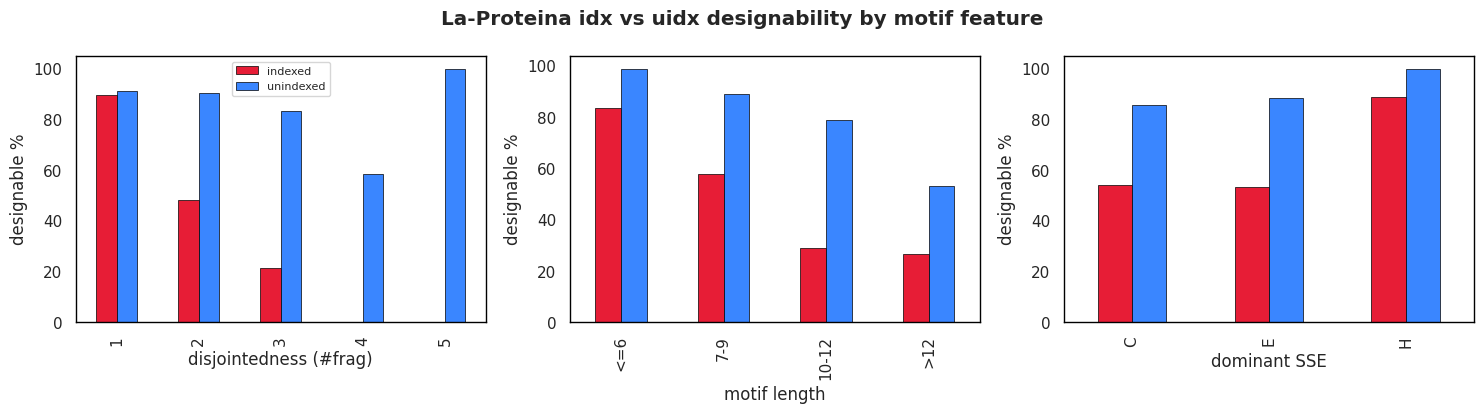

97 motifs rescued by unindexed (uidx designable, idx not). Representative (high disjointedness first):


,pdb_name,motif_num,ndisj,motif_length,dominant_sse,motif_residues
task_name,,,,,,
her2_m128_base,her2,128,5,10,C,81 82 91 126 127 128 129 130 155 157
her2_m268_base,her2,268,4,12,E,246 266 267 268 269 270 272 273 274 287 288 289
her2_m595_base,her2,595,4,11,E,568 578 593 594 595 596 597 599 600 601 602
her2_m128_filled,her2,128,4,11,C,81 82 91 126 127 128 129 130 155 156 157
il2_m65_base,il2,65,4,9,C,63 64 65 66 67 82 127 131 132
tnfa_m27_base,tnfa,27,4,9,C,18 19 22 25 26 27 28 29 46
her2_m316_base,her2,316,4,8,C,296 298 312 314 315 316 317 318
il13_m111_base,il13,111,4,8,C,5 6 9 106 109 110 111 112
her2_m308_base,her2,308,3,12,E,282 283 284 299 300 301 302 306 307 308 309 310


representative scaffold PDBs: /cluster/work/wicky/bekessel/motif_library/runs/lib_interface_pad5_uidx/laproteina/scaffolds/<task>_<sample>.pdb  (task e.g. her2_m128_base)


In [28]:
# ── §16 · La-Proteina idx vs uidx — designability by motif feature + representative rescues ──────
# Self-contained on the greedy-relocalized scores. Correlates designability with disjointedness / length / SSE,
# and lists the high-disjointedness motifs unindexed rescues (for qualitative inspection).
_IDX=f'{RUN}/laproteina/af3_refold_scores_greedy.csv'; _UIDX=f'{RUN_UIDX}/laproteina/af3_refold_scores.csv'
def _dpass(p):
    d=pd.read_csv(p); d.columns=[c.strip() for c in d.columns]; d['task_name']=d.design_name.map(to_task)
    ok=(d.motifRMSD<=MOTIF_RMSD_MAX)&(d.scRMSD<=SC_RMSD_MAX)&(d.ranking_score>=RANK_MIN)
    return set(d.loc[ok,'task_name']), set(d.task_name)
if os.path.exists(_IDX) and os.path.exists(_UIDX):
    ip,ia=_dpass(_IDX); up,ua=_dpass(_UIDX); common=ia&ua
    feats=pool.drop_duplicates('task_name').set_index('task_name')[['disjointed_parts','motif_length','dominant_sse','pdb_name','motif_num','motif_residues']]
    F=feats[feats.index.isin(common)].copy()
    F['idx']=F.index.isin(ip).astype(int); F['uidx']=F.index.isin(up).astype(int)
    F['ndisj']=F.disjointed_parts.fillna(1).astype(int).clip(upper=5)
    F['len_bin']=pd.cut(F.motif_length,[0,6,9,12,99],labels=['<=6','7-9','10-12','>12'])
    fig,axs=plt.subplots(1,3,figsize=(15,4.2))
    for ax,(col,lab) in zip(axs,[('ndisj','disjointedness (#frag)'),('len_bin','motif length'),('dominant_sse','dominant SSE')]):
        g=(F.groupby(col)[['idx','uidx']].mean()*100)
        g.plot(kind='bar',ax=ax,color=['#e71d36','#3a86ff'],edgecolor='black',lw=.5,legend=(ax is axs[0]))
        ax.set_ylabel('designable %'); ax.set_xlabel(lab)
        if ax is axs[0]: ax.legend(['indexed','unindexed'],fontsize=8,frameon=True)
        try: prettify(ax)
        except Exception: pass
    plt.suptitle('La-Proteina idx vs uidx designability by motif feature',fontweight='bold'); plt.tight_layout(); plt.show()
    resc=F[(F.uidx==1)&(F.idx==0)].sort_values(['ndisj','motif_length'],ascending=False)
    print(f'{len(resc)} motifs rescued by unindexed (uidx designable, idx not). Representative (high disjointedness first):')
    display(resc[['pdb_name','motif_num','ndisj','motif_length','dominant_sse','motif_residues']].head(12))
    print(f'representative scaffold PDBs: {RUN_UIDX}/laproteina/scaffolds/<task>_<sample>.pdb  (task e.g. '+ (resc.index[0] if len(resc) else '<task>')+')')
else:
    print('greedy score CSVs missing — run unindexed_score.py + 5_score --positions first (see §14 pipeline)')


## 16C · Contig-scaling — baseline (1-5) vs native diverse linkers (asym vs sym)
Same 56 motifs, scaffolded three ways: **baseline** (uniform 1-5 linker, 2-10/35-75 flanks), **native_asym** (native-gap linker ranges, same asym flanks), **native_sym** (native linkers, symmetric 0-60 flanks). Comparison 1 = linker effect (baseline vs native_asym); comparison 2 = padding symmetry (native_asym vs native_sym). motifRMSD/scRMSD, scaffold length, motif pass rate, and pass-by-disjointedness.

/scratch/tmp.11931365.bekessel/ipykernel_3159353/2500430313.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=allc[allc.motifRMSD<6],x='mode',y='motifRMSD',order=ORDER,palette=CPAL,ax=axs[0,0],cut=0)
/scratch/tmp.11931365.bekessel/ipykernel_3159353/2500430313.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=allc[allc.scRMSD<8],x='mode',y='scRMSD',order=ORDER,palette=CPAL,ax=axs[0,1],cut=0)
/scratch/tmp.11931365.bekessel/ipykernel_3159353/2500430313.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=lenf,x='mo

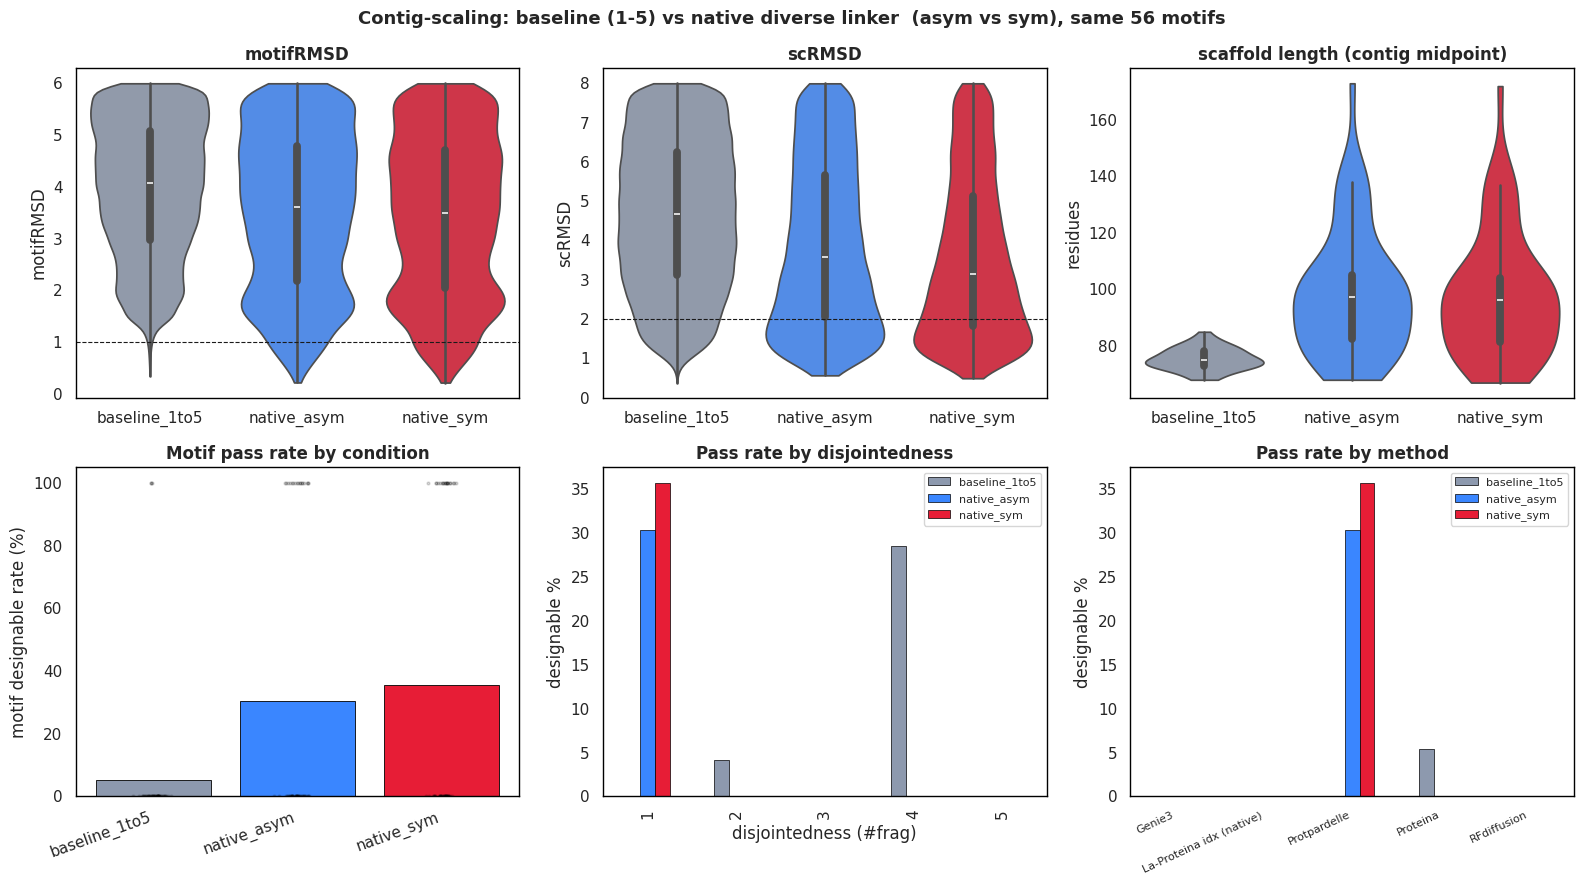

per-condition summary (per-design N, motif pass rate %, median motifRMSD/scRMSD):


,n_design,med_motifRMSD,med_scRMSD,motif_pass_%
mode,,,,
baseline_1to5,162688,4.882,6.327,5.4
native_asym,20544,4.882,7.086,30.4
native_sym,22216,4.568,6.519,35.7


In [67]:
# ── §16C · Contig-scaling comparison (baseline vs native_asym vs native_sym) ─────────────────────
RUN_CS = '/cluster/work/wicky/bekessel/motif_library/runs/lib_interface_pad5_contigscale'
CS_METHODS = ['rfdiff','proteina','genie3','pp1c_bb','laproteina']
ORDER = ['baseline_1to5','native_asym','native_sym']
CPAL  = {'baseline_1to5':'#8d99ae','native_asym':'#3a86ff','native_sym':'#e71d36'}

def _load_scores(run, methods):
    fr=[]
    for m in methods:
        p=f"{run}/{m}/af3_refold_scores.csv"
        if not os.path.exists(p): continue
        x=pd.read_csv(p); x.columns=[c.strip() for c in x.columns]; x['method']=m
        x['task_name']=x.design_name.map(to_task); fr.append(x[['method','task_name','design_name','motifRMSD','scRMSD','ranking_score']])
    return pd.concat(fr,ignore_index=True) if fr else pd.DataFrame()

cs = _load_scores(RUN_CS, CS_METHODS)
if cs.empty:
    print('contig-scale scores not landed yet — score the contigscale run, then re-run this cell')
else:
    cs['mode'] = np.where(cs.task_name.str.endswith('__native_sym'),'native_sym',
                  np.where(cs.task_name.str.endswith('__native_asym'),'native_asym','?'))
    cs['base_task'] = cs.task_name.str.replace('__native_asym','',regex=False).str.replace('__native_sym','',regex=False)
    motifs56 = set(cs.base_task.unique())
    bl = _load_scores(RUN, CS_METHODS)
    bl = bl[bl.task_name.isin(motifs56)].copy(); bl['mode']='baseline_1to5'; bl['base_task']=bl.task_name
    allc = pd.concat([bl, cs], ignore_index=True)
    allc['pass3'] = ((allc.motifRMSD<=MOTIF_RMSD_MAX)&(allc.scRMSD<=SC_RMSD_MAX)&(allc.ranking_score>=RANK_MIN)).astype(int)
    dj = pool.drop_duplicates('task_name').set_index('task_name').disjointed_parts
    allc['ndisj'] = allc.base_task.map(dj).fillna(1).astype(int).clip(upper=5)

    # scaffold TARGET length (contig range midpoint) per (base_task, mode), from the manifests
    def _man_len(run):
        m=pd.read_csv(f"{run}/manifest.csv"); m['mid']=(m.motif_min_length+m.motif_max_length)/2; return m
    mcs=_man_len(RUN_CS); mcs['mode']=np.where(mcs.task_name.str.endswith('__native_sym'),'native_sym','native_asym')
    mcs['base_task']=mcs.task_name.str.replace('__native_asym','',regex=False).str.replace('__native_sym','',regex=False)
    mbl=_man_len(RUN); mbl=mbl[mbl.task_name.isin(motifs56)].copy(); mbl['mode']='baseline_1to5'; mbl['base_task']=mbl.task_name
    lenf=pd.concat([mbl[['base_task','mode','mid']],mcs[['base_task','mode','mid']]],ignore_index=True)

    # per-motif pass rate: designable iff any design of that motif passes, per condition
    pm = allc.groupby(['mode','base_task']).pass3.max().rename('designable').reset_index()
    pm['ndisj']=pm.base_task.map(dj).fillna(1).astype(int).clip(upper=5)

    fig,axs=plt.subplots(2,3,figsize=(16,9))
    # (0,0) motifRMSD violin
    sns.violinplot(data=allc[allc.motifRMSD<6],x='mode',y='motifRMSD',order=ORDER,palette=CPAL,ax=axs[0,0],cut=0)
    axs[0,0].axhline(1,color='k',ls='--',lw=.8); axs[0,0].set_title('motifRMSD',fontweight='bold'); axs[0,0].set_xlabel('')
    # (0,1) scRMSD violin
    sns.violinplot(data=allc[allc.scRMSD<8],x='mode',y='scRMSD',order=ORDER,palette=CPAL,ax=axs[0,1],cut=0)
    axs[0,1].axhline(2,color='k',ls='--',lw=.8); axs[0,1].set_title('scRMSD',fontweight='bold'); axs[0,1].set_xlabel('')
    # (0,2) scaffold length violin
    sns.violinplot(data=lenf,x='mode',y='mid',order=ORDER,palette=CPAL,ax=axs[0,2],cut=0)
    axs[0,2].set_title('scaffold length (contig midpoint)',fontweight='bold'); axs[0,2].set_ylabel('residues'); axs[0,2].set_xlabel('')
    # (1,0) overall motif pass rate (bar) + per-motif points
    pr = pm.groupby('mode').designable.mean().reindex(ORDER)*100
    axs[1,0].bar(range(3),pr.values,color=[CPAL[m] for m in ORDER],edgecolor='black',lw=.6)
    for i,m in enumerate(ORDER):
        yy=pm[pm['mode']==m].designable.values*100
        axs[1,0].scatter(np.random.normal(i,0.05,len(yy)),yy,s=4,alpha=.15,color='black')
    axs[1,0].set_xticks(range(3)); axs[1,0].set_xticklabels(ORDER,rotation=20,ha='right')
    axs[1,0].set_ylabel('motif designable rate (%)'); axs[1,0].set_title('Motif pass rate by condition',fontweight='bold')
    # (1,1) pass rate by disjointedness x condition
    gp=(pm.groupby(['ndisj','mode']).designable.mean().unstack()*100).reindex(columns=ORDER)
    gp.plot(kind='bar',ax=axs[1,1],color=[CPAL[m] for m in ORDER],edgecolor='black',lw=.5)
    axs[1,1].set_ylabel('designable %'); axs[1,1].set_xlabel('disjointedness (#frag)'); axs[1,1].set_title('Pass rate by disjointedness',fontweight='bold'); axs[1,1].legend(fontsize=8)
    # (1,2) pass rate by method x condition
    gm=(allc.groupby(['method','base_task','mode']).pass3.max().reset_index()
          .groupby(['method','mode']).pass3.mean().unstack()*100).reindex(columns=ORDER)
    gm.plot(kind='bar',ax=axs[1,2],color=[CPAL[m] for m in ORDER],edgecolor='black',lw=.5)
    axs[1,2].set_ylabel('designable %'); axs[1,2].set_xlabel(''); axs[1,2].set_title('Pass rate by method',fontweight='bold'); axs[1,2].legend(fontsize=8)
    axs[1,2].set_xticklabels([LABELS.get(t.get_text(),t.get_text()) for t in axs[1,2].get_xticklabels()],rotation=25,ha='right',fontsize=8)
    for ax in axs.ravel():
        try: prettify(ax)
        except Exception: pass
    plt.suptitle('Contig-scaling: baseline (1-5) vs native diverse linker  (asym vs sym), same 56 motifs',fontweight='bold',fontsize=13)
    plt.tight_layout(); plt.show()
    print('per-condition summary (per-design N, motif pass rate %, median motifRMSD/scRMSD):')
    _sm=allc.groupby('mode').agg(n_design=('pass3','size'),med_motifRMSD=('motifRMSD','median'),med_scRMSD=('scRMSD','median')).reindex(ORDER)
    _sm['motif_pass_%']=(pm.groupby('mode').designable.mean().reindex(ORDER)*100).round(1)
    display(_sm.round(3))


## 16F · Contig-scaling — absolute passing-scaffold counts per motif


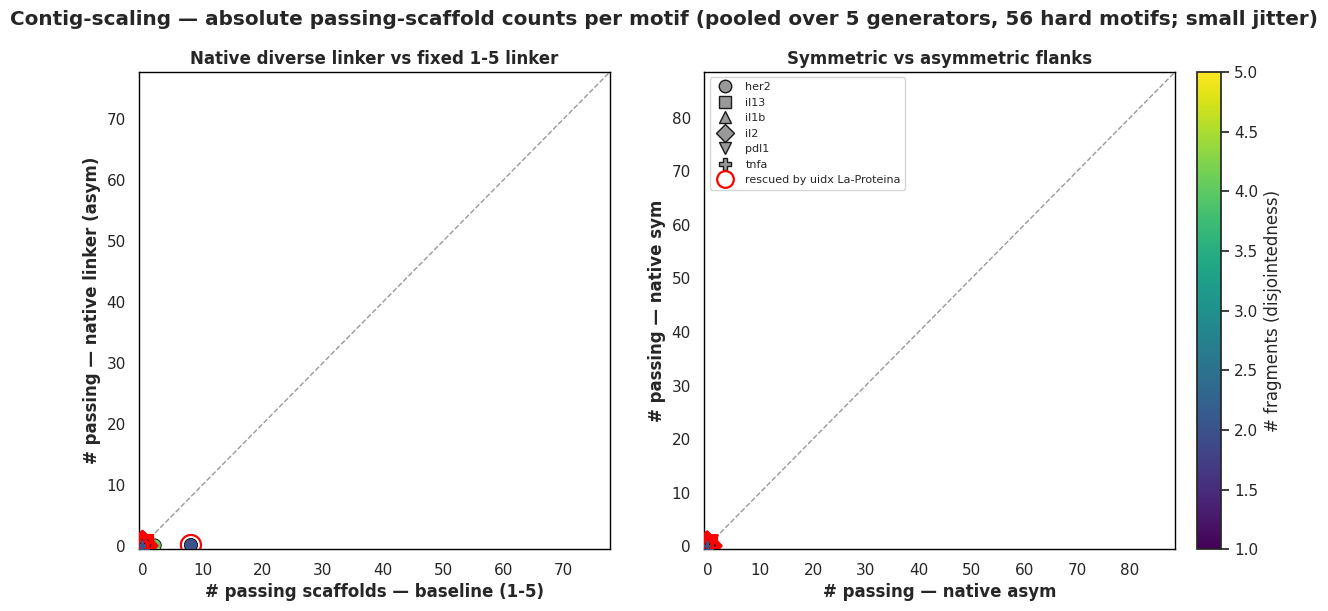

motifs with >0 passers:  baseline=3  native_asym=17  native_sym=20  (of 112)
motifs La-Proteina uidx rescued (baseline uidx run): 34 of 112
motifs with ZERO baseline passers but >0 with the native linker: 17


mode,baseline_1to5,native_asym,native_sym,ndisj,pdb,uidx_ok
base_task,,,,,,
sample_pdl1_m58_filled,0,72,82,1,NaN,False
sample_il13_m112_base,0,17,43,1,NaN,False
sample_her2_m272_base,0,15,16,1,NaN,False
sample_il2_m95_base,0,14,8,1,NaN,False
sample_il1b_m93_base,0,11,9,1,NaN,False
sample_il1b_m25_base,0,9,2,1,NaN,False
sample_her2_m308_filled,0,9,25,1,NaN,False
sample_il1b_m38_base,0,9,35,1,NaN,False
sample_her2_m566_base,0,7,8,1,NaN,False


In [29]:
# ── §16F · Contig-scaling ABSOLUTE numbers: passing scaffolds per motif ──────────────────────────
# Two paired scatters over the 56 hard (all-failure) motifs; each point = one motif.
#   LEFT  : x = # passing scaffolds under BASELINE fixed 1-5 linker,   y = under NATIVE diverse linker (asym)
#           -> does a native-scaled linker recover designs the fixed 1-5 linker missed?  (above y=x line = yes)
#   RIGHT : x = # passing scaffolds NATIVE-ASYM,                        y = NATIVE-SYM
#           -> do symmetric flanks add anything beyond the native linker?                (above y=x = yes)
# A "passing scaffold" = a design with motifRMSD<=1 & scRMSD<=2 & rank>=0.75, POOLED across all 5 generators.
# Colour = disjointedness (#fragments); marker = source protein; motifs that La-Proteina UNINDEXED actually
# rescued in the baseline uidx run are ringed in red -> shows whether linker-recovered motifs overlap uidx's.
# SELF-CONTAINED: rebuilds its own contig-scale frame, so it runs even if §16C above was not executed.
RUN_CS = globals().get('RUN_CS', '/cluster/work/wicky/bekessel/motif_library/runs/lib_interface_pad5_contigscale')
CS_METHODS = ['rfdiff','proteina','genie3','pp1c_bb','laproteina']
ORDER = ['baseline_1to5','native_asym','native_sym']

def _cs_load(run, methods):
    fr = []
    for m in methods:
        p = f"{run}/{m}/af3_refold_scores.csv"
        if not os.path.exists(p): continue
        x = pd.read_csv(p); x.columns = [c.strip() for c in x.columns]; x['method'] = m
        x['task_name'] = x.design_name.map(to_task)
        fr.append(x[['method','task_name','design_name','motifRMSD','scRMSD','ranking_score']])
    return pd.concat(fr, ignore_index=True) if fr else pd.DataFrame()

_cs = _cs_load(RUN_CS, CS_METHODS)
assert not _cs.empty, f"no contig-scale scores under {RUN_CS} — score that run first"
_cs['mode'] = np.where(_cs.task_name.str.endswith('__native_sym'), 'native_sym',
               np.where(_cs.task_name.str.endswith('__native_asym'), 'native_asym', '?'))
_cs['base_task'] = (_cs.task_name.str.replace('__native_asym','',regex=False)
                                 .str.replace('__native_sym','',regex=False))
motifs56 = set(_cs.base_task.unique())
_bl = _cs_load(RUN, CS_METHODS)
_bl = _bl[_bl.task_name.isin(motifs56)].copy(); _bl['mode'] = 'baseline_1to5'; _bl['base_task'] = _bl.task_name
allc = pd.concat([_bl, _cs], ignore_index=True)
allc['pass3'] = ((allc.motifRMSD <= MOTIF_RMSD_MAX) & (allc.scRMSD <= SC_RMSD_MAX) &
                 (allc.ranking_score >= RANK_MIN)).astype(int)
dj = pool.drop_duplicates('task_name').set_index('task_name').disjointed_parts

cnt = allc.groupby(['base_task','mode']).pass3.sum().unstack(fill_value=0)
for c in ORDER:
    if c not in cnt.columns: cnt[c] = 0
cnt = cnt[ORDER].copy()
cnt['ndisj'] = pd.Series(cnt.index.map(dj), index=cnt.index).fillna(1).astype(int).clip(upper=5)
cnt['pdb']   = cnt.index.map(pool.drop_duplicates('task_name').set_index('task_name').pdb_name)

# which of these 56 motifs did La-Proteina UNINDEXED rescue (>=1 designable) in the baseline uidx run?
uidx_rescued = set(per_design[(per_design.method == 'laproteina_unindexed') &
                              (per_design.designable == 1)].task_name)
cnt['uidx_ok'] = [t in uidx_rescued for t in cnt.index]

PROT_MARK = {p: mk for p, mk in zip(sorted(cnt.pdb.dropna().unique()), ['o','s','^','D','v','P'])}
rng = np.random.default_rng(0)
fig, axs = plt.subplots(1, 2, figsize=(14, 6.2))

def _scatter(ax, xc, yc, xl, yl, ttl):
    mx = max(cnt[xc].max(), cnt[yc].max(), 1)
    ax.plot([-0.5, mx*1.08], [-0.5, mx*1.08], ls='--', color='0.6', lw=1, zorder=0)
    sc = None
    for p, mk in PROT_MARK.items():
        sub = cnt[cnt.pdb == p]
        jx = rng.normal(0, 0.06, len(sub)); jy = rng.normal(0, 0.06, len(sub))  # reveal overlapping integers
        sc = ax.scatter(sub[xc]+jx, sub[yc]+jy, c=sub.ndisj, cmap='viridis', vmin=1, vmax=5, marker=mk,
                        s=90, edgecolor='black', linewidth=.6, label=p, zorder=3)
        rgm = sub[sub.uidx_ok]
        ax.scatter(rgm[xc]+jx[sub.uidx_ok.values], rgm[yc]+jy[sub.uidx_ok.values],
                   facecolors='none', edgecolors='red', marker=mk, s=210, linewidth=1.6, zorder=4)
    ax.set_xlabel(xl, fontweight='bold'); ax.set_ylabel(yl, fontweight='bold')
    ax.set_title(ttl, fontweight='bold')
    ax.set_xlim(-0.6, mx*1.08); ax.set_ylim(-0.6, mx*1.08)
    try: prettify(ax)
    except Exception: pass
    return sc

sc = _scatter(axs[0], 'baseline_1to5', 'native_asym',
              '# passing scaffolds — baseline (1-5)', '# passing — native linker (asym)',
              'Native diverse linker vs fixed 1-5 linker')
_scatter(axs[1], 'native_asym', 'native_sym',
         '# passing — native asym', '# passing — native sym', 'Symmetric vs asymmetric flanks')
cb = fig.colorbar(sc, ax=axs, fraction=0.025, pad=0.02); cb.set_label('# fragments (disjointedness)')
from matplotlib.lines import Line2D
leg = [Line2D([0],[0], marker=mk, color='w', markerfacecolor='0.6', markeredgecolor='k',
              markersize=9, label=p) for p, mk in PROT_MARK.items()]
leg.append(Line2D([0],[0], marker='o', color='w', markerfacecolor='none', markeredgecolor='red',
                  markersize=12, markeredgewidth=1.6, label='rescued by uidx La-Proteina'))
axs[1].legend(handles=leg, fontsize=8, loc='upper left', frameon=True)
plt.suptitle('Contig-scaling — absolute passing-scaffold counts per motif '
             '(pooled over 5 generators, 56 hard motifs; small jitter)', fontweight='bold')
plt.show()

print(f"motifs with >0 passers:  baseline={int((cnt.baseline_1to5>0).sum())}  "
      f"native_asym={int((cnt.native_asym>0).sum())}  native_sym={int((cnt.native_sym>0).sum())}  (of {len(cnt)})")
print(f"motifs La-Proteina uidx rescued (baseline uidx run): {int(cnt.uidx_ok.sum())} of {len(cnt)}")
gained = cnt[(cnt.baseline_1to5 == 0) & (cnt.native_asym > 0)]
print(f"motifs with ZERO baseline passers but >0 with the native linker: {len(gained)}")
display(cnt.sort_values('native_asym', ascending=False).head(15))


## 16E · The 56 hard motifs — simple base vs filled overview
One row per (antigen, motif number); base & filled variants side by side. `filled` fills the native sequence gaps between fragments → fewer fragments. Shows at a glance which motifs are disjointed and how much filling simplifies them.

45 distinct motifs (40 base + 16 filled = 56 tasks; 11 have both variants)


/scratch/tmp.12004195.bekessel/ipykernel_1165790/939716812.py:11: PerformanceWarning: indexing past lexsort depth may impact performance.
  tab['SSE']=[sse.get((p,m),'') for p,m in zip(tab.pdb_name,tab.motif_num)]


,pdb_name,motif_num,SSE,disj_base,disj_filled,len_base,len_filled
0,her2,128,pdb_name motif_num her2 128 C ...,5.0,4.0,10.0,11.0
1,her2,231,pdb_name motif_num her2 231 C N...,2.0,NaN,10.0,NaN
2,her2,235,pdb_name motif_num her2 235 C N...,3.0,NaN,7.0,NaN
3,her2,237,pdb_name motif_num her2 237 E ...,3.0,2.0,12.0,14.0
4,her2,241,pdb_name motif_num her2 241 E N...,2.0,NaN,9.0,NaN
5,her2,272,pdb_name motif_num her2 272 E N...,2.0,NaN,10.0,NaN
6,her2,288,pdb_name motif_num her2 288 E ...,3.0,2.0,10.0,11.0
7,her2,296,pdb_name motif_num her2 296 C N...,3.0,NaN,8.0,NaN
8,her2,298,pdb_name motif_num her2 298 E ...,4.0,2.0,11.0,16.0
9,her2,308,pdb_name motif_num her2 308 E ...,3.0,2.0,12.0,15.0


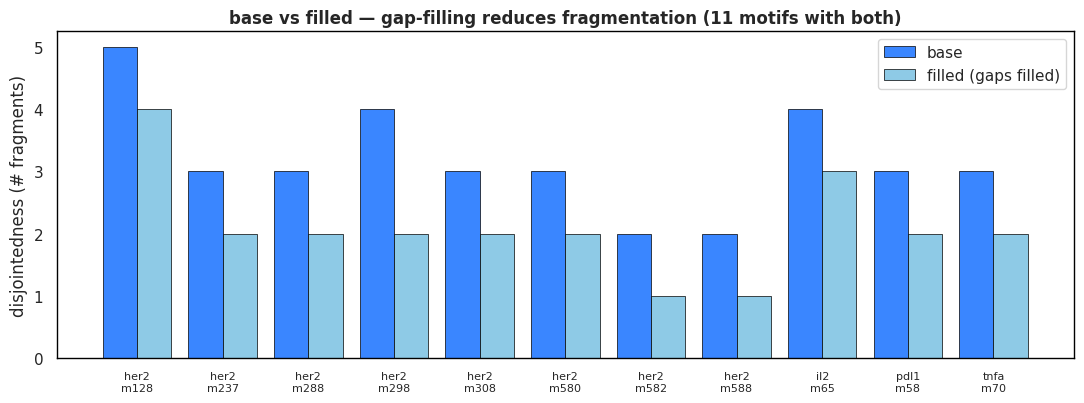

filling reduced fragments in 11/11 motifs; 2 became contiguous.


In [20]:
# ── §16E · Simple paired base|filled table + disjointedness bar ──────────────────────────────────
RUN_CS = 'RUN_CS' in dir() and RUN_CS or '/cluster/work/wicky/bekessel/motif_library/runs/lib_interface_pad5_contigscale'
_bt=(pd.read_csv(f"{RUN_CS}/manifest.csv").task_name
       .str.replace('__native_asym','',regex=False).str.replace('__native_sym','',regex=False))
M=pool[pool.task_name.isin(set(_bt))].drop_duplicates('task_name').copy()
M['ndisj']=M.disjointed_parts.fillna(1).astype(int)
tab=M.pivot_table(index=['pdb_name','motif_num'],columns='variant',values=['ndisj','motif_length'],aggfunc='first')
tab.columns=[f"{v}_{var}" for v,var in tab.columns]
tab=tab.reset_index().sort_values(['pdb_name','motif_num'])
sse=M.set_index(['pdb_name','motif_num']).dominant_sse
tab['SSE']=[sse.get((p,m),'') for p,m in zip(tab.pdb_name,tab.motif_num)]
_cols=['pdb_name','motif_num','SSE']+[c for c in ['ndisj_base','ndisj_filled','motif_length_base','motif_length_filled'] if c in tab]
print(f"{len(tab)} distinct motifs (40 base + 16 filled = 56 tasks; 11 have both variants)")
display(tab[_cols].round(0).rename(columns={'ndisj_base':'disj_base','ndisj_filled':'disj_filled',
                                            'motif_length_base':'len_base','motif_length_filled':'len_filled'}))

if 'ndisj_filled' in tab:
    both=tab.dropna(subset=['ndisj_base','ndisj_filled'])
    if len(both):
        lbl=[f"{p}\nm{int(m)}" for p,m in zip(both.pdb_name,both.motif_num)]
        x=np.arange(len(both)); w=0.4
        fig,ax=plt.subplots(figsize=(11,4.2))
        ax.bar(x-w/2,both.ndisj_base,w,label='base',color='#3a86ff',edgecolor='black',lw=.5)
        ax.bar(x+w/2,both.ndisj_filled,w,label='filled (gaps filled)',color='#8ecae6',edgecolor='black',lw=.5)
        ax.set_xticks(x); ax.set_xticklabels(lbl,fontsize=8)
        ax.set_ylabel('disjointedness (# fragments)')
        ax.set_title('base vs filled — gap-filling reduces fragmentation (11 motifs with both)',fontweight='bold')
        ax.legend()
        try: prettify(ax)
        except Exception: pass
        plt.tight_layout(); plt.show()
        print(f"filling reduced fragments in {int((both.ndisj_filled<both.ndisj_base).sum())}/{len(both)} motifs; "
              f"{int((both.ndisj_filled==1).sum())} became contiguous.")


## 17 · Motif burial — ΔRSA (de novo vs native)
Full-structure RSA of each refold at the motif positions vs native library RSA (Task 2 output).

## 18 · Sanity check vs Lisa's benchmark
Shared HER2 / PD-L1 motifs, normalized for trajectory/sequence sampling differences.

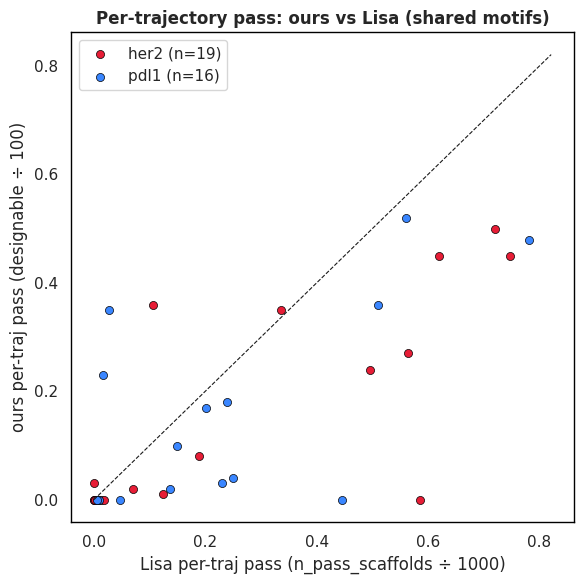

shared motifs: 35  |  Spearman rho = 0.71
CAVEATS: normalized traj 1000->100 & seqs 20->8; small-N motifs (few passers) are noisy; a residue can inflate success via multiple overlapping motifs.


,pdb,motif_num,disjointed_parts,lisa_per_traj,our_per_traj,n_passing_scaffolds,our_pass
19,pdl1,49,1,0.782,0.48,782,48
13,her2,598,1,0.747,0.45,747,45
12,her2,596,1,0.721,0.50,721,50
4,her2,571,1,0.620,0.45,620,45
17,her2,606,1,0.586,0.00,586,0
18,her2,607,1,0.564,0.27,564,27
28,pdl1,71,1,0.560,0.52,560,52
23,pdl1,61,1,0.510,0.36,510,36
16,her2,605,1,0.496,0.24,496,24
33,pdl1,121,1,0.446,0.00,446,0


In [59]:
# ── §18 · Sanity check vs Lisa's benchmark (shared HER2 / PD-L1 motifs) ─────────────────────────
# Normalizes for pipeline differences (Lisa: 1000 traj × 20 seqs ; ours: 100 traj × 8 seqs) and compares
# per-trajectory pass rate on the shared motif_num set. Absolute counts shown (small-N caveat).
RESULTS='/cluster/work/wicky/bekessel/results'
LISA={'her2':('1n8z_trastuzumab_motif_summary.csv',1000),'pdl1':('3bis_atezolizumab_motif_summary.csv',1000)}
OURS_TRAJ=100
_pm=pool.drop_duplicates('task_name').set_index('task_name')[['pdb_name','motif_num']]
_od=per_design[per_design.method == "rfdiff"].copy()
_od['pdb_name']=_od.task_name.map(_pm.pdb_name); _od['motif_num']=_od.task_name.map(_pm.motif_num)
_rows=[]
for pdbn,(f,ntraj) in LISA.items():
    lp=os.path.join(RESULTS,f)
    if not os.path.exists(lp): print('missing',lp); continue
    L=pd.read_csv(lp); L['motif_num']=L.motif_num.astype(int); L['lisa_per_traj']=L.n_passing_scaffolds #/ntraj
    O=(_od[_od.pdb_name==pdbn].dropna(subset=['motif_num']).assign(motif_num=lambda x:x.motif_num.astype(int))
        .groupby('motif_num').agg(our_pass=('designable','sum')).reset_index())
    O['our_per_traj']=O.our_pass/OURS_TRAJ
    J=O.merge(L[['motif_num','lisa_per_traj','n_passing_scaffolds','disjointed_parts']],on='motif_num',how='inner'); J['pdb']=pdbn
    _rows.append(J)
if _rows:
    J=pd.concat(_rows,ignore_index=True)
    fig,ax=plt.subplots(figsize=(6,6))
    for pdbn,c in [('her2','#e71d36'),('pdl1','#3a86ff')]:
        s=J[J.pdb==pdbn]
        if len(s): ax.scatter(s.lisa_per_traj,s.our_per_traj,label=f'{pdbn} (n={len(s)})',color=c,s=34,edgecolor='black',lw=.5)
    mx=max(J.lisa_per_traj.max(),J.our_per_traj.max(),1e-3)*1.05
    ax.plot([0,mx],[0,mx],'k--',lw=.8); ax.set_xlabel('Lisa per-traj pass (n_pass_scaffolds ÷ 1000)')
    ax.set_ylabel('ours per-traj pass (designable ÷ 100)'); ax.set_title('Per-trajectory pass: ours vs Lisa (shared motifs)',fontweight='bold'); ax.legend()
    try: prettify(ax)
    except Exception: pass
    plt.tight_layout(); plt.show()
    try:
        from scipy.stats import spearmanr
        rho=spearmanr(J.lisa_per_traj,J.our_per_traj).correlation
    except Exception: rho=float('nan')
    print(f'shared motifs: {len(J)}  |  Spearman rho = {rho:.2f}')
    print('CAVEATS: normalized traj 1000->100 & seqs 20->8; small-N motifs (few passers) are noisy; a residue can inflate success via multiple overlapping motifs.')
    display(J[['pdb','motif_num','disjointed_parts','lisa_per_traj','our_per_traj','n_passing_scaffolds','our_pass']].sort_values('lisa_per_traj',ascending=False).round(3).head(20))
else:
    print('no Lisa motif_summary files found under', RESULTS)


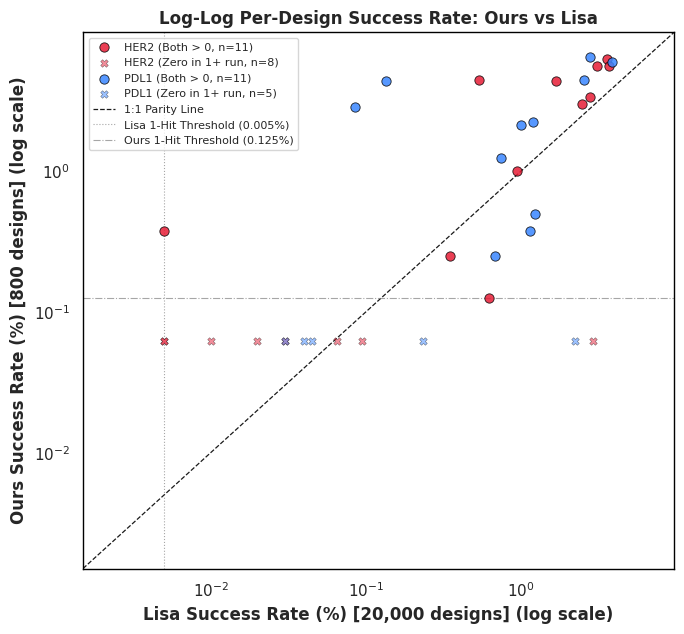

Shared Motifs: 35 | Non-Zero in Both: 22
Overall Spearman rho = 0.708
Log Pearson r (Non-zero motifs only) = 0.446


,pdb,motif_num,disjointed_parts,our_pass,our_pass_projected,lisa_pass,our_rate_pct,lisa_rate_pct
19,pdl1,49,1,48,1200.0,782,6.000,3.910
13,her2,598,1,45,1125.0,747,5.625,3.735
12,her2,596,1,50,1250.0,721,6.250,3.605
4,her2,571,1,45,1125.0,620,5.625,3.100
17,her2,606,1,0,0.0,586,0.000,2.930
18,her2,607,1,27,675.0,564,3.375,2.820
28,pdl1,71,1,52,1300.0,560,6.500,2.800
23,pdl1,61,1,36,900.0,510,4.500,2.550
16,her2,605,1,24,600.0,496,3.000,2.480
33,pdl1,121,1,0,0.0,446,0.000,2.230


In [61]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr

# ── Sampling Parameters ───────────────────────────────────────────────────────
LISA_TRAJ, LISA_SEQ_PER_TRAJ = 1000, 20
LISA_TOTAL_DESIGNS = LISA_TRAJ * LISA_SEQ_PER_TRAJ  # 20,000

OURS_TRAJ, OURS_SEQ_PER_TRAJ = 100, 8
OURS_TOTAL_DESIGNS = OURS_TRAJ * OURS_SEQ_PER_TRAJ  # 800

NORM_FACTOR = LISA_TOTAL_DESIGNS / OURS_TOTAL_DESIGNS

# Limit of detection (LOD) pseudo-rates (%) for zero-count markers
LISA_LOD_PCT = (1 / LISA_TOTAL_DESIGNS) * 100  # 0.005%
OURS_LOD_PCT = (1 / OURS_TOTAL_DESIGNS) * 100  # 0.125%

RESULTS = "/cluster/work/wicky/bekessel/results"
LISA = {
    "her2": ("1n8z_trastuzumab_motif_summary.csv", LISA_TOTAL_DESIGNS),
    "pdl1": ("3bis_atezolizumab_motif_summary.csv", LISA_TOTAL_DESIGNS),
}

_pm = (
    pool.drop_duplicates("task_name")
    .set_index("task_name")[["pdb_name", "motif_num"]]
)
_od = per_design[per_design.method == "rfdiff"].copy()
_od["pdb_name"] = _od.task_name.map(_pm.pdb_name)
_od["motif_num"] = _od.task_name.map(_pm.motif_num)

_rows = []
for pdbn, (f, total_lisa) in LISA.items():
    lp = os.path.join(RESULTS, f)
    if not os.path.exists(lp):
        print("Missing file:", lp)
        continue

    L = pd.read_csv(lp)
    L["motif_num"] = L.motif_num.astype(int)
    L["lisa_rate_pct"] = (L.n_passing_scaffolds / LISA_TOTAL_DESIGNS) * 100

    O = (
        _od[_od.pdb_name == pdbn]
        .dropna(subset=["motif_num"])
        .assign(motif_num=lambda x: x.motif_num.astype(int))
        .groupby("motif_num")
        .agg(our_pass=("designable", "sum"))
        .reset_index()
    )

    O["our_rate_pct"] = (O.our_pass / OURS_TOTAL_DESIGNS) * 100
    O["our_pass_projected"] = O.our_pass * NORM_FACTOR

    J = O.merge(
        L[
            [
                "motif_num",
                "lisa_rate_pct",
                "n_passing_scaffolds",
                "disjointed_parts",
            ]
        ],
        on="motif_num",
        how="inner",
    )
    J["pdb"] = pdbn
    _rows.append(J)

if _rows:
    J = pd.concat(_rows, ignore_index=True)

    # Calculate log-offset rates (replacing 0 with 0.5 * limit of detection)
    J["lisa_plot_rate"] = np.where(
        J["lisa_rate_pct"] > 0, J["lisa_rate_pct"], LISA_LOD_PCT * 0.5
    )
    J["our_plot_rate"] = np.where(
        J["our_rate_pct"] > 0, J["our_rate_pct"], OURS_LOD_PCT * 0.5
    )

    # ── Log-Log Scatter Plot ─────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(7, 6.5))
    colors = {"her2": "#e71d36", "pdl1": "#3a86ff"}

    # Separate non-zero points vs zero points for explicit legend handling
    nz_mask = (J.lisa_rate_pct > 0) & (J.our_rate_pct > 0)

    for pdbn, color in colors.items():
        sub_nz = J[(J.pdb == pdbn) & nz_mask]
        if len(sub_nz) > 0:
            ax.scatter(
                sub_nz.lisa_plot_rate,
                sub_nz.our_plot_rate,
                label=f"{pdbn.upper()} (Both > 0, n={len(sub_nz)})",
                color=color,
                s=45,
                edgecolor="black",
                linewidth=0.6,
                alpha=0.85,
                zorder=4,
            )

        # Plot zero-pass motifs along pseudo-axes limits with distinct markers
        sub_zero = J[(J.pdb == pdbn) & (~nz_mask)]
        if len(sub_zero) > 0:
            ax.scatter(
                sub_zero.lisa_plot_rate,
                sub_zero.our_plot_rate,
                color=color,
                s=30,
                marker="X",
                edgecolor="black",
                linewidth=0.4,
                alpha=0.5,
                zorder=3,
                label=f"{pdbn.upper()} (Zero in 1+ run, n={len(sub_zero)})",
            )

    # Set log scaling
    ax.set_xscale("log")
    ax.set_yscale("log")

    # Define common range for 1:1 parity line
    min_val = min(LISA_LOD_PCT * 0.3, OURS_LOD_PCT * 0.3)
    max_val = max(J.lisa_rate_pct.max(), J.our_rate_pct.max()) * 1.5

    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        "k--",
        linewidth=0.9,
        label="1:1 Parity Line",
        zorder=1,
    )

    # Visual threshold guides for Single-Hit Limits of Detection
    ax.axvline(
        LISA_LOD_PCT,
        color="grey",
        ls=":",
        lw=0.8,
        alpha=0.7,
        label=f"Lisa 1-Hit Threshold ({LISA_LOD_PCT:.3f}%)",
    )
    ax.axhline(
        OURS_LOD_PCT,
        color="grey",
        ls="-.",
        lw=0.8,
        alpha=0.7,
        label=f"Ours 1-Hit Threshold ({OURS_LOD_PCT:.3f}%)",
    )

    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)

    ax.set_xlabel(
        f"Lisa Success Rate (%) [{LISA_TOTAL_DESIGNS:,} designs] (log scale)",
        fontweight="bold",
    )
    ax.set_ylabel(
        f"Ours Success Rate (%) [{OURS_TOTAL_DESIGNS:,} designs] (log scale)",
        fontweight="bold",
    )
    ax.set_title(
        "Log-Log Per-Design Success Rate: Ours vs Lisa", fontweight="bold"
    )

    ax.legend(frameon=True, fontsize=8, loc="upper left")

    try:
        prettify(ax)
    except Exception:
        pass

    plt.tight_layout()
    plt.show()

    # ── Summary Statistics ────────────────────────────────────────────────────
    rho, _ = spearmanr(J.lisa_rate_pct, J.our_rate_pct)
    nz_J = J[nz_mask]
    r_log, _ = pearsonr(
        np.log10(nz_J.lisa_rate_pct), np.log10(nz_J.our_rate_pct)
    )

    print(
        f"Shared Motifs: {len(J)} | Non-Zero in Both: {len(nz_J)}\n"
        f"Overall Spearman rho = {rho:.3f}\n"
        f"Log Pearson r (Non-zero motifs only) = {r_log:.3f}"
    )

    display(
        J[
            [
                "pdb",
                "motif_num",
                "disjointed_parts",
                "our_pass",
                "our_pass_projected",
                "n_passing_scaffolds",
                "our_rate_pct",
                "lisa_rate_pct",
            ]
        ]
        .rename(columns={"n_passing_scaffolds": "lisa_pass"})
        .sort_values("lisa_rate_pct", ascending=False)
        .round(4)
        .head(20)
    )
else:
    print("No matching files found under", RESULTS)

## 19 · Retrieve scaffolds + refolds for inspection
Extract the generated scaffold + AF3 refold structures for chosen designs/motifs into `<run>/<method>/<out>/` (e.g. the uidx rescues).

In [ ]:
# ── §19 · Retrieve scaffolds + refolds for inspection (PyMOL/ChimeraX) ──────────────────────────
# Pull the generated scaffold PDB + AF3 refold CIF for chosen designs/motifs into
# <PICK_RUN>/<PICK_METHOD>/<PICK_OUT>/ . Open <design>_scaffold.pdb + <pred>_model.cif together.
# For the uidx rescues: PICK_TASKS=','.join(list(resc.index[:6])) (from §16), PICK_METHOD='laproteina', PICK_RUN=RUN_UIDX.
import subprocess as _sp
EXTRACT='/cluster/work/wicky/bekessel/scripts/extract_structures.py'
PICK_METHOD = 'laproteina'                  # rfdiff | proteina | genie3 | pp1c_bb | laproteina
PICK_RUN    = RUN_UIDX                       # run dir holding <method>/ outputs (RUN, RUN_UIDX, or any path)
PICK_TASKS  = 'her2_m591_base,il2_m65_base'  # comma-sep motifs; or set PICK_DESIGNS to exact design_names
PICK_DESIGNS= ''                             # e.g. 'her2_m591_base_12,her2_m591_base_40' (overrides PICK_TASKS)
PICK_PER_TASK, PICK_SEQS, PICK_OUT = 2, 1, 'picked_structures'
_cmd = ['python', EXTRACT, '--run-dir', PICK_RUN, '--method', PICK_METHOD, '--out', PICK_OUT, '--seqs-per-design', str(PICK_SEQS)]
_cmd += (['--designs', PICK_DESIGNS] if PICK_DESIGNS else ['--tasks', PICK_TASKS, '--per-task', str(PICK_PER_TASK)])
print('running:', ' '.join(_cmd))
_r = _sp.run(_cmd, capture_output=True, text=True); print(_r.stdout or _r.stderr)
print(f'-> {PICK_RUN}/{PICK_METHOD}/{PICK_OUT}/')


## 20 · Select & retrieve structures by method / motif / designability
Filter an `af3_refold_scores.csv` (any run/method) by motif and designable-vs-not, list the matching prediction/design names, and extract their scaffold + refold into `<run>/<method>/<out>/`.

In [ ]:
# ── §20 · Select predictions (method / motif / designable) and retrieve their structures ─────────
import subprocess as _sp
EXTRACT='/cluster/work/wicky/bekessel/scripts/extract_structures.py'
SEL_RUN       = RUN_UIDX                 # run dir holding <method>/ outputs (RUN, RUN_UIDX, or any path)
SEL_METHOD    = 'laproteina'             # method subdir (rfdiff|proteina|genie3|pp1c_bb|laproteina)
# (uidx La-Proteina's plain af3_refold_scores.csv already IS the greedy-relocalized score, so no suffix needed)
SEL_MOTIF     = None                     # task_name substring to filter, e.g. 'her2_m591_base' ; None = all motifs
SEL_DESIGNABLE= True                     # True = only designable | False = only NON-designable | None = both
SEL_N         = 4                        # how many predictions to list / retrieve
SEL_OUT       = 'selected_structures'    # -> <run>/<method>/<out>/
SEL_RETRIEVE  = True                     # False = just list (no extraction)

_csv = f"{SEL_RUN}/{SEL_METHOD}/af3_refold_scores.csv"
if not os.path.exists(_csv):
    print('MISSING', _csv, '- score it first')
else:
    _s = pd.read_csv(_csv); _s.columns=[c.strip() for c in _s.columns]
    _s['task_name'] = _s.design_name.map(to_task)
    _s['pass3'] = ((_s.motifRMSD<=MOTIF_RMSD_MAX)&(_s.scRMSD<=SC_RMSD_MAX)&(_s.ranking_score>=RANK_MIN)).astype(int)
    # per-design: designable iff ANY seq passes; keep the best metrics for ranking/inspection
    g = (_s.groupby(['design_name','task_name'])
           .agg(designable=('pass3','max'), best_motifRMSD=('motifRMSD','min'),
                best_scRMSD=('scRMSD','min'), max_rank=('ranking_score','max'), n_seq=('pass3','size'))
           .reset_index())
    f = g
    if SEL_MOTIF: f = f[f.task_name.str.contains(SEL_MOTIF, na=False)]
    if SEL_DESIGNABLE is not None: f = f[f.designable == int(SEL_DESIGNABLE)]
    f = f.sort_values('best_motifRMSD')
    print(f"{len(f)} designs match  (method={SEL_METHOD}, motif={SEL_MOTIF}, designable={SEL_DESIGNABLE}) — top {SEL_N}:")
    display(f.head(SEL_N).round(3))
    if SEL_RETRIEVE and len(f):
        designs = ','.join(f.head(SEL_N).design_name.tolist())
        cmd = ['python',EXTRACT,'--run-dir',SEL_RUN,'--method',SEL_METHOD,'--designs',designs,
               '--out',SEL_OUT,'--seqs-per-design','1']
        print('\nretrieving ->', f"{SEL_RUN}/{SEL_METHOD}/{SEL_OUT}/")
        r = _sp.run(cmd, capture_output=True, text=True); print(r.stdout or r.stderr)


In [48]:
laproteina = per_design[per_design.method == "laproteina"]
laproteina_mpnn = per_design[per_design.method == "laproteina_mpnn"]

In [55]:
rescued = set(laproteina_mpnn[laproteina_mpnn.designable == 1].task_name) - set(laproteina[laproteina.designable == 1].task_name) 

   LA-PROTEINA NATIVE vs. MPNN REDESIGN MOTIF RESCUE    
  • Total Motifs Evaluated : 314
  • Both Pass              : 185
  • Rescued by MPNN        : 24  <-- (Target set)
  • Native Only            : 2
  • Failed Both            : 103

>>> MPNN RESCUED MOTIFS (24 total):
       task_name pdb_name variant dominant_sse  disjointed_parts  motif_length
  her2_m244_base     her2    base            C                 2             5
  her2_m248_base     her2    base            C                 2             7
  her2_m290_base     her2    base            E                 2             8
  her2_m555_base     her2    base            E                 3             6
  her2_m564_base     her2    base            C                 2             7
her2_m274_filled     her2  filled            C                 1            12
her2_m290_filled     her2  filled            C                 1            12
her2_m568_filled     her2  filled            C                 2            21
    il13_m5_bas

/scratch/tmp.11378206.bekessel/ipykernel_139821/3261990998.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/scratch/tmp.11378206.bekessel/ipykernel_139821/3261990998.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


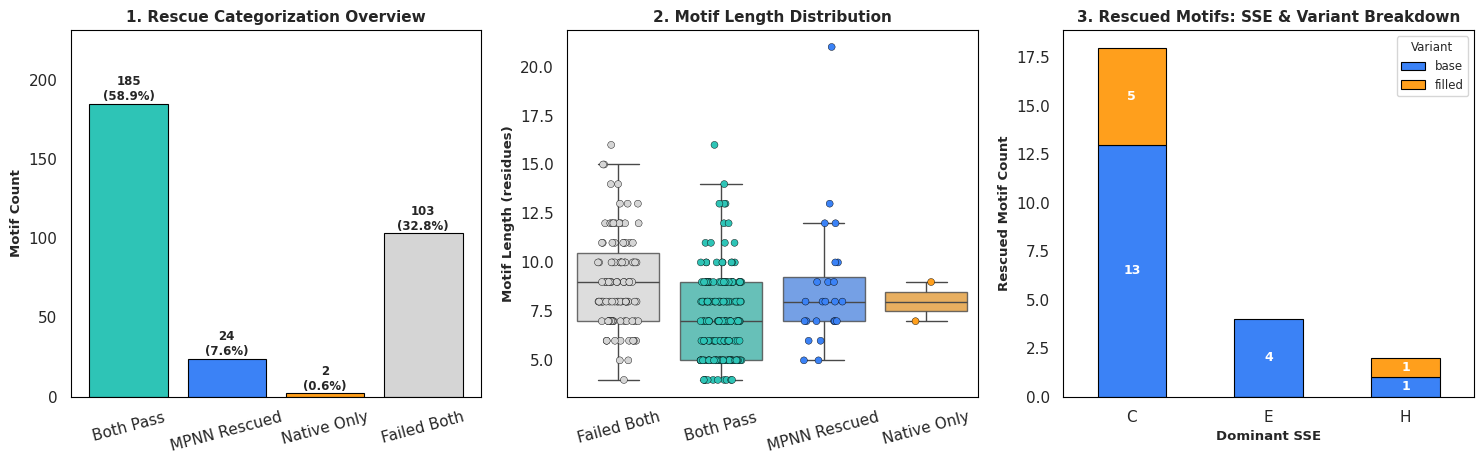

In [67]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ── 1. Calculate Motif Rescue Sets ─────────────────────────────────────────────
native_pass = set(
    per_design[
        (per_design.method == "laproteina") & (per_design.designable == 1)
    ].task_name
)
mpnn_pass = set(
    per_design[
        (per_design.method == "laproteina_mpnn") & (per_design.designable == 1)
    ].task_name
)
all_motifs = set(per_design.task_name.unique())

both_pass = native_pass & mpnn_pass
rescued = mpnn_pass - native_pass  # Rescued by MPNN redesign
native_only = native_pass - mpnn_pass
failed_both = all_motifs - (native_pass | mpnn_pass)

# Map category to metadata pool
category_map = {
    **{t: "Both Pass" for t in both_pass},
    **{t: "MPNN Rescued" for t in rescued},
    **{t: "Native Only" for t in native_only},
    **{t: "Failed Both" for t in failed_both},
}

pool_rescued = pool.copy() if "pool" in globals() else per_design.drop_duplicates("task_name").copy()
pool_rescued["rescue_status"] = pool_rescued["task_name"].map(category_map)

# Extract detailed DataFrame of MPNN Rescued motifs
rescued_df = pool_rescued[pool_rescued["rescue_status"] == "MPNN Rescued"].copy()

print(f"=========================================================")
print(f"   LA-PROTEINA NATIVE vs. MPNN REDESIGN MOTIF RESCUE    ")
print(f"=========================================================")
print(f"  • Total Motifs Evaluated : {len(all_motifs)}")
print(f"  • Both Pass              : {len(both_pass)}")
print(f"  • Rescued by MPNN        : {len(rescued)}  <-- (Target set)")
print(f"  • Native Only            : {len(native_only)}")
print(f"  • Failed Both            : {len(failed_both)}")
print(f"=========================================================\n")

# Display features of the rescued motifs
feat_cols = [c for c in ["task_name", "pdb_name", "variant", "dominant_sse", "disjointed_parts", "motif_length"] if c in rescued_df.columns]
print(f">>> MPNN RESCUED MOTIFS ({len(rescued_df)} total):")
print(rescued_df[feat_cols].to_string(index=False))


# ── 2. Render 3-Panel Rescue Feature Diagnostic Plot ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

C_BOTH = "#2ec4b6"  # Teal
C_RESCUE = "#3b82f6"  # Blue
C_NAT = "#ff9f1c"  # Orange
C_FAIL = "#d5d5d5"  # Gray

palette = {
    "Both Pass": C_BOTH,
    "MPNN Rescued": C_RESCUE,
    "Native Only": C_NAT,
    "Failed Both": C_FAIL,
}

# ── Panel 1: Absolute Counts Summary ──────────────────────────────────────────
ax1 = axes[0]
counts = pool_rescued["rescue_status"].value_counts()[
    ["Both Pass", "MPNN Rescued", "Native Only", "Failed Both"]
]
bars = ax1.bar(
    counts.index,
    counts.values,
    color=[palette[k] for k in counts.index],
    edgecolor="black",
    linewidth=0.8,
)

for bar in bars:
    y = bar.get_height()
    pct = (y / len(all_motifs)) * 100
    ax1.text(
        bar.get_x() + bar.get_width() / 2.0,
        y + 0.5,
        f"{y}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
    )

ax1.set_ylabel("Motif Count", fontsize=9.5, fontweight="bold")
ax1.set_title("1. Rescue Categorization Overview", fontsize=11, fontweight="bold")
ax1.set_ylim(0, max(counts.values) * 1.25)
ax1.tick_params(axis="x", rotation=15)

# ── Panel 2: Geometry Burden (Motif Length vs. Disjointed Parts) ──────────────
ax2 = axes[1]
sns.boxplot(
    data=pool_rescued,
    x="rescue_status",
    y="motif_length",
    palette=palette,
    ax=ax2,
    showfliers=False,
    boxprops=dict(alpha=0.8),
)
sns.stripplot(
    data=pool_rescued,
    x="rescue_status",
    y="motif_length",
    palette=palette,
    jitter=0.2,
    s=5,
    edgecolor="black",
    linewidth=0.3,
    ax=ax2,
)

ax2.set_xlabel("")
ax2.set_ylabel("Motif Length (residues)", fontsize=9.5, fontweight="bold")
ax2.set_title("2. Motif Length Distribution", fontsize=11, fontweight="bold")
ax2.tick_params(axis="x", rotation=15)

# ── Panel 3: Structural Breakdown of Rescued Motifs ──────────────────────────
ax3 = axes[2]
if "variant" in rescued_df.columns and "dominant_sse" in rescued_df.columns:
    var_sse = (
        rescued_df.groupby(["dominant_sse", "variant"]).size().unstack(fill_value=0)
    )
    var_sse.plot(
        kind="bar",
        stacked=True,
        ax=ax3,
        color=["#3b82f6", "#ff9f1c"],
        edgecolor="black",
        linewidth=0.8,
    )

    for container in ax3.containers:
        for patch in container:
            val = patch.get_height()
            if val > 0:
                ax3.text(
                    patch.get_x() + patch.get_width() / 2.0,
                    patch.get_y() + val / 2.0,
                    f"{int(val)}",
                    ha="center",
                    va="center",
                    fontsize=9,
                    fontweight="bold",
                    color="white",
                )

    ax3.set_xlabel("Dominant SSE", fontsize=9.5, fontweight="bold")
    ax3.set_ylabel("Rescued Motif Count", fontsize=9.5, fontweight="bold")
    ax3.set_title(
        "3. Rescued Motifs: SSE & Variant Breakdown",
        fontsize=11,
        fontweight="bold",
    )
    ax3.tick_params(axis="x", rotation=0)
    ax3.legend(title="Variant", fontsize=8.5, title_fontsize=8.5)

# Clean Spines
for ax in axes:
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor("black")
        spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()

In [64]:
passing_counts

task_name
her2_m239_base      303
her2_m240_base        1
her2_m243_base        1
her2_m243_filled      2
her2_m244_base        2
                   ... 
tnfa_m23_base        80
tnfa_m27_base         4
tnfa_m27_filled       9
tnfa_m67_base        47
tnfa_m71_base         1
Name: n_passing, Length: 246, dtype: int64

/scratch/tmp.11378206.bekessel/ipykernel_139821/2678224423.py:209: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


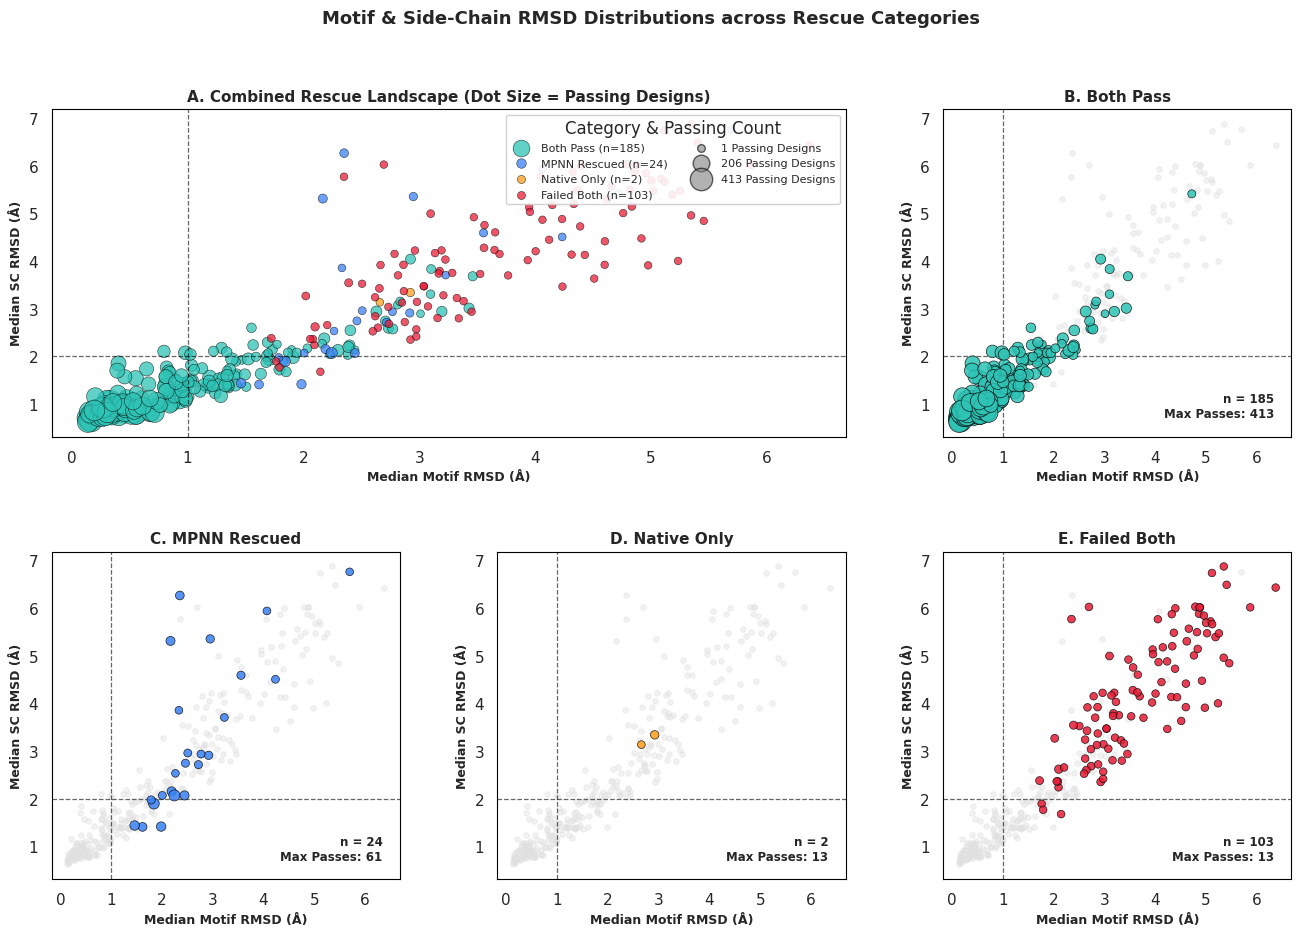

In [65]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ── 1. Calculate Median RMSDs and Passing Design Counts per Task ──────────────
# Detect column names flexible to naming variations
m_col = "motifRMSD" if "motifRMSD" in per_design.columns else "motif_rmsd"
s_col = (
    "scRMSD"
    if "scRMSD" in per_design.columns
    else ("sc_rmsd" if "sc_rmsd" in per_design.columns else "backbone_rmsd")
)

# Compute median RMSDs per task_name from per_design
rmsd_summary = (
    per_design.groupby("task_name")
    .agg(motifRMSD_med=(m_col, "median"), scRMSD_med=(s_col, "median"))
    .reset_index()
)

# Count passing/designable predictions per task
passing_counts = (
    per_design[per_design.designable == 1]
    .groupby("task_name")
    .size()
    .rename("n_passing")
)

# ── 2. Determine Rescue Category Mapping ──────────────────────────────────────
native_pass = set(
    per_design[
        (per_design.method == "laproteina") & (per_design.designable == 1)
    ].task_name
)
mpnn_pass = set(
    per_design[
        (per_design.method == "laproteina_mpnn") & (per_design.designable == 1)
    ].task_name
)
all_motifs = set(per_design.task_name.unique())

both_pass = native_pass & mpnn_pass
rescued = mpnn_pass - native_pass  # MPNN Rescued
native_only = native_pass - mpnn_pass
failed_both = all_motifs - (native_pass | mpnn_pass)

category_map = {
    **{t: "Both Pass" for t in both_pass},
    **{t: "MPNN Rescued" for t in rescued},
    **{t: "Native Only" for t in native_only},
    **{t: "Failed Both" for t in failed_both},
}

# ── 3. Prepare Diagnostic Dataframe (df_plot) ──────────────────────────────────
# Base dataframe from pool or unique tasks in per_design
if "pool" in globals():
    df_plot = pool.drop(
        columns=["motifRMSD_med", "scRMSD_med"], errors="ignore"
    ).copy()
else:
    df_plot = per_design.drop_duplicates("task_name")[["task_name"]].copy()

# Merge computed medians and passing counts
df_plot = df_plot.merge(rmsd_summary, on="task_name", how="left")
df_plot = df_plot.merge(passing_counts, on="task_name", how="left")

df_plot["rescue_status"] = df_plot["task_name"].map(category_map)
df_plot["n_passing"] = df_plot["n_passing"].fillna(0).astype(int)

# Scale dot sizes according to number of passing designs
min_size, max_size = 30, 260
max_pass = max(df_plot["n_passing"].max(), 1)
df_plot["dot_size"] = min_size + (df_plot["n_passing"] / max_pass) * (
    max_size - min_size
)

# Palette
palette = {
    "Both Pass": "#2ec4b6",  # Teal
    "MPNN Rescued": "#3b82f6",  # Blue
    "Native Only": "#ff9f1c",  # Orange
    "Failed Both": "#e71d36",  # Red
}

# ── 4. Render 5-Panel Diagnostic Figure ────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.28)

ax_main = fig.add_subplot(gs[0, :2])  # Combined Plot
ax_both = fig.add_subplot(gs[0, 2])  # Both Pass
ax_resc = fig.add_subplot(gs[1, 0])  # MPNN Rescued
ax_nat = fig.add_subplot(gs[1, 1])  # Native Only
ax_fail = fig.add_subplot(gs[1, 2])  # Failed Both

gate_m, gate_s = 1.0, 2.0


def setup_gate_axes(ax, title):
    """Draw quality gates and standard labels."""
    ax.axvline(gate_m, ls="--", color="black", lw=0.9, alpha=0.6)
    ax.axhline(gate_s, ls="--", color="black", lw=0.9, alpha=0.6)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Median Motif RMSD (Å)", fontsize=9, fontweight="bold")
    ax.set_ylabel("Median SC RMSD (Å)", fontsize=9, fontweight="bold")


# Panel A: Combined Scatter
setup_gate_axes(
    ax_main, "A. Combined Rescue Landscape (Dot Size = Passing Designs)"
)

for status, color in palette.items():
    sub = df_plot[df_plot["rescue_status"] == status]
    ax_main.scatter(
        sub["motifRMSD_med"],
        sub["scRMSD_med"],
        s=sub["dot_size"],
        color=color,
        alpha=0.75,
        edgecolor="black",
        linewidth=0.4,
        label=f"{status} (n={len(sub)})",
    )

# Panels B-E: Individual Category Breakdowns
cat_axes = [
    (ax_both, "Both Pass", "B. Both Pass"),
    (ax_resc, "MPNN Rescued", "C. MPNN Rescued"),
    (ax_nat, "Native Only", "D. Native Only"),
    (ax_fail, "Failed Both", "E. Failed Both"),
]

for ax, cat_name, title in cat_axes:
    setup_gate_axes(ax, title)

    # Grey background of all tasks for context
    ax.scatter(
        df_plot["motifRMSD_med"],
        df_plot["scRMSD_med"],
        c="#e0e0e0",
        s=15,
        alpha=0.4,
        zorder=1,
    )

    # Category points scaled by n_passing
    sub = df_plot[df_plot["rescue_status"] == cat_name]
    ax.scatter(
        sub["motifRMSD_med"],
        sub["scRMSD_med"],
        s=sub["dot_size"],
        color=palette[cat_name],
        alpha=0.85,
        edgecolor="black",
        linewidth=0.5,
        zorder=2,
    )

    ax.text(
        0.95,
        0.05,
        f"n = {len(sub)}\nMax Passes: {sub['n_passing'].max()}",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, lw=0.5
        ),
    )

# Legend & Formatting
sizes_to_show = [1, max(1, int(max_pass / 2)), max_pass]
for s in sizes_to_show:
    scaled_s = min_size + (s / max_pass) * (max_size - min_size)
    ax_main.scatter(
        [],
        [],
        c="gray",
        alpha=0.6,
        s=scaled_s,
        edgecolor="black",
        label=f"{s} Passing Designs",
    )

ax_main.legend(
    loc="upper right",
    fontsize=8,
    framealpha=0.9,
    ncol=2,
    title="Category & Passing Count",
)

for ax in [ax_main, ax_both, ax_resc, ax_nat, ax_fail]:
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor("black")
        spine.set_linewidth(0.8)

plt.suptitle(
    "Motif & Side-Chain RMSD Distributions across Rescue Categories",
    fontsize=13,
    fontweight="bold",
    y=0.98,
)
plt.tight_layout()
plt.show()

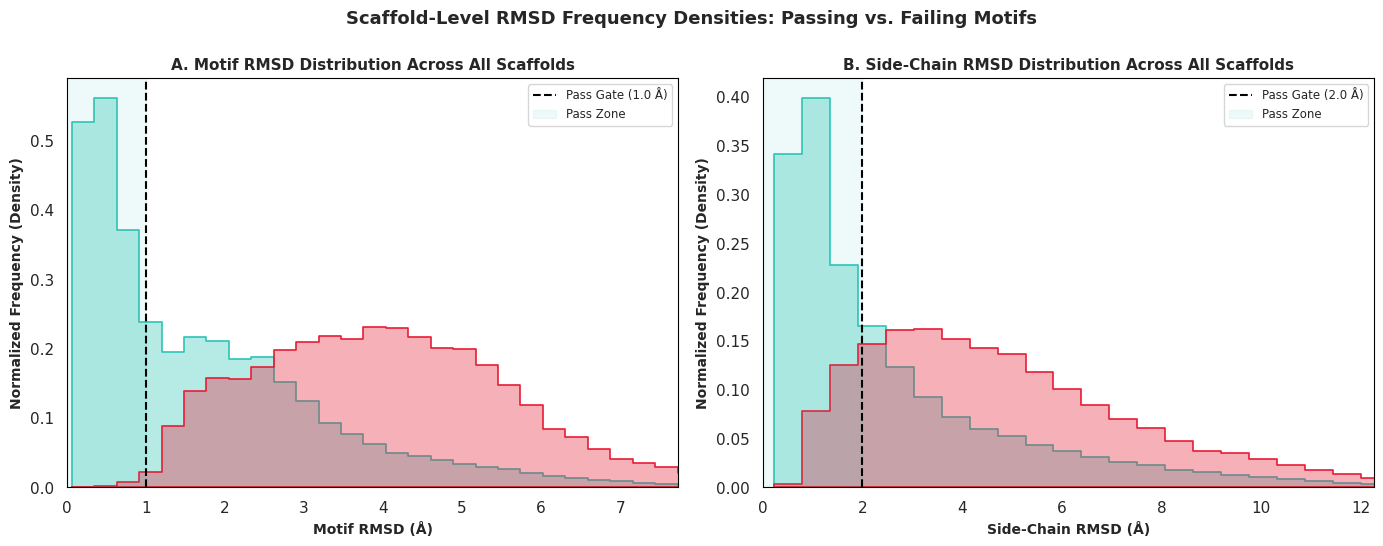

In [59]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ── 1. Map Task-Level Status across All Individual Scaffolds ──────────────────
# Identify tasks with AT LEAST ONE passing scaffold (designable == 1)
passing_tasks = set(per_design[per_design["designable"] == 1]["task_name"])

df_dist = per_design.copy()
df_dist["motif_status"] = np.where(
    df_dist["task_name"].isin(passing_tasks),
    "Passing Motifs (≥1 Designable)",
    "Failing Motifs (0 Designable)",
)

# ── 2. Create Dual-Panel Distribution Plot ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

palette = {
    "Passing Motifs (≥1 Designable)": "#2ec4b6",  # Teal
    "Failing Motifs (0 Designable)": "#e71d36",  # Red
}

# ── PANEL A: Motif RMSD Frequency Distribution ────────────────────────────────
ax_a = axes[0]
sns.histplot(
    data=df_dist,
    x="motifRMSD",
    hue="motif_status",
    palette=palette,
    element="step",
    stat="density",  # Normalized frequency density
    common_norm=False,
    bins=60,
    alpha=0.35,
    ax=ax_a,
    linewidth=1.2,
)
ax_a.axvline(
    1.0,
    ls="--",
    color="black",
    lw=1.5,
    label="Pass Gate (1.0 Å)",
)

# Highlight the passing zone
ax_a.axvspan(0, 1.0, color="#2ec4b6", alpha=0.08, label="Pass Zone")

ax_a.set_title(
    "A. Motif RMSD Distribution Across All Scaffolds",
    fontsize=11,
    fontweight="bold",
)
ax_a.set_xlabel("Motif RMSD (Å)", fontsize=10, fontweight="bold")
ax_a.set_ylabel(
    "Normalized Frequency (Density)", fontsize=10, fontweight="bold"
)
ax_a.set_xlim(0, df_dist["motifRMSD"].quantile(0.99))
ax_a.legend(fontsize=8.5, loc="upper right")

# ── PANEL B: Side-Chain RMSD Frequency Distribution ────────────────────────────
ax_b = axes[1]
sns.histplot(
    data=df_dist,
    x="scRMSD",
    hue="motif_status",
    palette=palette,
    element="step",
    stat="density",  # Normalized frequency density
    common_norm=False,
    bins=60,
    alpha=0.35,
    ax=ax_b,
    linewidth=1.2,
)
ax_b.axvline(
    2.0,
    ls="--",
    color="black",
    lw=1.5,
    label="Pass Gate (2.0 Å)",
)

# Highlight the passing zone
ax_b.axvspan(0, 2.0, color="#2ec4b6", alpha=0.08, label="Pass Zone")

ax_b.set_title(
    "B. Side-Chain RMSD Distribution Across All Scaffolds",
    fontsize=11,
    fontweight="bold",
)
ax_b.set_xlabel("Side-Chain RMSD (Å)", fontsize=10, fontweight="bold")
ax_b.set_ylabel(
    "Normalized Frequency (Density)", fontsize=10, fontweight="bold"
)
ax_b.set_xlim(0, df_dist["scRMSD"].quantile(0.99))
ax_b.legend(fontsize=8.5, loc="upper right")

# Clean Spines & Grid
for ax in axes:
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor("black")
        spine.set_linewidth(0.8)

plt.suptitle(
    "Scaffold-Level RMSD Frequency Densities: Passing vs. Failing Motifs",
    fontsize=13,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout()
plt.show()

## 15 - Motifs that failed ALL methods

Motifs with **zero successful scaffolds in every method** (the intrinsically hard set). Lists their features
+ median RMSDs (motif-placement vs self-consistency), and contrasts them against the rest of the library.


22 / 314 motifs failed ALL 7 methods: ['rfdiff', 'proteina', 'genie3', 'pp1c_bb', 'laproteina', 'laproteina_mpnn', 'laproteina_unindexed']


,task_name,pdb_name,motif_num,variant,dominant_sse,disjointed_parts,motif_length,motif_residues,motifRMSD_med,scRMSD_med,plddt_med
6,her2_m584_base,her2,584,base,C,1,7,582 583 584 585 586 587 588,2.369817,3.467755,85.062955
16,her2_m583_filled,her2,583,filled,C,1,8,581 582 583 584 585 586 587 588,2.334597,3.375558,83.110107
17,her2_m588_filled,her2,588,filled,C,1,9,582 583 584 585 586 587 588 589 590,3.207298,4.699826,79.711660
15,her2_m582_filled,her2,582,filled,C,1,12,580 581 582 583 584 585 586 587 588 589 590 591,6.479475,8.004057,74.023568
18,her2_m589_filled,her2,589,filled,C,1,12,580 581 582 583 584 585 586 587 588 589 590 591,6.474814,7.927454,74.358012
7,her2_m588_base,her2,588,base,C,2,8,582 583 584 586 587 588 589 590,3.177036,4.283421,77.306428
21,tnfa_m70_filled,tnfa,70,filled,C,2,8,68 69 70 71 72 103 104 105,3.549642,5.042042,78.882210
5,her2_m582_base,her2,582,base,C,2,9,580 581 582 583 584 588 589 590 591,3.725644,6.097882,74.955727
14,her2_m580_filled,her2,580,filled,C,2,10,578 579 580 581 582 589 590 591 592 593,4.373321,5.185653,77.054857
20,tnfa_m106_base,tnfa,106,base,C,2,10,68 69 104 105 106 107 108 109 110 111,3.636933,4.362606,79.387999



--- failed-all vs scaffoldable: disjointedness / length ---


disjointed_parts            motif_length           
                        mean median max         mean median max
_failed_all                                                    
False                   1.78    2.0   5         7.75    8.0  21
True                    2.36    2.0   4        10.59   10.0  16

--- dominant SSE fraction ---


dominant_sse,C,E,H
_failed_all,,,
False,0.57,0.28,0.15
True,0.77,0.23,NaN


/scratch/tmp.11804183.bekessel/ipykernel_898589/1224501756.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  try: ax.set_xticklabels(['scaffoldable','failed-all'])
/scratch/tmp.11804183.bekessel/ipykernel_898589/1224501756.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  try: ax.set_xticklabels(['scaffoldable','failed-all'])


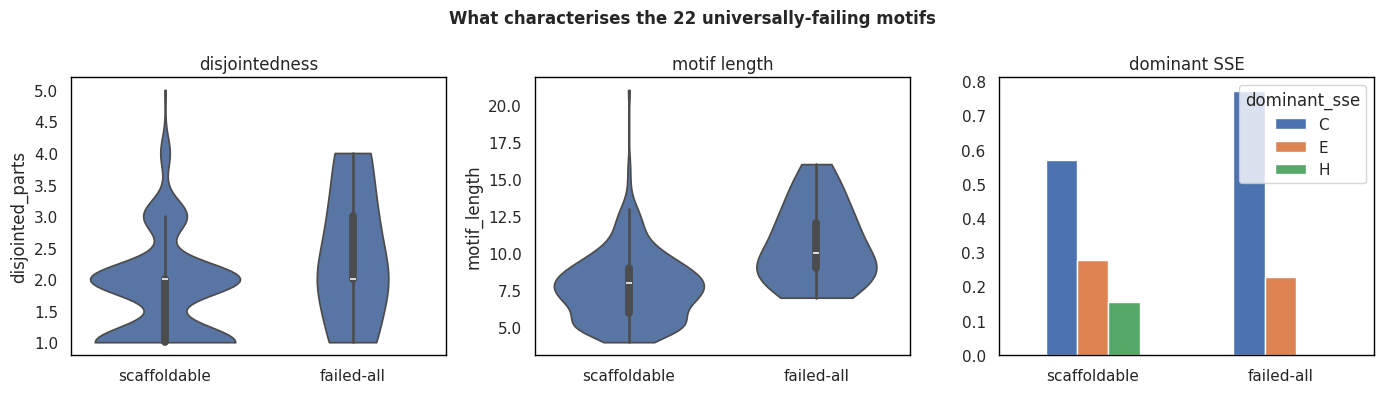

In [55]:
# motifs with 0 successful scaffolds across EVERY method present
piv = msucc.pivot_table(index='task_name', columns='method', values='n_pass', fill_value=0)
mpres = [m for m in METHODS if m in piv.columns]
failed_all = piv.index[(piv[mpres] == 0).all(axis=1)]
print(f'{len(failed_all)} / {len(piv)} motifs failed ALL {len(mpres)} methods: {mpres}')

# features (from the pool) + median RMSDs (WHY they fail: high motifRMSD = misplaced; high scRMSD = not self-consistent)
fcols = [c for c in ['pdb_name','motif_num','variant','dominant_sse','disjointed_parts','motif_length','motif_residues']
         if c in pool.columns]
feat = pool[pool.task_name.isin(failed_all)][['task_name']+fcols].drop_duplicates('task_name').reset_index(drop=True)
rmsd = (scores[scores.task_name.isin(failed_all)].groupby('task_name')
        .agg(motifRMSD_med=('motifRMSD','median'), scRMSD_med=('scRMSD','median'),
             plddt_med=('plddt_mean','median')).reset_index())
failed_tbl = feat.merge(rmsd, on='task_name', how='left').sort_values(['disjointed_parts','motif_length'])
display(failed_tbl)

# what characterises them vs the rest of the library
pool['_failed_all'] = pool.task_name.isin(failed_all)
print('\n--- failed-all vs scaffoldable: disjointedness / length ---')
display(pool.groupby('_failed_all')[['disjointed_parts','motif_length']].agg(['mean','median','max']).round(2))
print('--- dominant SSE fraction ---')
display(pool.groupby('_failed_all').dominant_sse.value_counts(normalize=True).unstack().round(2))

fig, axes = plt.subplots(1, 3, figsize=(14,4))
sns.violinplot(data=pool, x='_failed_all', y='disjointed_parts', cut=0, ax=axes[0]); axes[0].set_title('disjointedness')
sns.violinplot(data=pool, x='_failed_all', y='motif_length', cut=0, ax=axes[1]); axes[1].set_title('motif length')
pool.groupby('_failed_all').dominant_sse.value_counts(normalize=True).unstack().plot(kind='bar', ax=axes[2])
axes[2].set_title('dominant SSE'); axes[2].tick_params(axis='x', rotation=0)
for ax in axes:
    ax.set_xlabel('')
    try: ax.set_xticklabels(['scaffoldable','failed-all'])
    except Exception: pass
    prettify(ax)
fig.suptitle(f'What characterises the {len(failed_all)} universally-failing motifs', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()


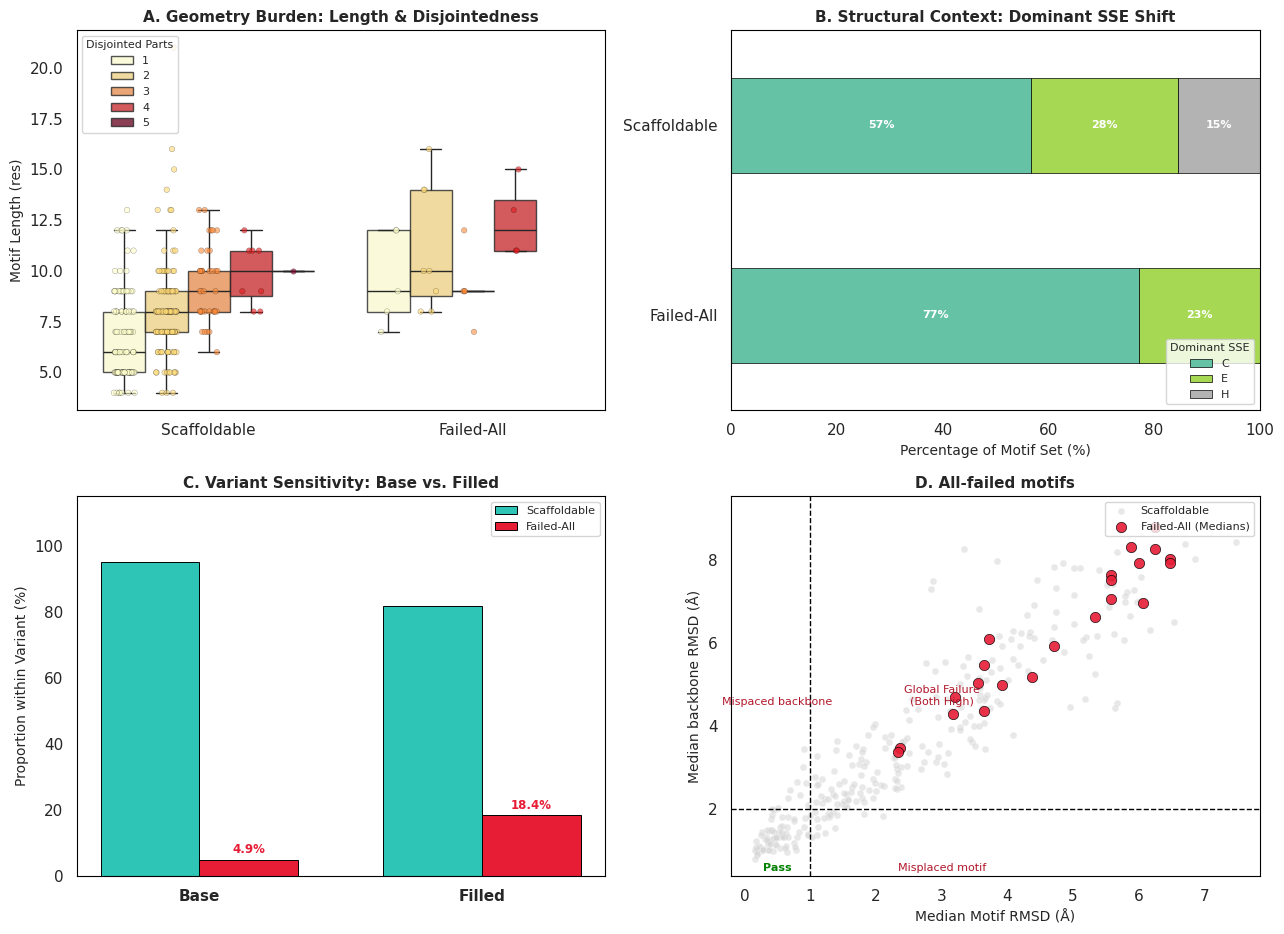

In [56]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ── 1. Prepare Diagnostic Dataframe ───────────────────────────────────────────
# Classify failure status
pool["status"] = np.where(pool["task_name"].isin(failed_all), "Failed-All", "Scaffoldable")

# Merge median RMSD scores into pool for failure mode analysis
rmsd_summary = scores.groupby("task_name").agg(
    motifRMSD_med=("motifRMSD", "median"),
    scRMSD_med=("scRMSD", "median")
).reset_index()

pool_diag = pool.merge(rmsd_summary, on="task_name", how="left")

# ── 2. Palette and Figure Setup ───────────────────────────────────────────────
C_PASS = "#2ec4b6"   # Teal
C_FAIL = "#e71d36"   # Red / Failed-All
C_BASE = "#3b82f6"   # Blue
C_FILL = "#ff9f1c"   # Orange

fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
plt.subplots_adjust(wspace=0.3, hspace=0.35)

# ── PANEL A: Disjointed Parts vs Motif Length (Jittered Boxplot) ─────────────
ax_a = axes[0, 0]
sns.boxplot(
    data=pool_diag, x="status", y="motif_length", hue="disjointed_parts",
    palette="YlOrRd", ax=ax_a, boxprops=dict(alpha=0.8), showfliers=False
)
sns.stripplot(
    data=pool_diag, x="status", y="motif_length", hue="disjointed_parts",
    palette="YlOrRd", dodge=True, jitter=0.2, alpha=0.6, s=4, edgecolor="black", linewidth=0.2,
    ax=ax_a, legend=False
)

ax_a.set_title("A. Geometry Burden: Length & Disjointedness", fontsize=11, fontweight="bold")
ax_a.set_xlabel("")
ax_a.set_ylabel("Motif Length (res)", fontsize=10)
ax_a.legend(title="Disjointed Parts", fontsize=8, title_fontsize=8, loc="upper left")

# ── PANEL B: Secondary Structure Breakdown (Dominant SSE Shift) ──────────────
ax_b = axes[0, 1]
sse_counts = pool_diag.groupby(["status", "dominant_sse"]).size().unstack(fill_value=0)
sse_pcts = sse_counts.div(sse_counts.sum(axis=1), axis=0) * 100

sse_pcts.plot(
    kind="barh", stacked=True, colormap="Set2", ax=ax_b, edgecolor="black", linewidth=0.5
)

# Annotate percentage labels inside bars
for container in ax_b.containers:
    for patch in container:
        width = patch.get_width()
        if width > 8: # Only label visible segments
            x = patch.get_x() + width / 2
            y = patch.get_y() + patch.get_height() / 2
            ax_b.text(x, y, f"{width:.0f}%", ha="center", va="center", fontsize=8, fontweight="bold", color="white")

ax_b.set_title("B. Structural Context: Dominant SSE Shift", fontsize=11, fontweight="bold")
ax_b.set_xlabel("Percentage of Motif Set (%)", fontsize=10)
ax_b.set_ylabel("")
ax_b.legend(title="Dominant SSE", fontsize=8, title_fontsize=8, loc="lower right")

# ── PANEL C: Base vs Filled Variant Failure Vulnerability ────────────────────
ax_c = axes[1, 0]

if "variant" in pool_diag.columns:
    var_fail = pool_diag.groupby("variant")["status"].value_counts(normalize=True).unstack().fillna(0) * 100
    
    x = np.arange(len(var_fail))
    w = 0.35
    
    b1 = ax_c.bar(x - w/2, var_fail.get("Scaffoldable", 0), w, label="Scaffoldable", color=C_PASS, edgecolor="black", linewidth=0.7)
    b2 = ax_c.bar(x + w/2, var_fail.get("Failed-All", 0), w, label="Failed-All", color=C_FAIL, edgecolor="black", linewidth=0.7)
    
    for bar in b2:
        h = bar.get_height()
        if h > 0:
            ax_c.text(bar.get_x() + bar.get_width()/2., h + 1, f"{h:.1f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=C_FAIL)
            
    ax_c.set_xticks(x)
    ax_c.set_xticklabels([str(v).capitalize() for v in var_fail.index], fontweight="bold")
    ax_c.set_ylabel("Proportion within Variant (%)", fontsize=10)
    ax_c.set_title("C. Variant Sensitivity: Base vs. Filled", fontsize=11, fontweight="bold")
    ax_c.legend(fontsize=8, loc="upper right")
    ax_c.set_ylim(0, 115)
else:
    ax_c.text(0.5, 0.5, "Column 'variant' not found in dataframe", ha="center", va="center")

# ── PANEL D: Failure Mode Diagnosis (Motif RMSD vs SC RMSD) ───────────────────
ax_d = axes[1, 1]

# Plot passing scaffolds in gray background
sns.scatterplot(
    data=pool_diag[pool_diag["status"] == "Scaffoldable"],
    x="motifRMSD_med", y="scRMSD_med", color="#d3d3d3", alpha=0.5, s=25, label="Scaffoldable", ax=ax_d
)

# Overlay universally failing motifs in prominent color
sns.scatterplot(
    data=pool_diag[pool_diag["status"] == "Failed-All"],
    x="motifRMSD_med", y="scRMSD_med", color=C_FAIL, alpha=0.9, s=55, edgecolor="black", linewidth=0.5,
    label="Failed-All (Medians)", ax=ax_d
)

# Draw Quality Gate Lines
ax_d.axvline(1.0, ls="--", color="black", lw=1.0)
ax_d.axhline(2.0, ls="--", color="black", lw=1.0)

# Label Failure Quadrants
ax_d.text(0.5, 0.5, "Pass", fontsize=8, color="green", fontweight="bold", ha="center")
ax_d.text(3.0, 0.5, "Misplaced motif", fontsize=8, color="#b2182b", ha="center")
ax_d.text(0.5, 4.5, "Mispaced backbone", fontsize=8, color="#b2182b", ha="center")
ax_d.text(3.0, 4.5, "Global Failure\n(Both High)", fontsize=8, color="#b2182b", ha="center")

ax_d.set_title("D. All-failed motifs", fontsize=11, fontweight="bold")
ax_d.set_xlabel("Median Motif RMSD (Å)", fontsize=10)
ax_d.set_ylabel("Median backbone RMSD (Å)", fontsize=10)
ax_d.legend(fontsize=8, loc="upper right")

# ── Clean Spines & Layout ─────────────────────────────────────────────────────
for ax in axes.flat:
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor("black")
        spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()

In [57]:
failed_tbl

,task_name,pdb_name,motif_num,variant,dominant_sse,disjointed_parts,motif_length,motif_residues,motifRMSD_med,scRMSD_med,plddt_med
6,her2_m584_base,her2,584,base,C,1,7,582 583 584 585 586 587 588,2.369817,3.467755,85.062955
16,her2_m583_filled,her2,583,filled,C,1,8,581 582 583 584 585 586 587 588,2.334597,3.375558,83.110107
17,her2_m588_filled,her2,588,filled,C,1,9,582 583 584 585 586 587 588 589 590,3.207298,4.699826,79.711660
15,her2_m582_filled,her2,582,filled,C,1,12,580 581 582 583 584 585 586 587 588 589 590 591,6.479475,8.004057,74.023568
18,her2_m589_filled,her2,589,filled,C,1,12,580 581 582 583 584 585 586 587 588 589 590 591,6.474814,7.927454,74.358012
7,her2_m588_base,her2,588,base,C,2,8,582 583 584 586 587 588 589 590,3.177036,4.283421,77.306428
21,tnfa_m70_filled,tnfa,70,filled,C,2,8,68 69 70 71 72 103 104 105,3.549642,5.042042,78.882210
5,her2_m582_base,her2,582,base,C,2,9,580 581 582 583 584 588 589 590 591,3.725644,6.097882,74.955727
14,her2_m580_filled,her2,580,filled,C,2,10,578 579 580 581 582 589 590 591 592 593,4.373321,5.185653,77.054857
20,tnfa_m106_base,tnfa,106,base,C,2,10,68 69 104 105 106 107 108 109 110 111,3.636933,4.362606,79.387999


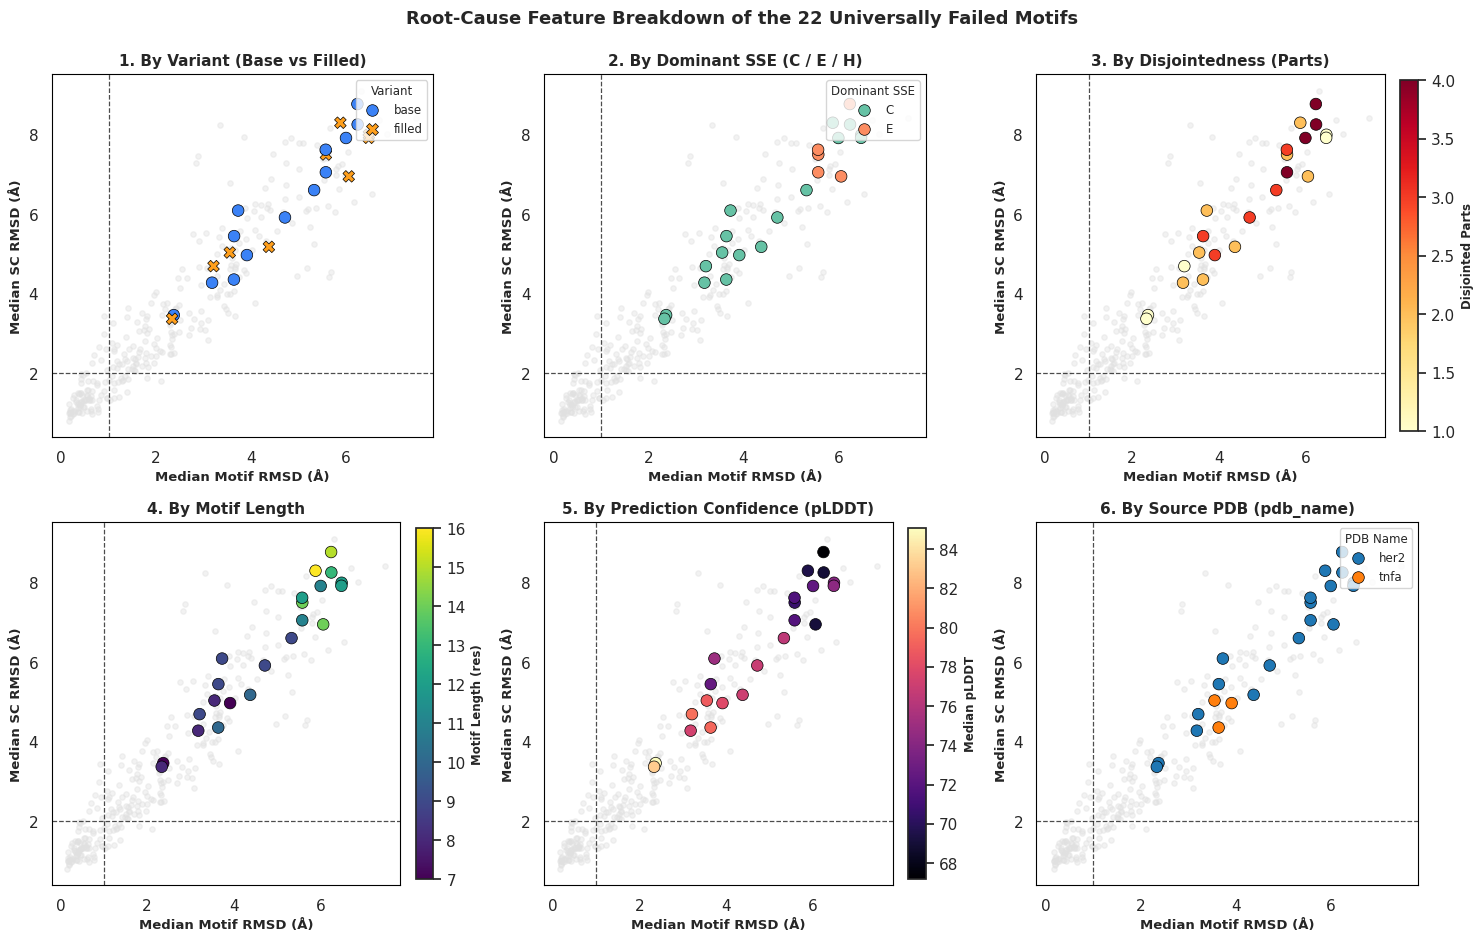

In [58]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ── Setup 6-Panel Figure Grid ──────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
axes = axes.flatten()

# Gate threshold lines
M_GATE = 1.0  # Motif RMSD threshold (Å)
S_GATE = 2.0  # Side-chain RMSD threshold (Å)


def add_gate_overlays(ax):
    """Draw quality gate cutoffs."""
    ax.axvline(M_GATE, ls="--", color="black", lw=0.9, alpha=0.7)
    ax.axhline(S_GATE, ls="--", color="black", lw=0.9, alpha=0.7)
    ax.set_xlabel("Median Motif RMSD (Å)", fontsize=9.5, fontweight="bold")
    ax.set_ylabel("Median SC RMSD (Å)", fontsize=9.5, fontweight="bold")


# Optional background scatter from pool
bg_data = pool_diag if "pool_diag" in globals() else None

# ── PANEL 1: Colored by Variant (Base vs. Filled) ─────────────────────────────
ax1 = axes[0]
if bg_data is not None:
    ax1.scatter(
        bg_data["motifRMSD_med"],
        bg_data["scRMSD_med"],
        c="#e0e0e0",
        s=15,
        alpha=0.4,
        zorder=1,
    )

sns.scatterplot(
    data=failed_tbl,
    x="motifRMSD_med",
    y="scRMSD_med",
    hue="variant",
    style="variant",
    palette={"base": "#3b82f6", "filled": "#ff9f1c"},
    s=70,
    edgecolor="black",
    linewidth=0.5,
    ax=ax1,
    zorder=2,
)
add_gate_overlays(ax1)
ax1.set_title("1. By Variant (Base vs Filled)", fontsize=11, fontweight="bold")
ax1.legend(title="Variant", fontsize=8.5, title_fontsize=8.5, loc="upper right")

# ── PANEL 2: Colored by Dominant SSE ──────────────────────────────────────────
ax2 = axes[1]
if bg_data is not None:
    ax2.scatter(
        bg_data["motifRMSD_med"],
        bg_data["scRMSD_med"],
        c="#e0e0e0",
        s=15,
        alpha=0.4,
        zorder=1,
    )

sns.scatterplot(
    data=failed_tbl,
    x="motifRMSD_med",
    y="scRMSD_med",
    hue="dominant_sse",
    palette="Set2",
    s=70,
    edgecolor="black",
    linewidth=0.5,
    ax=ax2,
    zorder=2,
)
add_gate_overlays(ax2)
ax2.set_title(
    "2. By Dominant SSE (C / E / H)", fontsize=11, fontweight="bold"
)
ax2.legend(
    title="Dominant SSE", fontsize=8.5, title_fontsize=8.5, loc="upper right"
)

# ── PANEL 3: Colored by Disjointed Parts ──────────────────────────────────────
ax3 = axes[2]
if bg_data is not None:
    ax3.scatter(
        bg_data["motifRMSD_med"],
        bg_data["scRMSD_med"],
        c="#e0e0e0",
        s=15,
        alpha=0.4,
        zorder=1,
    )

sc3 = ax3.scatter(
    failed_tbl["motifRMSD_med"],
    failed_tbl["scRMSD_med"],
    c=failed_tbl["disjointed_parts"],
    cmap="YlOrRd",
    s=70,
    edgecolor="black",
    linewidth=0.5,
    zorder=2,
)
add_gate_overlays(ax3)
cbar3 = fig.colorbar(sc3, ax=ax3, fraction=0.046, pad=0.04)
cbar3.set_label("Disjointed Parts", fontsize=8.5, fontweight="bold")
ax3.set_title("3. By Disjointedness (Parts)", fontsize=11, fontweight="bold")

# ── PANEL 4: Colored by Motif Length ──────────────────────────────────────────
ax4 = axes[3]
if bg_data is not None:
    ax4.scatter(
        bg_data["motifRMSD_med"],
        bg_data["scRMSD_med"],
        c="#e0e0e0",
        s=15,
        alpha=0.4,
        zorder=1,
    )

sc4 = ax4.scatter(
    failed_tbl["motifRMSD_med"],
    failed_tbl["scRMSD_med"],
    c=failed_tbl["motif_length"],
    cmap="viridis",
    s=70,
    edgecolor="black",
    linewidth=0.5,
    zorder=2,
)
add_gate_overlays(ax4)
cbar4 = fig.colorbar(sc4, ax=ax4, fraction=0.046, pad=0.04)
cbar4.set_label("Motif Length (res)", fontsize=8.5, fontweight="bold")
ax4.set_title("4. By Motif Length", fontsize=11, fontweight="bold")

# ── PANEL 5: Colored by Median pLDDT ──────────────────────────────────────────
ax5 = axes[4]
if bg_data is not None:
    ax5.scatter(
        bg_data["motifRMSD_med"],
        bg_data["scRMSD_med"],
        c="#e0e0e0",
        s=15,
        alpha=0.4,
        zorder=1,
    )

sc5 = ax5.scatter(
    failed_tbl["motifRMSD_med"],
    failed_tbl["scRMSD_med"],
    c=failed_tbl["plddt_med"],
    cmap="magma",
    s=70,
    edgecolor="black",
    linewidth=0.5,
    zorder=2,
)
add_gate_overlays(ax5)
cbar5 = fig.colorbar(sc5, ax=ax5, fraction=0.046, pad=0.04)
cbar5.set_label("Median pLDDT", fontsize=8.5, fontweight="bold")
ax5.set_title(
    "5. By Prediction Confidence (pLDDT)", fontsize=11, fontweight="bold"
)

# ── PANEL 6: Colored by PDB Name ──────────────────────────────────────────────
ax6 = axes[5]
if bg_data is not None:
    ax6.scatter(
        bg_data["motifRMSD_med"],
        bg_data["scRMSD_med"],
        c="#e0e0e0",
        s=15,
        alpha=0.4,
        zorder=1,
    )

sns.scatterplot(
    data=failed_tbl,
    x="motifRMSD_med",
    y="scRMSD_med",
    hue="pdb_name",
    palette="tab10",
    s=70,
    edgecolor="black",
    linewidth=0.5,
    ax=ax6,
    zorder=2,
)
add_gate_overlays(ax6)
ax6.set_title("6. By Source PDB (pdb_name)", fontsize=11, fontweight="bold")
ax6.legend(
    title="PDB Name",
    fontsize=8.5,
    title_fontsize=8.5,
    loc="upper right",
    ncol=1 if len(failed_tbl["pdb_name"].unique()) <= 6 else 2,
)

# ── Clean Spines & Layout ────────────────────────────────────────────────
for ax in axes:
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor("black")
        spine.set_linewidth(0.8)

fig.suptitle(
    f"Root-Cause Feature Breakdown of the {len(failed_tbl)} Universally Failed Motifs",
    fontsize=13,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout()
plt.show()

## 21 · Per-task designability breakdown (La-Proteina Fig-7 style)


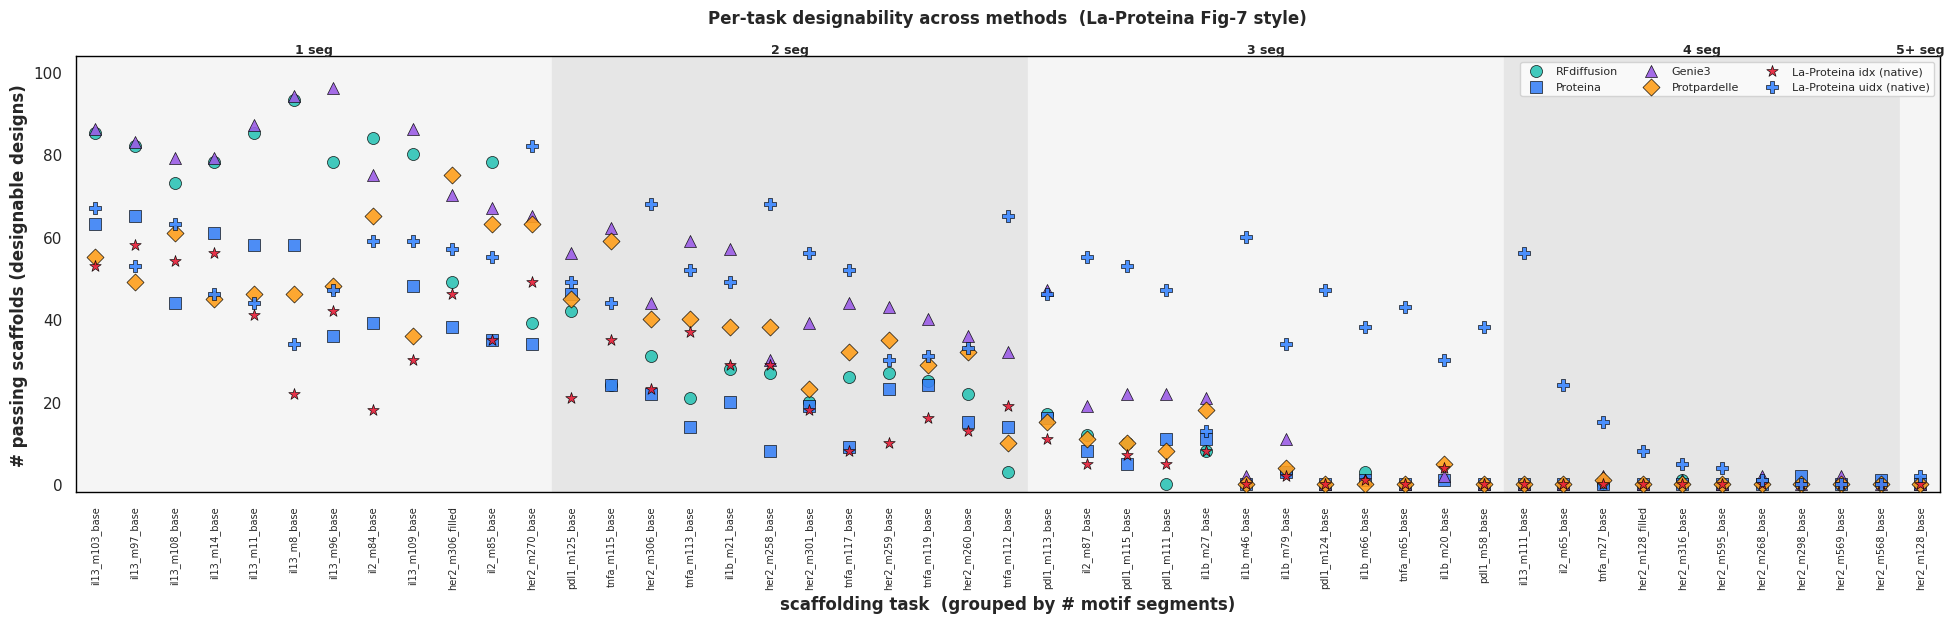

47 tasks shown (<= 12/segment-group); methods: rfdiff, proteina, genie3, pp1c_bb, laproteina, laproteina_unindexed
tasks solved (>=1 passing scaffold) per method, of those shown:
method
rfdiff                  31
proteina                34
genie3                  37
pp1c_bb                 32
laproteina              32
laproteina_unindexed    44


In [17]:
# ── §21 · Per-task designability breakdown across methods (La-Proteina Fig-7 style) ──────────────
# x-axis  = individual scaffolding tasks from the BASELINE run, GROUPED by motif disjointedness
#           (# segments, 1..5; single 5-segment motif). Task names printed on the axis.
# y-axis  = # PASSING scaffolds for that task (designable designs: motifRMSD<=1 & scRMSD<=2 & rank>=0.75).
# marker  = method (toggle SHOW_METHODS to pick which methods appear).
# NOTE on "unique": La-Proteina reports UNIQUE successes — successful designs first clustered by structure
# (Foldseek/TM) so near-duplicate solutions count once. Here we plot the raw count of passing scaffolds;
# feeding these through the Foldseek clustering (see the foldseek analysis) converts this to unique-success
# counts. The x-axis / grouping / per-method markers mirror La-Proteina Fig. 7.
SHOW_METHODS = ['rfdiff','proteina','genie3','pp1c_bb','laproteina','laproteina_unindexed']  # <- edit me
MAX_PER_SEG  = 12          # busiest N tasks per segment-group kept readable (None = every task with >=1 pass)

sm = [m for m in SHOW_METHODS if m in per_design.method.unique()]
succ = (per_design[per_design.method.isin(sm)]
        .groupby(['task_name','method']).designable.sum().rename('n_pass').reset_index())
meta_t = pool.drop_duplicates('task_name').set_index('task_name')
succ['nseg'] = succ.task_name.map(meta_t.disjointed_parts).fillna(1).astype(int).clip(upper=5)
tot = succ.groupby('task_name').n_pass.sum()
succ = succ[succ.task_name.isin(tot[tot > 0].index)]                    # only tasks any selected method solved

order_tasks = []
for seg in sorted(succ.nseg.unique()):
    ts = tot[tot.index.isin(succ[succ.nseg == seg].task_name.unique())].sort_values(ascending=False)
    if MAX_PER_SEG: ts = ts.head(MAX_PER_SEG)
    order_tasks += list(ts.index)
succ = succ[succ.task_name.isin(order_tasks)]
xpos   = {t: i for i, t in enumerate(order_tasks)}
seg_of = {t: int(succ[succ.task_name == t].nseg.iloc[0]) for t in order_tasks}

MARK = {'rfdiff':'o','proteina':'s','genie3':'^','pp1c_bb':'D','laproteina':'*',
        'laproteina_mpnn':'X','laproteina_unindexed':'P','laproteina_unindexed_mpnn':'v'}
fig, ax = plt.subplots(figsize=(max(11, 0.42*len(order_tasks)), 6.4))
ymax = max(1, succ.n_pass.max())
for i, seg in enumerate(sorted(set(seg_of.values()))):
    idx = [xpos[t] for t in order_tasks if seg_of[t] == seg]
    if not idx: continue
    lo, hi = min(idx)-0.5, max(idx)+0.5
    ax.axvspan(lo, hi, color=('0.96' if i % 2 == 0 else '0.90'), zorder=0)
    ax.annotate(f'{seg}' + ('+' if seg == 5 else '') + ' seg', ((lo+hi)/2, 1.0),
                xycoords=('data','axes fraction'), ha='center', va='bottom', fontsize=9, fontweight='bold')
for m in sm:
    d = succ[succ.method == m]
    ax.scatter([xpos[t] for t in d.task_name], d.n_pass, marker=MARK.get(m,'o'), s=75,
               color=PALETTE.get(m,'#333'), edgecolor='black', linewidth=.5,
               label=LABELS.get(m, m), alpha=.9, zorder=3)
ax.set_xticks(range(len(order_tasks))); ax.set_xticklabels(order_tasks, rotation=90, fontsize=7)
ax.set_ylabel('# passing scaffolds (designable designs)', fontweight='bold')
ax.set_xlabel('scaffolding task  (grouped by # motif segments)', fontweight='bold')
ax.set_title('Per-task designability across methods  (La-Proteina Fig-7 style)', fontweight='bold', pad=24)
ax.set_xlim(-0.5, len(order_tasks)-0.5); ax.set_ylim(-0.02*ymax, ymax*1.08)
ax.legend(frameon=True, fontsize=8, ncol=3, loc='upper right')
try: prettify(ax)
except Exception: pass
plt.tight_layout(); plt.show()

print(f"{len(order_tasks)} tasks shown (<= {MAX_PER_SEG}/segment-group); methods: {', '.join(sm)}")
print("tasks solved (>=1 passing scaffold) per method, of those shown:")
print(succ[succ.n_pass > 0].groupby('method').task_name.nunique().reindex(sm).fillna(0).astype(int).to_string())


1-seg diversified picks (2/protein, spread across SSE):
  her2: her2_m306_filled[C], her2_m270_base[E]
  il13: il13_m103_base[H], il13_m110_filled[C]
  il1b: il1b_m23_base[C], il1b_m21_filled[E]
  il2: il2_m84_base[H], il2_m54_base[C]
  pdl1: pdl1_m49_base[C], pdl1_m60_base[E]
  tnfa: tnfa_m147_base[H], tnfa_m145_base[C]


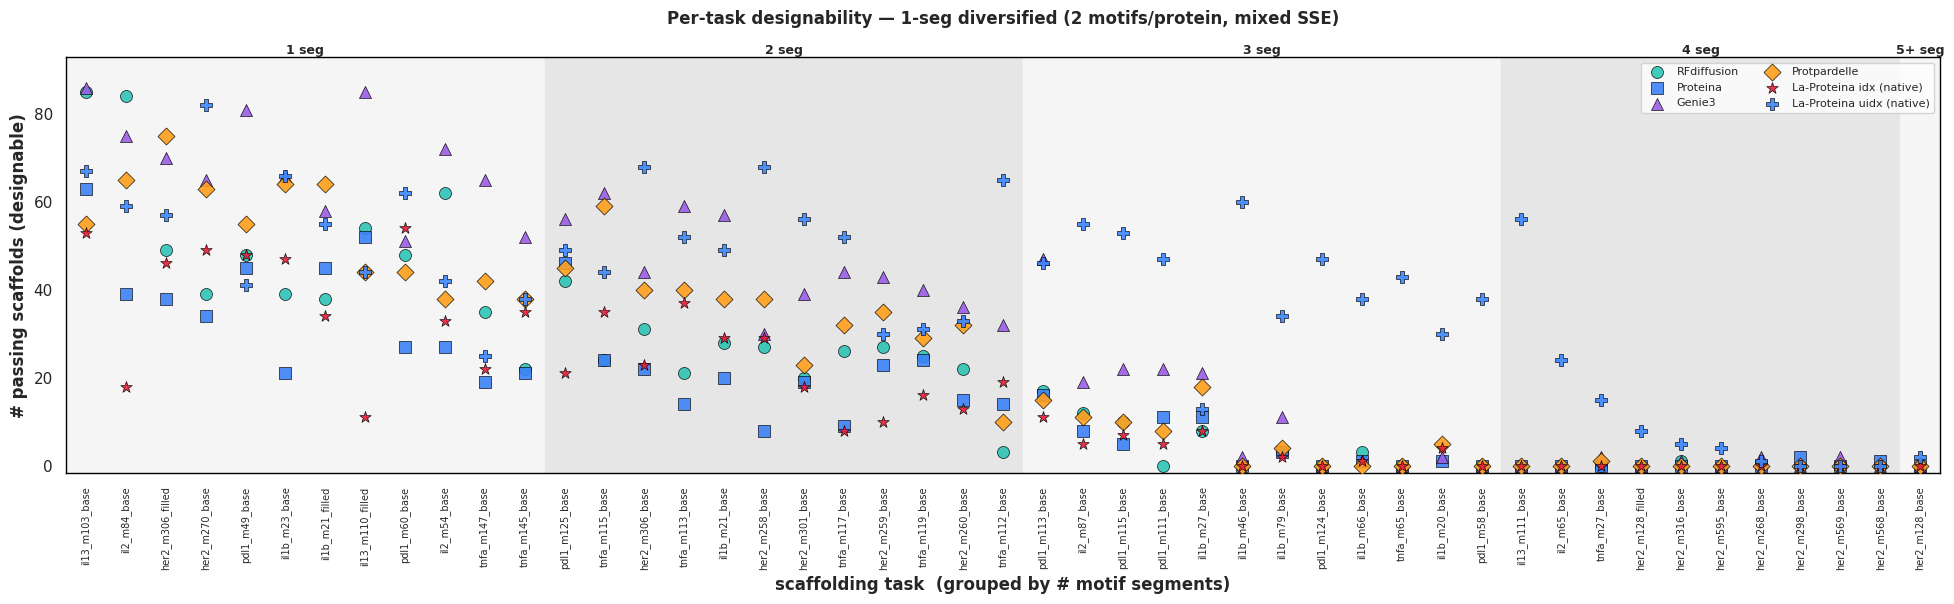

  her2: her2_m301_filled[C], her2_m270_base[E]
  il13: il13_m8_base[H], il13_m110_filled[C]
  il1b: il1b_m32_base[H], il1b_m21_filled[E]
  il2: il2_m101_base[H], il2_m54_base[C]
  pdl1: pdl1_m49_base[C], pdl1_m60_base[E]
  tnfa: tnfa_m108_base[C], tnfa_m147_base[H]


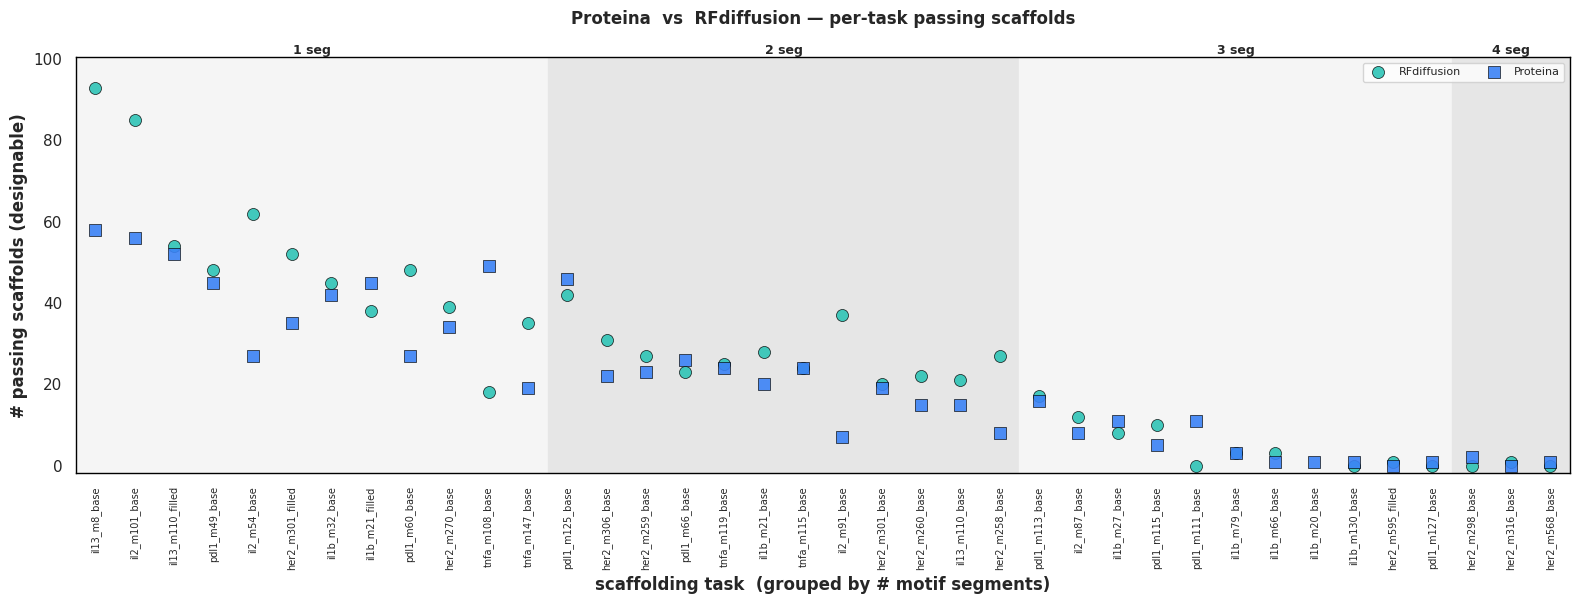

  her2: her2_m301_filled[C], her2_m596_base[E]
  il13: il13_m8_base[H], il13_m110_filled[C]
  il1b: il1b_m23_base[C], il1b_m32_base[H]
  il2: il2_m101_base[H], il2_m54_base[C]
  pdl1: pdl1_m49_base[C], pdl1_m60_base[E]
  tnfa: tnfa_m147_base[H], tnfa_m145_base[C]


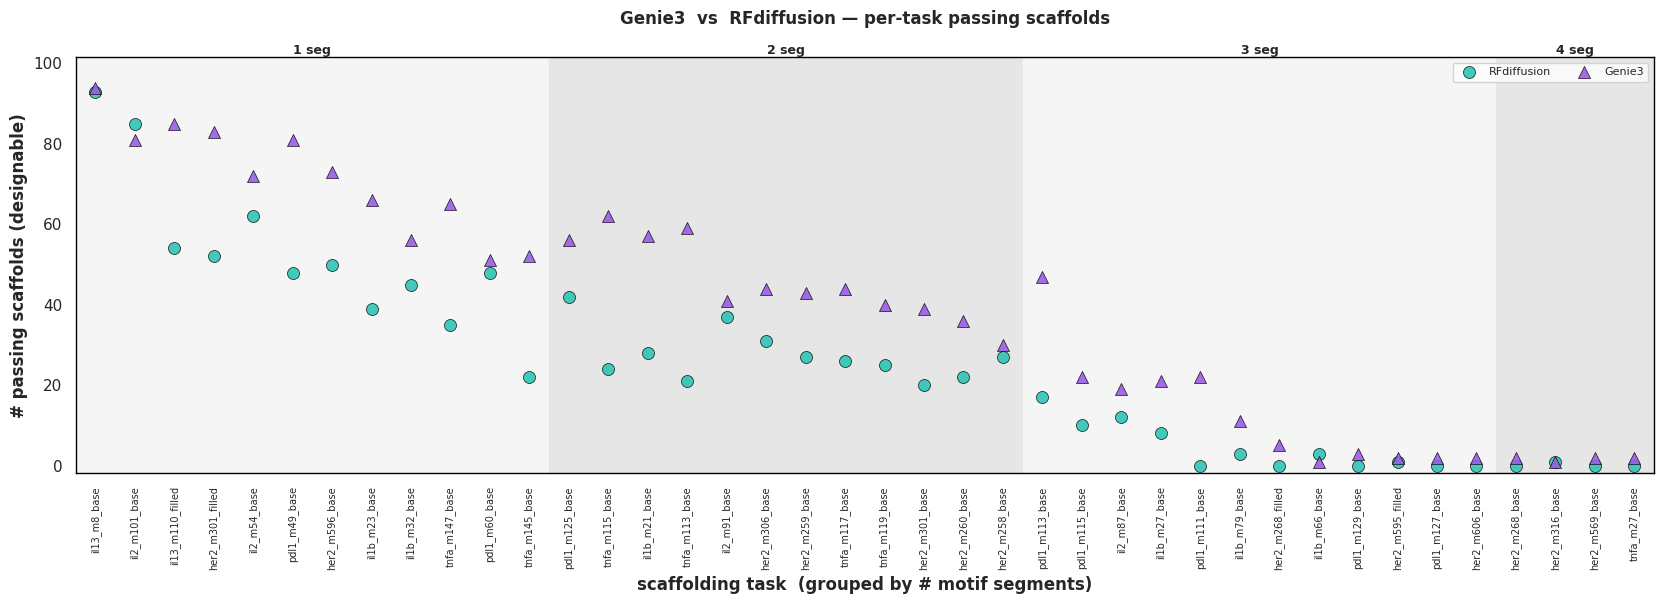

  her2: her2_m306_filled[C], her2_m239_base[E]
  il13: il13_m103_base[H], il13_m110_filled[C]
  il1b: il1b_m23_base[C], il1b_m21_filled[E]
  il2: il2_m84_base[H], il2_m54_base[C]
  pdl1: pdl1_m71_base[C], pdl1_m62_base[E]
  tnfa: tnfa_m147_base[H], tnfa_m145_base[C]


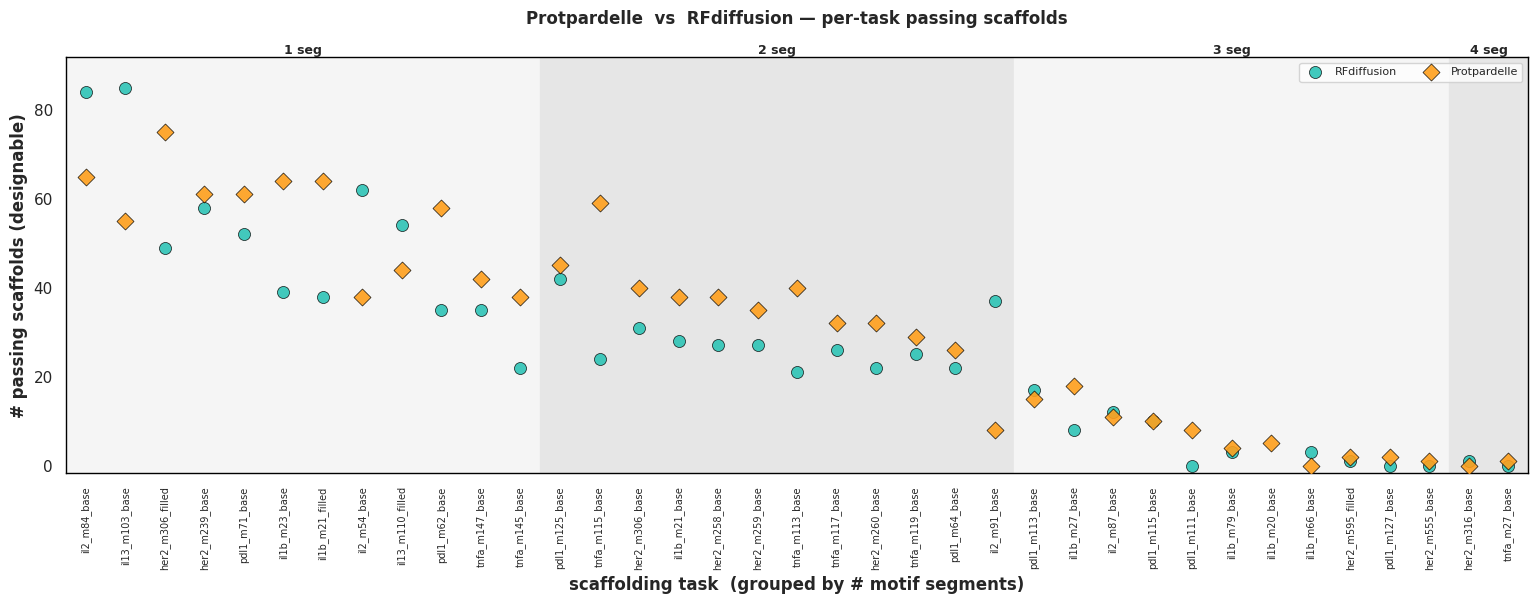

  her2: her2_m239_base[E], her2_m301_filled[C]
  il13: il13_m97_base[H], il13_m110_filled[C]
  il1b: il1b_m22_base[C], il1b_m32_base[H]
  il2: il2_m101_base[H], il2_m54_base[C]
  pdl1: pdl1_m71_base[C], pdl1_m60_base[E]
  tnfa: tnfa_m145_base[C], tnfa_m147_base[H]


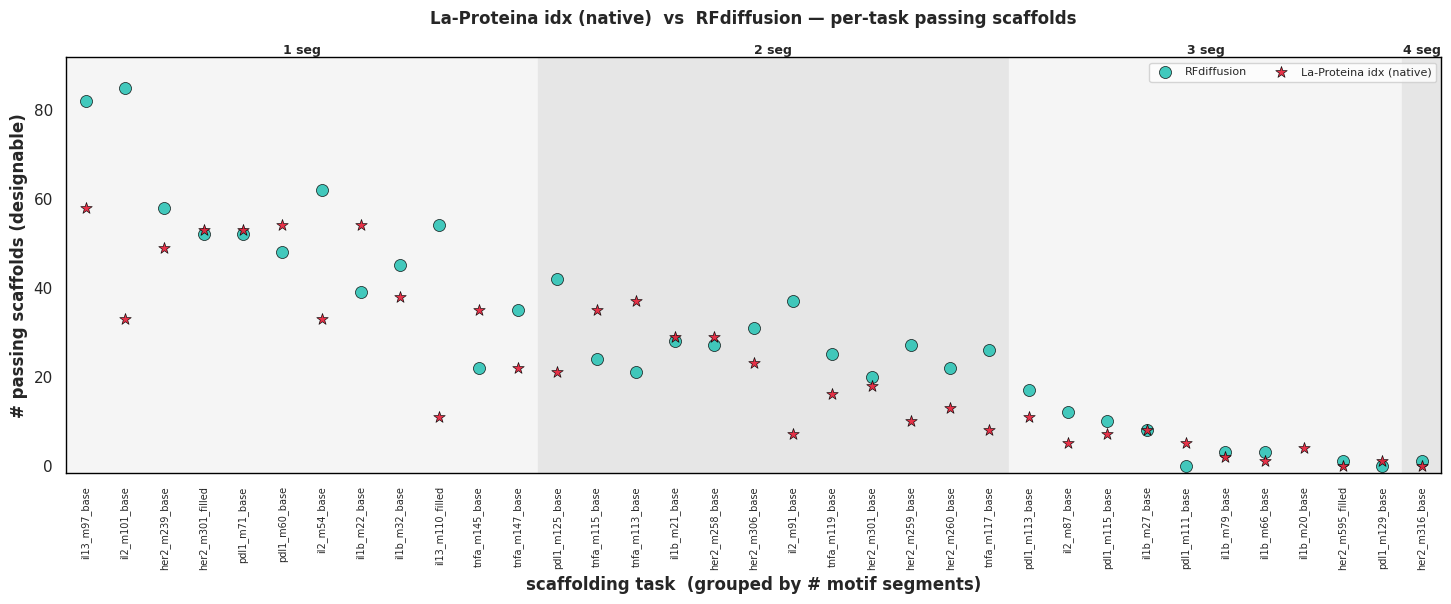

  her2: her2_m239_base[E], her2_m258_filled[C]
  il13: il13_m108_base[H], il13_m110_filled[C]
  il1b: il1b_m22_base[C], il1b_m32_base[H]
  il2: il2_m101_base[H], il2_m54_base[C]
  pdl1: pdl1_m60_base[E], pdl1_m49_base[C]
  tnfa: tnfa_m145_base[C], tnfa_m147_base[H]


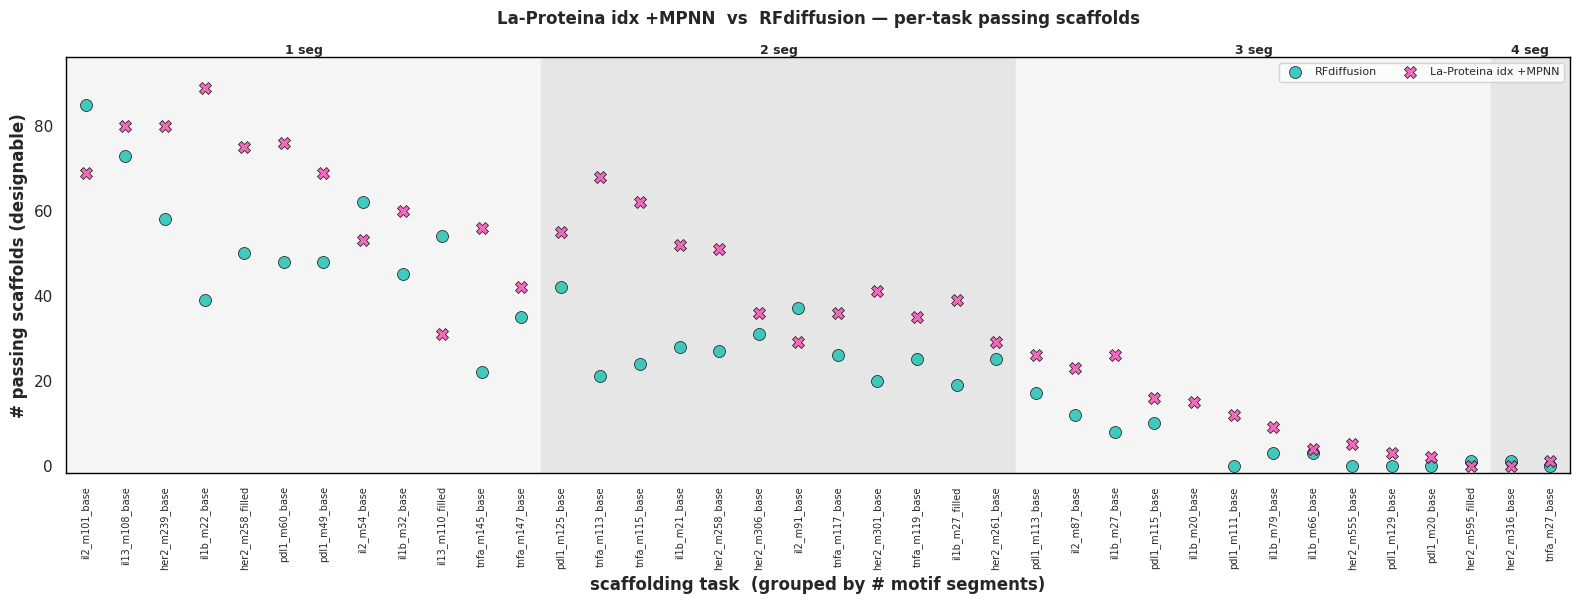

  her2: her2_m239_base[E], her2_m598_base[C]
  il13: il13_m103_base[H], il13_m110_filled[C]
  il1b: il1b_m23_base[C], il1b_m21_filled[E]
  il2: il2_m84_base[H], il2_m54_base[C]
  pdl1: pdl1_m71_base[C], pdl1_m60_base[E]
  tnfa: tnfa_m145_base[C], tnfa_m147_base[H]


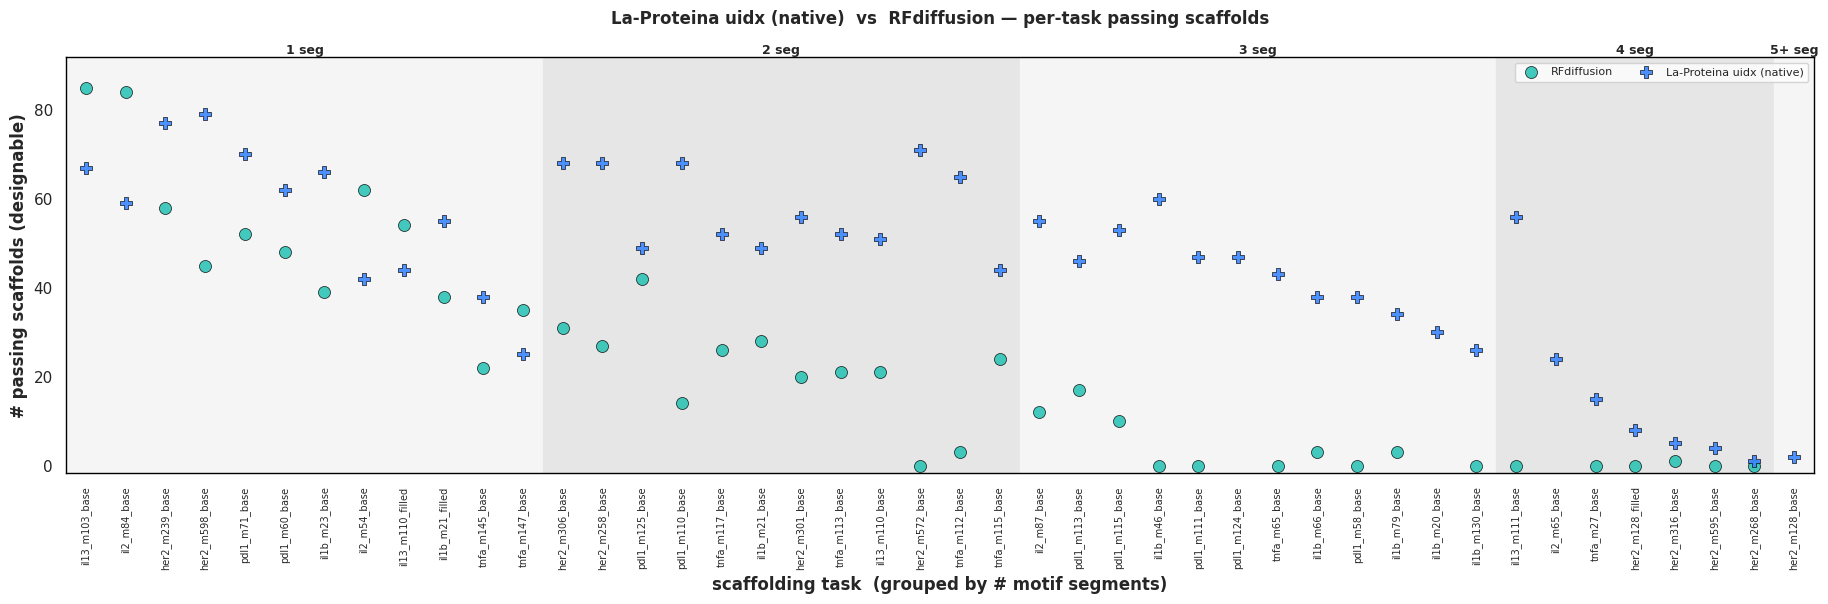

In [46]:
import numpy as np, matplotlib.pyplot as plt

ALL_MARK = {'rfdiff':'o','proteina':'s','genie3':'^','pp1c_bb':'D','laproteina':'*',
            'laproteina_mpnn':'X','laproteina_unindexed':'P','laproteina_unindexed_mpnn':'v'}
meta_t = pool.drop_duplicates('task_name').set_index('task_name')

def _succ_table(show_methods):
    sm = [m for m in show_methods if m in per_design.method.unique()]
    succ = (per_design[per_design.method.isin(sm)]
            .groupby(['task_name','method']).designable.sum().rename('n_pass').reset_index())
    succ['nseg'] = succ.task_name.map(meta_t.disjointed_parts).fillna(1).astype(int).clip(upper=5)
    succ['pdb']  = succ.task_name.map(meta_t.pdb_name)
    succ['sse']  = succ.task_name.map(meta_t.dominant_sse)
    return sm, succ

def _pick_1seg_diverse(succ, tot, per_protein=2, verbose=True):
    # within the 1-segment group: pick `per_protein` motifs PER PROTEIN, round-robin across dominant SSE
    # (H/E/C) so the selection isn't all one fold or one protein. Ties broken by total passing scaffolds.
    sub = succ[succ.nseg == 1].drop_duplicates('task_name')[['task_name','pdb','sse']].copy()
    sub['tot'] = sub.task_name.map(tot); sub = sub[sub.tot > 0]
    picks = []
    for pdb, g in sub.groupby('pdb'):
        by_sse = {s: gg.sort_values('tot', ascending=False) for s, gg in g.groupby('sse')}
        if not by_sse: continue
        sse_order = sorted(by_sse, key=lambda s: -by_sse[s].tot.iloc[0])
        chosen, ri = [], 0
        while len(chosen) < per_protein and any(len(by_sse[s]) for s in by_sse):
            s = sse_order[ri % len(sse_order)]
            if len(by_sse[s]):
                row = by_sse[s].iloc[0]; chosen.append(row.task_name)
                by_sse[s] = by_sse[s].iloc[1:]
            ri += 1
        picks += chosen
        if verbose:
            lab = ', '.join(f"{t}[{meta_t.dominant_sse.get(t,'?')}]" for t in chosen)
            print(f"  {pdb}: {lab}")
    return picks

def fig21(show_methods, max_per_seg=12, diversify_1seg=False, per_protein=2, title=None):
    sm, succ = _succ_table(show_methods)
    tot  = succ.groupby('task_name').n_pass.sum()
    succ = succ[succ.task_name.isin(tot[tot > 0].index)]
    order_tasks = []
    for seg in sorted(succ.nseg.unique()):
        if seg == 1 and diversify_1seg:
            picks = _pick_1seg_diverse(succ, tot, per_protein)
            order_tasks += sorted(picks, key=lambda t: -tot[t])
        else:
            ts = tot[tot.index.isin(succ[succ.nseg == seg].task_name.unique())].sort_values(ascending=False)
            order_tasks += list(ts.head(max_per_seg).index if max_per_seg else ts.index)
    succ   = succ[succ.task_name.isin(order_tasks)]
    xpos   = {t: i for i, t in enumerate(order_tasks)}
    seg_of = {t: int(succ[succ.task_name == t].nseg.iloc[0]) for t in order_tasks}

    fig, ax = plt.subplots(figsize=(max(9, 0.42*len(order_tasks)), 6.2))
    ymax = max(1, succ.n_pass.max())
    for i, seg in enumerate(sorted(set(seg_of.values()))):
        idx = [xpos[t] for t in order_tasks if seg_of[t] == seg]
        if not idx: continue
        lo, hi = min(idx)-0.5, max(idx)+0.5
        ax.axvspan(lo, hi, color=('0.96' if i % 2 == 0 else '0.90'), zorder=0)
        ax.annotate(f'{seg}' + ('+' if seg == 5 else '') + ' seg', ((lo+hi)/2, 1.0),
                    xycoords=('data','axes fraction'), ha='center', va='bottom', fontsize=9, fontweight='bold')
    for m in sm:
        d = succ[succ.method == m]
        ax.scatter([xpos[t] for t in d.task_name], d.n_pass, marker=ALL_MARK.get(m,'o'), s=75,
                   color=PALETTE.get(m,'#333'), edgecolor='black', linewidth=.5,
                   label=LABELS.get(m, m), alpha=.9, zorder=3)
    ax.set_xticks(range(len(order_tasks))); ax.set_xticklabels(order_tasks, rotation=90, fontsize=7)
    ax.set_ylabel('# passing scaffolds (designable)', fontweight='bold')
    ax.set_xlabel('scaffolding task  (grouped by # motif segments)', fontweight='bold')
    ax.set_title(title or ('Per-task designability  ' + '  vs  '.join(LABELS.get(m,m) for m in sm)),
                 fontweight='bold', pad=24)
    ax.set_xlim(-0.5, len(order_tasks)-0.5); ax.set_ylim(-0.02*ymax, ymax*1.08)
    ax.legend(frameon=True, fontsize=8, ncol=2, loc='upper right')
    try: prettify(ax)
    except Exception: pass
    plt.tight_layout(); plt.show()
    return order_tasks

# (A) all-method view, but with the 1-segment group DIVERSIFIED: 2 motifs/protein, mixed H/E/C
print('1-seg diversified picks (2/protein, spread across SSE):')
fig21(['rfdiff','proteina','genie3','pp1c_bb','laproteina','laproteina_unindexed'],
      diversify_1seg=True, per_protein=2,
      title='Per-task designability — 1-seg diversified (2 motifs/protein, mixed SSE)')

# (B) one plot per model, each compared head-to-head with RFdiffusion (same diversified selection)
for m in ['proteina','genie3','pp1c_bb','laproteina','laproteina_mpnn',
          'laproteina_unindexed','laproteina_unindexed_mpnn']:
    if m in per_design.method.unique():
        fig21(['rfdiff', m], diversify_1seg=True, per_protein=2,
              title=f'{LABELS.get(m, m)}  vs  RFdiffusion — per-task passing scaffolds')

## 22 · Where does La-Proteina *unindexed* place the motif inside the scaffold?

La-Proteina unindexed is our best end-to-end predictor, but unlike the other methods **we cannot set the scaffold length or flank padding** — the model chooses. So: given that freedom, where does it put the motif in the **designable** case, and for **disjointed** motifs where does it prefer to drop the individual fragments? Hypothesis: lonely / short fragments get pushed to a **terminus**, where the fold is easier.

Positions come from the greedy relocalization (`positions_unindexed.jsonl`); scaffold length `L` = chain-A Cα count of the design; fragments = contiguous runs of motif residues in the scaffold. `frag_center_rel` runs 0 (N-term) → 1 (C-term); `frag_dist_to_end` runs 0 (at a terminus) → 0.5 (dead centre). **Contig-scale** (native flanks) is the comparison — the run whose padding is closest in spirit to what uidx does on its own.

In [47]:
# --- load motif_placement.csv (built by scripts/motif_placement.py, cluster-side) ---
RUN_CS = '/cluster/work/wicky/bekessel/motif_library/runs/lib_interface_pad5_contigscale'
PL_SRC = {
    'laproteina_unindexed':      (RUN_UIDX, 'laproteina'),       # the focus (greedy positions)
    'laproteina_unindexed_mpnn': (RUN_UIDX, 'laproteina_mpnn'),
    'contigscale_rfdiff':        (RUN_CS, 'rfdiff'),
    'contigscale_genie3':        (RUN_CS, 'genie3'),
    'contigscale_pp1c_bb':       (RUN_CS, 'pp1c_bb'),
    'contigscale_laproteina':    (RUN_CS, 'laproteina'),
}
PL_COL = {'laproteina_unindexed':'#3a86ff','laproteina_unindexed_mpnn':'#4361ee',
          'contigscale_rfdiff':'#2ec4b6','contigscale_genie3':'#9b5de5',
          'contigscale_pp1c_bb':'#ff9f1c','contigscale_laproteina':'#e71d36'}
_pf = []
for lbl,(run,sub) in PL_SRC.items():
    f = f'{run}/{sub}/motif_placement.csv'
    if not os.path.exists(f):
        print(f'  MISSING {lbl:28s} -> {f}   (run motif_placement.py first)'); continue
    d = pd.read_csv(f); d['grp'] = lbl
    _pf.append(d)
place = pd.concat(_pf, ignore_index=True)
place = place[place.L > 0].copy()                                     # need a valid scaffold length
place['designable'] = pd.to_numeric(place.designable, errors='coerce').fillna(0).astype(int)
pdz = place.drop_duplicates('design').copy()                         # per-DESIGN (motif-level) frame
gpresent = [g for g in PL_SRC if g in place.grp.unique()]
print('placement fragment-rows:', len(place), '| designs/grp:',
      {g:int((pdz.grp==g).sum()) for g in gpresent})
print('designable designs/grp:',
      {g:int(((pdz.grp==g)&(pdz.designable==1)).sum()) for g in gpresent})

  MISSING laproteina_unindexed_mpnn    -> /cluster/work/wicky/bekessel/motif_library/runs/lib_interface_pad5_uidx/laproteina_mpnn/motif_placement.csv   (run motif_placement.py first)
placement fragment-rows: 85429 | designs/grp: {'laproteina_unindexed': 31288, 'contigscale_pp1c_bb': 5345, 'contigscale_laproteina': 5600}
designable designs/grp: {'laproteina_unindexed': 12646, 'contigscale_pp1c_bb': 205, 'contigscale_laproteina': 420}


/scratch/tmp.12135578.bekessel/ipykernel_2135117/2353469950.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=pdz[pdz.grp.isin(go)], x='grp', y='L', order=go,
/scratch/tmp.12135578.bekessel/ipykernel_2135117/2353469950.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(go, rotation=25, ha='right'); ax.set_xlabel(''); ax.set_ylabel('scaffold length L (residues)')


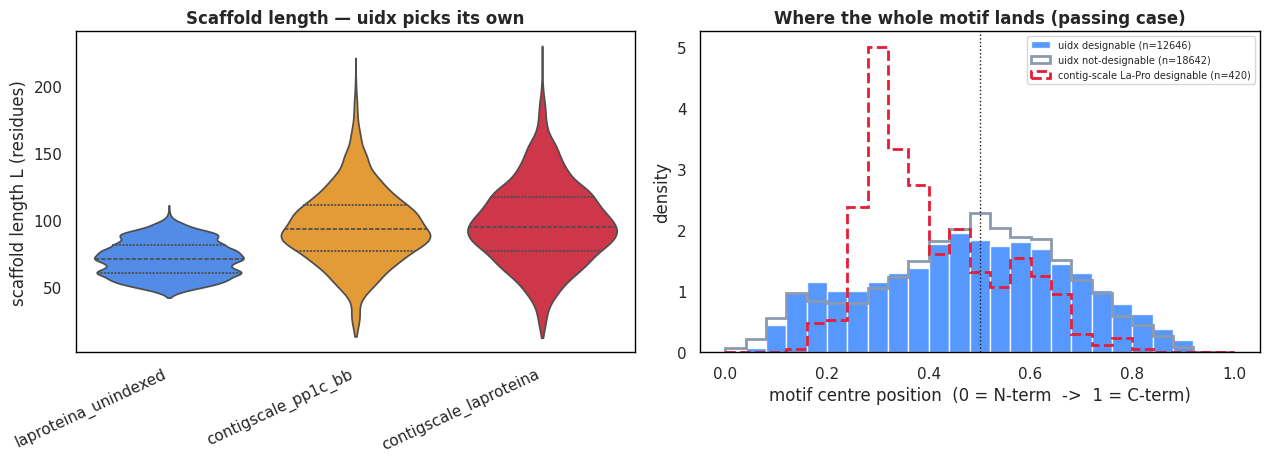

In [48]:
# --- Fig A: scaffold length distribution + where the WHOLE motif sits in the PASSING case ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# (1) scaffold length L per group (per-design)
ax = axes[0]
go = [g for g in gpresent]
sns.violinplot(data=pdz[pdz.grp.isin(go)], x='grp', y='L', order=go,
               palette=[PL_COL[g] for g in go], cut=0, inner='quartile', ax=ax)
ax.set_xticklabels(go, rotation=25, ha='right'); ax.set_xlabel(''); ax.set_ylabel('scaffold length L (residues)')
ax.set_title('Scaffold length — uidx picks its own', fontweight='bold'); prettify(ax)

# (2) whole-motif centre (0=N .. 1=C): uidx PASSING vs non-passing (+ contig-scale La-Pro passers as reference)
ax = axes[1]
u = pdz[pdz.grp == 'laproteina_unindexed']
bins = np.linspace(0, 1, 26)
ax.hist(u.loc[u.designable==1,'motif_center_rel'].dropna(), bins=bins, density=True,
        color='#3a86ff', alpha=0.85, label=f'uidx designable (n={int((u.designable==1).sum())})')
ax.hist(u.loc[u.designable==0,'motif_center_rel'].dropna(), bins=bins, density=True,
        histtype='step', lw=2, color='#8d99ae', label=f'uidx not-designable (n={int((u.designable==0).sum())})')
cs = pdz[(pdz.grp=='contigscale_laproteina') & (pdz.designable==1)]
if len(cs):
    ax.hist(cs.motif_center_rel.dropna(), bins=bins, density=True, histtype='step', lw=2, ls='--',
            color='#e71d36', label=f'contig-scale La-Pro designable (n={len(cs)})')
ax.axvline(0.5, color='k', ls=':', lw=1)
ax.set_xlabel('motif centre position  (0 = N-term  ->  1 = C-term)'); ax.set_ylabel('density')
ax.set_title('Where the whole motif lands (passing case)', fontweight='bold'); ax.legend(fontsize=7); prettify(ax)
plt.tight_layout(); plt.show()

disjoint designable uidx fragments: 14494 | by size: 1 (lonely)=2403, 2-4 (short)=7260, >=5 (long)=4831


/scratch/tmp.12135578.bekessel/ipykernel_2135117/282727168.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=uf, x='flcat', y='frag_dist_to_end', order=order,


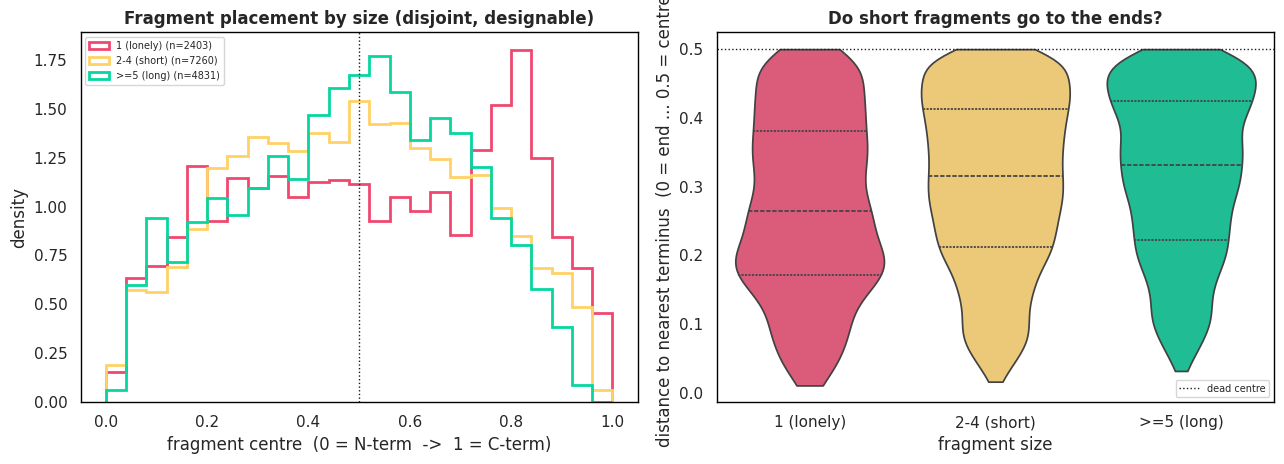

In [49]:
# --- Fig B: for DISJOINTED motifs (n_frag>1), where does uidx put each fragment? (designable only) ---
uf = place[(place.grp=='laproteina_unindexed') & (place.n_frag > 1) & (place.designable==1)].copy()
def flcat(n): return '1 (lonely)' if n==1 else ('2-4 (short)' if n<=4 else '>=5 (long)')
uf['flcat'] = uf.frag_len.map(flcat)
order = ['1 (lonely)','2-4 (short)','>=5 (long)']
CC = {'1 (lonely)':'#ef476f','2-4 (short)':'#ffd166','>=5 (long)':'#06d6a0'}
print(f'disjoint designable uidx fragments: {len(uf)} | by size: '
      + ', '.join(f"{k}={int((uf.flcat==k).sum())}" for k in order))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# (1) fragment centre position, split by fragment size -- do lonely/short pile up at the ends (0 or 1)?
ax = axes[0]
bins = np.linspace(0, 1, 26)
for k in order:
    v = uf.loc[uf.flcat==k, 'frag_center_rel'].dropna()
    if len(v): ax.hist(v, bins=bins, density=True, histtype='step', lw=2, color=CC[k], label=f'{k} (n={len(v)})')
ax.axvline(0.5, color='k', ls=':', lw=1)
ax.set_xlabel('fragment centre  (0 = N-term  ->  1 = C-term)'); ax.set_ylabel('density')
ax.set_title('Fragment placement by size (disjoint, designable)', fontweight='bold'); ax.legend(fontsize=7); prettify(ax)

# (2) distance-to-nearest-terminus vs fragment size -- hypothesis: short fragments sit closer to an end
ax = axes[1]
sns.violinplot(data=uf, x='flcat', y='frag_dist_to_end', order=order,
               palette=[CC[k] for k in order], cut=0, inner='quartile', ax=ax)
ax.axhline(0.5, color='k', ls=':', lw=1, label='dead centre')
ax.set_xlabel('fragment size'); ax.set_ylabel('distance to nearest terminus  (0 = end ... 0.5 = centre)')
ax.set_title('Do short fragments go to the ends?', fontweight='bold'); ax.legend(fontsize=7); prettify(ax)
plt.tight_layout(); plt.show()